<a href="https://colab.research.google.com/github/LR-Lemon/Milestone-II/blob/main/notebooks/02_model_a_volatility_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Model A: Supervised Volatility Forecasting

## Overarching Research Question

**Can supervised learning forecast future S&P 500 realized volatility, and does incorporating HMM-inferred market regime information improve forecasting performance beyond conventional market indicators?**

## Notebook Objective

This notebook develops and evaluates supervised learning models to forecast **forward 5, 10, and 20 day realized volatility** of the S&P 500 using historical market indicators and market regime probabilities generated by Model B.

Three supervised approaches:**Ridge Regression, Support Vector Regression (SVR), and XGBoost** are compared against a naive volatility persistence benchmark. Each model is evaluated using conventional market indicators, both independently and supplemented by the filtered probabilities of Calm, Transition, and Stressed market regimes.

The analysis covers 2000–2025, with 2000–2018 used for training, 2019–2021 for validation, and 2022–2025 for out-of-sample testing. Forecasting performance is evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE), alongside robustness and sensitivity analyses.

## Notebook Structure

| Section | General Question Addressed | Figures Produced |
|---|---|---|
| **1. Environment Setup and Data Loading** | What tools and datasets are required for supervised volatility forecasting? | None |
| **2. Data Integrity and Integration** | Are the engineered market indicators and HMM regime probabilities complete, consistent, and correctly aligned? | None |
| **3. Forward Volatility Target Engineering** | How are forward 5, 10, and 20 day realized-volatility targets constructed and characterized? | Target distribution and time-series figures |
| **4. Supervised Modeling Dataset Preparation** | How are predictors selected, standardized, and chronologically partitioned for model estimation and evaluation? | Predictor correlation and data partition figures |
| **5. Persistence Benchmark** | How accurately does historical volatility predict future volatility without additional modeling? | Benchmark evaluation figures |
| **6. Ridge Regression** | How effectively does a regularized linear model forecast realized volatility, and does regime information improve its performance? | `fig_ridge_forecasts` |
| **7. Support Vector Regression (SVR)** | Can a nonlinear kernel-based approach improve volatility forecasts, particularly when incorporating market regime probabilities? | `fig_svr_forecasts` |
| **8. XGBoost Regression** | Can gradient-boosted decision trees capture nonlinear relationships and improve forecasting accuracy? | `fig_xgb_forecasts` |
| **9. Cross Model Comparison and Evaluation** | Which models perform best across forecasting horizons, and does incorporating HMM probabilities provide additional predictive value? | `fig_model_comparison`, `fig_hmm_contribution`, `fig_event_comparison` |
| **10. Robustness and Sensitivity Analysis** | How stable are forecasting results across historical periods, hyperparameters, predictor specifications, and market stress episodes? | `fig_cv_performance`, `fig_parameter_sensitivity`, `fig_feature_ablation`, `fig_stress_robustness`, `fig_forecast_error_diagnostics` |
| **11. Final Conclusions** | What do the results establish about forecasting performance, regime information, and methodological limitations? | None |

## Notebook Outputs and Integration with Model B

The notebook produces a **6,499-observation supervised modeling dataset** containing historical market indicators, filtered HMM regime probabilities, and forward realized-volatility targets for 5, 10, and 20 day forecasting horizons.

The persistence benchmark, Ridge Regression, SVR, and XGBoost models generate forecasts that are evaluated across different horizons and predictor specifications. Comparative RMSE and MAE results are used to assess forecasting accuracy and determine whether incorporating market regime information improves performance.

Model A builds directly on Model B by incorporating the **filtered probabilities** of Calm, Transition, and Stressed regimes as additional forecasting features. This allows the project to assess whether economically interpretable market regimes also provide incremental predictive value.

Filtered probabilities are based on observations available through each trading date, conditional on the fitted HMM parameters. However, the integrated HMM features use parameters estimated from the full historical sample. Consequently, regime-enhanced forecasting results should be interpreted as exploratory rather than fully leakage-free out-of-sample evidence.

The final Parquet dataset, evaluation tables, and analytical figures are exported through the notebook's Misc section.


---------------------------------------------------------

## Section 1 - Environment Setup and Data Loading

This section establishes the computational environment and loads
the datasets required for supervised volatility forecasting.

The preparation process includes:

- **Repository initialization:** Accessing the standardized GitHub
  project directory within Google Colab.
- **Dependency management:** Installing the required Python libraries
  from the project's `requirements.txt` file.
- **Library imports:** Loading packages required for preprocessing,
  supervised model estimation, statistical evaluation, and visualization.
- **Dataset loading:** Importing the engineered market features and
  filtered HMM regime probabilities generated by Model B.
- **Data inspection:** Verifying dataset dimensions, variable types,
  observation dates, and missing values before model development.

The two input datasets provide historical market characteristics
and inferred market regime information for forecasting forward
S&P 500 realized volatility over 5, 10, and 20 trading days.

This section establishes a reproducible modeling environment
while ensuring consistency with the outputs produced by
Part 0: Feature Engineering and Model B: Market Regime Identification.

### Section 1.1 - Repository Configuration and Dependencies

In [ ]:
# --------------------------------------------------
# 1.1 Repository Configuration and Dependencies
# --------------------------------------------------

import sys
import subprocess
from pathlib import Path

# GitHub repository configuration
REPO_URL = "https://github.com/LR-Lemon/Milestone-II.git"
PROJECT_ROOT = Path("/content/Milestone-II")

# Clone repository if it does not already exist
if not (PROJECT_ROOT / ".git").exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
        check=True
    )

# Install project dependencies
requirements_path = PROJECT_ROOT / "requirements.txt"

if not requirements_path.is_file():
    raise FileNotFoundError(
        f"Requirements file not found: {requirements_path}"
    )

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-r",
        str(requirements_path)
    ],
    check=True
)

# Record repository version
git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

# Display environment information
print("Environment setup completed successfully.\n")
print("Project root:", PROJECT_ROOT)
print("Python version:", sys.version.split()[0])
print("Git commit:", git_commit)
print("Requirements file:", requirements_path)

Environment setup completed successfully.

Project root: /content/Milestone-II
Python version: 3.13.16
Git commit: 9000b6226e0d3ee8d9c3ca5b07f1c34d10743b88
Requirements file: /content/Milestone-II/requirements.txt


### Section 1.2 - Import Required Libraries

In [ ]:
# --------------------------------------------------
# 1.2 Import Required Libraries
# --------------------------------------------------

# Numerical computation and data manipulation
import numpy as np
import pandas as pd
from itertools import product

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns

# Reproducibility
from pathlib import Path
from matplotlib.figure import Figure

# Feature preprocessing and model pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Supervised learning: Ridge Regression
from sklearn.linear_model import Ridge

# Supervised learning: Support Vector Regression
from sklearn.svm import SVR

# Supervised learning: XGBoost
from xgboost import XGBRegressor

# Model selection and time-series cross-validation
from sklearn.model_selection import (
    ParameterGrid,
    TimeSeriesSplit
)

# Forecast evaluation
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# Statistical inference
import statsmodels.api as sm

# Display preferences
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

### Section 1.3 - Load the Model A Input Datasets

This section loads the two input datasets required for supervised volatility forecasting, produced during the previous stages of the project.

The datasets include:

- **Engineered Market Features:** The complete set of historical S&P 500 and VIX market characteristics developed during Part 0: Feature Engineering.
- **Model B HMM Output:** The market regime classifications and filtered probabilities generated by the Gaussian Hidden Markov Model (HMM).

The initial inspection includes:

- **Dataset dimensions:** Confirming the number of observations and variables.
- **Variable structure:** Examining column names and data types.
- **Temporal coverage:** Identifying the first and last trading dates.
- **Data preview:** Inspecting the initial observations to confirm successful loading.

Both datasets are loaded without modifying their values. Additional integrity checks, date alignment, and feature integration will be performed in Section 2.

These inputs support the evaluation of whether inferred market regime information improves supervised forecasts of forward S&P 500 realized volatility.

In [ ]:
# --------------------------------------------------
# 1.3 Load the Model A Input Datasets
# --------------------------------------------------

# Define dataset paths
MARKET_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "engineered_features"
    / "market_full_features_2000_2025.parquet"
)

HMM_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "regime_features"
    / "model_b_hmm_full_output.parquet"
)

# Verify file availability
for path in [MARKET_DATA_PATH, HMM_DATA_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required dataset not found: {path}"
        )

# Load datasets
market_features = pd.read_parquet(MARKET_DATA_PATH)
hmm_output = pd.read_parquet(HMM_DATA_PATH)

# Display initial dataset information
for name, df in [
    ("Engineered Market Features", market_features),
    ("Model B HMM Output", hmm_output)
]:
    print(f"\n{name} Loaded Successfully")
    print("-" * 50)

    print("Dataset shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nObservation period:")
    print("Start:", df["Date"].min())
    print("End:", df["Date"].max())

    print("\nFirst five observations:")
    display(df.head())


Engineered Market Features Loaded Successfully
--------------------------------------------------
Dataset shape: (6519, 23)

Columns:
['Date', 'SP500_Open', 'SP500_High', 'SP500_Low', 'SP500_Close', 'SP500_Adj_Close', 'SP500_Volume', 'VIX_Open', 'VIX_High', 'VIX_Low', 'VIX_Close', 'SP500_Log_Return', 'VIX_Level', 'VIX_Change', 'Realized_Vol_5D', 'Realized_Vol_10D', 'Realized_Vol_20D', 'Return_Skew_5D', 'Return_Skew_10D', 'Return_Skew_20D', 'Return_Kurt_5D', 'Return_Kurt_10D', 'Return_Kurt_20D']

Data types:
Date                datetime64[ns]
SP500_Open                 float64
SP500_High                 float64
SP500_Low                  float64
SP500_Close                float64
SP500_Adj_Close            float64
SP500_Volume                 int64
VIX_Open                   float64
VIX_High                   float64
VIX_Low                    float64
VIX_Close                  float64
SP500_Log_Return           float64
VIX_Level                  float64
VIX_Change                 floa

,Date,SP500_Open,SP500_High,SP500_Low,SP500_Close,SP500_Adj_Close,SP500_Volume,VIX_Open,VIX_High,VIX_Low,VIX_Close,SP500_Log_Return,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D
0,2000-02-01,"1,394.4600","1,412.4900","1,384.7900","1,409.2800","1,409.2800",981000000,24.4300,24.7400,23.2900,23.4500,0.0106,23.4500,-1.5000,0.3115,0.2548,0.2636,-0.2534,-0.1560,-0.5230,0.3986,0.3141,0.4541
1,2000-02-02,"1,409.2800","1,420.6100","1,403.4900","1,409.1200","1,409.1200",1038600000,23.0200,24.7400,22.6200,23.1200,-0.0001,23.1200,-0.3300,0.3095,0.2546,0.2233,-0.4654,-0.1424,-0.2181,0.8041,0.3277,0.5606
2,2000-02-03,"1,409.1200","1,425.7800","1,398.5200","1,424.9700","1,424.9700",1146500000,22.7200,23.7300,21.9300,22.0100,0.0112,22.0100,-1.1100,0.3137,0.2633,0.2266,-1.1525,-0.4509,-0.2915,1.8414,0.0363,0.3915
3,2000-02-04,"1,424.9700","1,435.9100","1,420.6300","1,424.3700","1,424.3700",1045100000,20.7700,21.7700,20.6900,21.5400,-0.0004,21.5400,-0.4700,0.1649,0.2632,0.2266,0.7997,-0.5077,-0.2753,0.2310,0.0880,0.3819
4,2000-02-07,"1,424.3700","1,427.1500","1,413.3300","1,424.2400","1,424.2400",918100000,22.9700,23.2700,22.7900,22.7900,-0.0001,22.7900,1.2500,0.0965,0.2167,0.2048,0.6123,-0.6333,-0.5036,-3.2962,2.3529,0.8049



Model B HMM Output Loaded Successfully
--------------------------------------------------
Dataset shape: (6519, 17)

Columns:
['Date', 'SP500_Close', 'VIX_Level', 'VIX_Change', 'Realized_Vol_20D', 'Return_Skew_20D', 'Return_Kurt_20D', 'HMM_State', 'Regime', 'P_Calm', 'P_Transition', 'P_Stressed', 'Filtered_P_Calm', 'Filtered_P_Transition', 'Filtered_P_Stressed', 'Regime_Confidence', 'Filtered_Regime_Confidence']

Data types:
Date                          datetime64[ns]
SP500_Close                          float64
VIX_Level                            float64
VIX_Change                           float64
Realized_Vol_20D                     float64
Return_Skew_20D                      float64
Return_Kurt_20D                      float64
HMM_State                              int64
Regime                                object
P_Calm                               float64
P_Transition                         float64
P_Stressed                           float64
Filtered_P_Calm               

,Date,SP500_Close,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D,HMM_State,Regime,P_Calm,P_Transition,P_Stressed,Filtered_P_Calm,Filtered_P_Transition,Filtered_P_Stressed,Regime_Confidence,Filtered_Regime_Confidence
0,2000-02-01,"1,409.2800",23.4500,-1.5000,0.2636,-0.5230,0.4541,2,Transition,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000
1,2000-02-02,"1,409.1200",23.1200,-0.3300,0.2233,-0.2181,0.5606,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9964,0.0036,0.9999,0.9964
2,2000-02-03,"1,424.9700",22.0100,-1.1100,0.2266,-0.2915,0.3915,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9968,0.0032,0.9999,0.9968
3,2000-02-04,"1,424.3700",21.5400,-0.4700,0.2266,-0.2753,0.3819,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9971,0.0029,0.9999,0.9971
4,2000-02-07,"1,424.2400",22.7900,1.2500,0.2048,-0.5036,0.8049,2,Transition,0.0000,1.0000,0.0000,0.0000,0.9993,0.0007,1.0000,0.9993


**Key Observation**

Both input datasets were successfully loaded and inspected.

- **Engineered Market Features:** Contains 6,519 observations and 23 variables, including historical S&P 500 and VIX market information and engineered volatility, skewness, and kurtosis measures.
- **Model B HMM Output:** Contains 6,519 observations and 17 variables, including inferred market regime classifications, regime probabilities, and model confidence measures.
- **Observation period:** Both datasets cover February 1, 2000, through December 31, 2025.
- **Temporal structure:** Both datasets use a datetime-formatted `Date` variable, providing a common key for integration.
- **Regime predictors:** Three filtered probabilities (`Filtered_P_Calm`, `Filtered_P_Transition`, and `Filtered_P_Stressed`) are available for the regime-enhanced forecasting specification.

The initial inspection confirms that both datasets contain the required information for Model A.

The next section will verify data integrity, chronological alignment, and probability consistency before integrating the datasets into a unified modeling framework.

## Section 2 - Data Integrity and Integration

This section validates and integrates the engineered market features and Model B HMM outputs to construct a unified dataset for supervised volatility forecasting.

The validation and integration process includes:

- **Data integrity:** Examining missing values, duplicate observations, and variable types across both datasets.
- **Temporal alignment:** Verifying that market features and HMM outputs correspond to the same trading dates.
- **Probability validation:** Confirming that filtered regime probabilities are within valid bounds and sum to one.
- **Dataset integration:** Merging the three filtered HMM probabilities with the engineered market features.
- **Post-integration verification:** Checking that the merged dataset preserves the expected observations and variable structure.

The resulting dataset will support two forecasting specifications: market-only predictors and market indicators supplemented by filtered HMM regime probabilities.

These checks establish the reliability of the input data before constructing forward realized volatility targets and developing supervised learning models.

### Section 2.1 - Dataset Integrity and Missing Values

The assessment includes:

- **Missing values:** Identifying null observations across all variables.
- **Duplicate records:** Checking for repeated rows and trading dates.
- **Data types:** Verifying that the date and numerical variables have appropriate formats.
- **Numerical validity:** Identifying infinite values in numerical columns.
- **Chronological order:** Confirming that observations are arranged in ascending trading-date order.

In [ ]:
# --------------------------------------------------
# 2.1 Dataset Integrity and Missing Values
# --------------------------------------------------

# Define datasets for validation
datasets = {
    "Engineered Market Features": market_features,
    "Model B HMM Output": hmm_output
}

integrity_results = []

for name, df in datasets.items():

    # Identify numerical columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # Calculate integrity indicators
    missing_values = df.isna().sum()
    infinite_values = np.isinf(df[numeric_cols]).sum()

    duplicate_rows = df.duplicated().sum()
    duplicate_dates = df["Date"].duplicated().sum()

    date_sorted = df["Date"].is_monotonic_increasing
    date_type_valid = pd.api.types.is_datetime64_any_dtype(
        df["Date"]
    )

    # Store results
    integrity_results.append({
        "Dataset": name,
        "Observations": len(df),
        "Variables": df.shape[1],
        "Missing Values": int(missing_values.sum()),
        "Infinite Values": int(infinite_values.sum()),
        "Duplicate Rows": int(duplicate_rows),
        "Duplicate Dates": int(duplicate_dates),
        "Valid Date Type": date_type_valid,
        "Chronologically Sorted": date_sorted
    })

    # Report missing values, if present
    print(f"\n{name}")
    print("-" * 55)

    if missing_values.sum() > 0:
        print("Columns with missing values:")
        display(missing_values[missing_values > 0].to_frame("Count"))
    else:
        print("No missing values detected.")

    # Report infinite values, if present
    if infinite_values.sum() > 0:
        print("\nColumns with infinite values:")
        display(
            infinite_values[infinite_values > 0]
            .to_frame("Count")
        )
    else:
        print("No infinite numerical values detected.")

# Consolidated integrity summary
integrity_summary = pd.DataFrame(integrity_results)

print("\nDataset Integrity Summary")
print("-" * 55)

display(integrity_summary)


Engineered Market Features
-------------------------------------------------------
No missing values detected.
No infinite numerical values detected.

Model B HMM Output
-------------------------------------------------------
No missing values detected.
No infinite numerical values detected.

Dataset Integrity Summary
-------------------------------------------------------


,Dataset,Observations,Variables,Missing Values,Infinite Values,Duplicate Rows,Duplicate Dates,Valid Date Type,Chronologically Sorted
0,Engineered Market Features,6519,23,0,0,0,0,True,True
1,Model B HMM Output,6519,17,0,0,0,0,True,True


### Section 2.2 - Trading Date Alignment

This subsection evaluates the temporal alignment between the Engineered Market Features dataset and the Model B HMM Output.

Although both datasets contain 6,519 observations covering the same period, identical dimensions do not necessarily guarantee that their trading dates match.

The assessment includes:

- **Date coverage:** Comparing the earliest and latest trading dates.
- **Date correspondence:** Identifying observations present in one dataset but absent from the other.
- **Sequential alignment:** Verifying that trading dates correspond in chronological order.
- **Integration readiness:** Confirming that both datasets can be merged using a one-to-one relationship on the `Date` variable.

Successful alignment ensures that the filtered HMM regime probabilities correspond to the correct market observations without introducing mismatched or missing records.

In [ ]:
# --------------------------------------------------
# 2.2 Trading Date Alignment
# --------------------------------------------------

# Extract trading dates
market_dates = pd.DatetimeIndex(market_features["Date"])
hmm_dates = pd.DatetimeIndex(hmm_output["Date"])

# Identify unmatched trading dates
market_only_dates = market_dates.difference(hmm_dates)
hmm_only_dates = hmm_dates.difference(market_dates)

# Verify sequential alignment
dates_match_in_order = market_dates.equals(hmm_dates)

# Consolidated alignment summary
alignment_summary = pd.DataFrame({
    "Validation Check": [
        "Market feature observations",
        "HMM output observations",
        "Market start date",
        "HMM start date",
        "Market end date",
        "HMM end date",
        "Dates exclusive to market features",
        "Dates exclusive to HMM output",
        "Dates match in chronological order"
    ],
    "Result": [
        len(market_dates),
        len(hmm_dates),
        market_dates.min().date(),
        hmm_dates.min().date(),
        market_dates.max().date(),
        hmm_dates.max().date(),
        len(market_only_dates),
        len(hmm_only_dates),
        dates_match_in_order
    ]
})

print("Trading Date Alignment Summary")
print("-" * 55)
display(alignment_summary)

# Display unmatched dates if present
if len(market_only_dates) > 0:
    print("\nDates exclusive to Market Features:")
    display(pd.DataFrame({"Date": market_only_dates}))

if len(hmm_only_dates) > 0:
    print("\nDates exclusive to Model B HMM:")
    display(pd.DataFrame({"Date": hmm_only_dates}))

# Confirm integration readiness
assert len(market_only_dates) == 0, \
    "Market Features contain unmatched trading dates."

assert len(hmm_only_dates) == 0, \
    "HMM Output contains unmatched trading dates."

assert dates_match_in_order, \
    "Trading dates are not aligned in chronological order."

print("\nTrading date alignment verified successfully.")

Trading Date Alignment Summary
-------------------------------------------------------


,Validation Check,Result
0,Market feature observations,6519
1,HMM output observations,6519
2,Market start date,2000-02-01
3,HMM start date,2000-02-01
4,Market end date,2025-12-31
5,HMM end date,2025-12-31
6,Dates exclusive to market features,0
7,Dates exclusive to HMM output,0
8,Dates match in chronological order,True



Trading date alignment verified successfully.


**Key Observations**

- **Observation coverage:** Both datasets contain 6,519 trading dates, spanning February 1, 2000, through December 31, 2025.
- **Unmatched dates:** No trading dates were exclusive to either dataset.
- **Chronological alignment:** Both datasets contain identical trading dates arranged in the same ascending order.
- **Integration readiness:** The datasets support a one-to-one merge using the `Date` variable, without requiring additional date adjustments or exclusions.

These findings establish that the filtered HMM probabilities can be matched to their corresponding market observations without introducing temporal mismatches.

### Section 2.3 - HMM Probability Validation

The assessment focuses on three HMM-derived variables:

- **Filtered_P_Calm:** Filtered probability of the Calm market regime.
- **Filtered_P_Transition:** Filtered probability of the Transition market regime.
- **Filtered_P_Stressed:** Filtered probability of the Stressed market regime.

The validation process includes:

- **Probability bounds:** Confirming that each probability falls between 0 and 1.
- **Probability normalization:** Verifying that the three probabilities sum to approximately 1 for every trading date.
- **Probability completeness:** Confirming that all observations contain valid filtered probabilities.
- **Distribution inspection:** Examining the minimum, maximum, and average probability for each regime.

**Filtered probabilities** are used instead of smoothed probabilities because
the filtering procedure conditions on market observations available up to the corresponding trading date.

This distinction is important for limiting look-ahead bias when using regime probabilities as predictors of future realized volatility.

In [ ]:
# --------------------------------------------------
# 2.3 HMM Probability Validation
# --------------------------------------------------

# Define filtered regime probability columns
filtered_prob_cols = [
    "Filtered_P_Calm",
    "Filtered_P_Transition",
    "Filtered_P_Stressed"
]

# Extract filtered probabilities
filtered_probs = hmm_output[filtered_prob_cols].copy()

# Check probability completeness
missing_probabilities = int(filtered_probs.isna().sum().sum())

# Check probability bounds
out_of_bounds = int(
    ((filtered_probs < 0) | (filtered_probs > 1))
    .any(axis=1)
    .sum()
)

# Calculate row-wise probability sums
probability_sums = filtered_probs.sum(axis=1)

# Numerical tolerance for floating-point calculations
tolerance = 1e-6

# Identify rows with invalid probability sums
invalid_sums = int(
    (~np.isclose(probability_sums, 1.0, atol=tolerance, rtol=0))
    .sum()
)

# Summarize probability distributions
probability_summary = filtered_probs.agg(
    ["mean", "std", "min", "max"]
).T

probability_summary.index.name = "Regime Probability"

print("Filtered HMM Probability Distribution")
print("-" * 55)
display(probability_summary)

# Consolidated validation summary
validation_summary = pd.DataFrame({
    "Validation Check": [
        "Observations assessed",
        "Missing probability values",
        "Observations with out-of-bounds probabilities",
        "Observations with invalid probability sums",
        "Minimum probability sum",
        "Maximum probability sum",
        "Maximum absolute deviation from 1"
    ],
    "Result": [
        len(filtered_probs),
        missing_probabilities,
        out_of_bounds,
        invalid_sums,
        probability_sums.min(),
        probability_sums.max(),
        np.abs(probability_sums - 1).max()
    ]
})

print("\nHMM Probability Validation Summary")
print("-" * 55)
display(validation_summary)

# Assert mathematical consistency
assert missing_probabilities == 0, \
    "Missing filtered HMM probabilities detected."

assert out_of_bounds == 0, \
    "Filtered probabilities outside [0, 1] detected."

assert invalid_sums == 0, \
    "Filtered regime probabilities do not sum to 1."

print("\nFiltered HMM probability validation completed successfully.")

Filtered HMM Probability Distribution
-------------------------------------------------------


,mean,std,min,max
Regime Probability,,,,
Filtered_P_Calm,0.3312,0.4562,0.0000,1.0000
Filtered_P_Transition,0.4177,0.4712,0.0000,1.0000
Filtered_P_Stressed,0.2511,0.4185,0.0000,1.0000



HMM Probability Validation Summary
-------------------------------------------------------


,Validation Check,Result
0,Observations assessed,"6,519.0000"
1,Missing probability values,0.0000
2,Observations with out-of-bounds probabilities,0.0000
3,Observations with invalid probability sums,0.0000
4,Minimum probability sum,1.0000
5,Maximum probability sum,1.0000
6,Maximum absolute deviation from 1,0.0000



Filtered HMM probability validation completed successfully.


**Key Observation**

- **Observations assessed:** 6,519 trading days.
- **Probability completeness:** No missing filtered probability values were detected.
- **Probability bounds:** All probabilities fall within the valid interval of 0 to 1.
- **Probability normalization:** The three filtered probabilities sum to approximately 1 for every observation.
- **Probability distribution:** The Transition regime has the highest average filtered probability (0.4177), followed by Calm (0.3312) and Stressed (0.2511).
- **Probability variation:** Relatively high standard deviations indicate substantial variation in regime probabilities across trading days.

These results confirm that the filtered probabilities are mathematically valid and suitable for integration into Model A.

The three filtered probabilities will be retained as additional predictors in the regime-enhanced forecasting specification. Smoothed probabilities and historical regime labels will not be included in the primary supervised models.

### Section 2.4 - Dataset Integration

This subsection integrates the engineered market features with the filtered HMM regime probabilities generated by Model B.

The integration procedure includes:

- **Feature selection:** Extracting the three filtered regime probabilities from the Model B output.
- **Merge configuration:** Performing a one-to-one merge using the common `Date` variable.
- **Observation preservation:** Retaining the complete set of trading dates from the engineered market-feature dataset.
- **Feature preservation:** Maintaining the original market variables without modifying their values.
- **Integration validation:** Confirming that the merge does not introduce additional observations, duplicate dates, or missing regime probabilities.

Only filtered regime probabilities are incorporated into the supervised dataset. Smoothed probabilities and regime classifications are excluded from the primary predictor specifications.

The resulting dataset provides a common foundation for comparing market-only forecasting models against models supplemented by HMM-derived regime information.

In [ ]:
# --------------------------------------------------
# 2.4 Dataset Integration
# --------------------------------------------------

# Select HMM-derived predictors
hmm_features = hmm_output[
    ["Date"] + filtered_prob_cols
].copy()

# Preserve the original observation count
original_observations = len(market_features)

# Merge market features with filtered HMM probabilities
model_a_df = market_features.merge(
    hmm_features,
    on="Date",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify merge correspondence
merge_summary = model_a_df["_merge"].value_counts()

print("Dataset Integration Summary")
print("-" * 55)

display(
    merge_summary.rename_axis("Merge Status")
    .reset_index(name="Observations")
)

# Confirm no unmatched observations
assert (model_a_df["_merge"] == "both").all(), \
    "Some market observations have no matching HMM probabilities."

# Remove temporary merge indicator
model_a_df = model_a_df.drop(columns="_merge")

# Verify observation preservation
assert len(model_a_df) == original_observations, \
    "Observation count changed during integration."

# Verify date uniqueness
assert model_a_df["Date"].is_unique, \
    "Duplicate trading dates detected after integration."

# Verify regime probability completeness
assert model_a_df[filtered_prob_cols].notna().all().all(), \
    "Missing filtered probabilities detected after integration."

# Display merged dataset information
print("\nIntegrated Model A Dataset")
print("-" * 55)

print("Dataset shape:", model_a_df.shape)
print("Start date:", model_a_df["Date"].min().date())
print("End date:", model_a_df["Date"].max().date())

print("\nFirst five observations:")
display(model_a_df.head())

Dataset Integration Summary
-------------------------------------------------------


,Merge Status,Observations
0,both,6519
1,left_only,0
2,right_only,0



Integrated Model A Dataset
-------------------------------------------------------
Dataset shape: (6519, 26)
Start date: 2000-02-01
End date: 2025-12-31

First five observations:


,Date,SP500_Open,SP500_High,SP500_Low,SP500_Close,SP500_Adj_Close,SP500_Volume,VIX_Open,VIX_High,VIX_Low,VIX_Close,SP500_Log_Return,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D,Filtered_P_Calm,Filtered_P_Transition,Filtered_P_Stressed
0,2000-02-01,"1,394.4600","1,412.4900","1,384.7900","1,409.2800","1,409.2800",981000000,24.4300,24.7400,23.2900,23.4500,0.0106,23.4500,-1.5000,0.3115,0.2548,0.2636,-0.2534,-0.1560,-0.5230,0.3986,0.3141,0.4541,0.0000,1.0000,0.0000
1,2000-02-02,"1,409.2800","1,420.6100","1,403.4900","1,409.1200","1,409.1200",1038600000,23.0200,24.7400,22.6200,23.1200,-0.0001,23.1200,-0.3300,0.3095,0.2546,0.2233,-0.4654,-0.1424,-0.2181,0.8041,0.3277,0.5606,0.0000,0.9964,0.0036
2,2000-02-03,"1,409.1200","1,425.7800","1,398.5200","1,424.9700","1,424.9700",1146500000,22.7200,23.7300,21.9300,22.0100,0.0112,22.0100,-1.1100,0.3137,0.2633,0.2266,-1.1525,-0.4509,-0.2915,1.8414,0.0363,0.3915,0.0000,0.9968,0.0032
3,2000-02-04,"1,424.9700","1,435.9100","1,420.6300","1,424.3700","1,424.3700",1045100000,20.7700,21.7700,20.6900,21.5400,-0.0004,21.5400,-0.4700,0.1649,0.2632,0.2266,0.7997,-0.5077,-0.2753,0.2310,0.0880,0.3819,0.0000,0.9971,0.0029
4,2000-02-07,"1,424.3700","1,427.1500","1,413.3300","1,424.2400","1,424.2400",918100000,22.9700,23.2700,22.7900,22.7900,-0.0001,22.7900,1.2500,0.0965,0.2167,0.2048,0.6123,-0.6333,-0.5036,-3.2962,2.3529,0.8049,0.0000,0.9993,0.0007


**Key Observations:**

- **Matched observations:** All 6,519 market observations were successfully matched with their corresponding HMM outputs.
- **Unmatched observations:** No unmatched trading dates were identified.
- **Dataset dimensions:** The integrated dataset contains 6,519 observations and 26 variables.
- **Feature preservation:** All 23 original market variables were retained without modification.
- **Regime integration:** Three filtered HMM probabilities were added, representing Calm, Transition, and Stressed market conditions.
- **Temporal coverage:** The integrated dataset spans February 1, 2000, through December 31, 2025.

The integration preserves the original market observations while incorporating the regime information required to evaluate its incremental contribution to volatility forecasting.

### Section 2.5 - Integrated Dataset Verification and Summary

This subsection performs a final integrity assessment of the integrated Model A dataset.

The verification process confirms:

- **Observation preservation:** The integrated dataset retains all original trading dates.
- **Feature completeness:** All required market variables and filtered regime probabilities are available.
- **Data integrity:** No missing values, duplicate trading dates, or infinite numerical values were introduced during integration.
- **Probability consistency:** The filtered probabilities continue to sum to approximately one for each observation.
- **Chronological consistency:** The dataset remains ordered by trading date.

Successful verification establishes the integrated dataset as the validated input for forward volatility target engineering.

In [ ]:
# --------------------------------------------------
# 2.5 Integrated Dataset Verification and Summary
# --------------------------------------------------

# Validate numerical values
numeric_cols = model_a_df.select_dtypes(include=[np.number]).columns

# Final dataset checks
final_checks = {
    "Observations": len(model_a_df),
    "Variables": model_a_df.shape[1],
    "Missing Values": int(model_a_df.isna().sum().sum()),
    "Infinite Values": int(
        np.isinf(model_a_df[numeric_cols]).sum().sum()
    ),
    "Duplicate Dates": int(model_a_df["Date"].duplicated().sum()),
    "Chronologically Sorted": model_a_df["Date"].is_monotonic_increasing,
    "Valid HMM Probability Sums": bool(
        np.isclose(
            model_a_df[filtered_prob_cols].sum(axis=1),
            1.0,
            atol=1e-6,
            rtol=0
        ).all()
    )
}

# Display verification summary
final_summary = pd.DataFrame(
    final_checks.items(),
    columns=["Validation Check", "Result"]
)

print("Integrated Dataset Verification Summary")
print("-" * 55)

display(final_summary)

# Validate expected structure
assert len(model_a_df) == len(market_features)
assert model_a_df["Date"].is_unique
assert model_a_df["Date"].is_monotonic_increasing
assert model_a_df.isna().sum().sum() == 0
assert np.isfinite(model_a_df[numeric_cols].to_numpy()).all()
assert final_checks["Valid HMM Probability Sums"]

print("\nIntegrated Model A dataset verified successfully.")

Integrated Dataset Verification Summary
-------------------------------------------------------


,Validation Check,Result
0,Observations,6519
1,Variables,26
2,Missing Values,0
3,Infinite Values,0
4,Duplicate Dates,0
5,Chronologically Sorted,True
6,Valid HMM Probability Sums,True



Integrated Model A dataset verified successfully.


## Section 3 - Forward Volatility Target Engineering

This section constructs the supervised learning targets used to forecast future S&P 500 realized volatility.

Unlike the trailing volatility features developed during Part 0, the forecasting targets measure realized volatility over future trading-day windows.

The target engineering process includes:

- **Forecast horizon definition:** Establishing forward volatility targets over 5, 10, and 20 trading days.
- **Forward volatility calculation:** Computing realized volatility from subsequent S&P 500 daily log returns.
- **Target validation:** Verifying that calculations use future observations without incorporating them into the predictor variables.
- **Missing target assessment:** Identifying observations near the end of the dataset with insufficient future returns.
- **Distribution analysis:** Examining the statistical characteristics of the forward volatility targets.

All targets are calculated consistently across the three forecasting horizons to support direct comparisons between Ridge Regression, Support Vector Regression, and XGBoost.

The resulting targets represent the dependent variables for the supervised forecasting models.

### Section 3.1 - Define Forward Realized Volatility Targets

The forecasting targets are defined as:

- **Forward_RV_5D:** Annualized realized volatility over the next 5 trading days.
- **Forward_RV_10D:** Annualized realized volatility over the next 10 trading days.
- **Forward_RV_20D:** Annualized realized volatility over the next 20 trading days.

The forward targets are constructed independently of the predictors, which are restricted to information available on or before the forecast date.

In [ ]:
# --------------------------------------------------
# 3.1 Define Forward Realized Volatility Targets
# --------------------------------------------------

# Create a copy of the validated integrated dataset
model_a_targets = model_a_df.copy()

# Forecast horizons and annualization factor
FORECAST_HORIZONS = [5, 10, 20]
TRADING_DAYS = 252

# Daily S&P 500 log returns
returns = model_a_targets["SP500_Log_Return"]

# Construct forward realized volatility targets
for horizon in FORECAST_HORIZONS:

    target_col = f"Forward_RV_{horizon}D"

    # Rolling volatility ending at t+h, shifted back to date t
    model_a_targets[target_col] = (
        returns
        .rolling(window=horizon, min_periods=horizon)
        .std(ddof=1)
        .shift(-horizon)
        * np.sqrt(TRADING_DAYS)
    )

# Define target columns
target_cols = [
    f"Forward_RV_{horizon}D"
    for horizon in FORECAST_HORIZONS
]

# Display results
print("Forward Volatility Target Engineering")
print("-" * 55)

print("Dataset shape:", model_a_targets.shape)

display(
    model_a_targets[
        ["Date", "SP500_Log_Return"] + target_cols
    ].head(10)
)

print("\nMissing target observations:")
display(model_a_targets[target_cols].isna().sum())

Forward Volatility Target Engineering
-------------------------------------------------------
Dataset shape: (6519, 29)


,Date,SP500_Log_Return,Forward_RV_5D,Forward_RV_10D,Forward_RV_20D
0,2000-02-01,0.0106,0.1037,0.1875,0.1993
1,2000-02-02,-0.0001,0.2124,0.1938,0.1995
2,2000-02-03,0.0112,0.1941,0.1811,0.2084
3,2000-02-04,-0.0004,0.2398,0.2289,0.2129
4,2000-02-07,-0.0001,0.2432,0.2332,0.2302
5,2000-02-08,0.0122,0.2284,0.2224,0.2273
6,2000-02-09,-0.0210,0.1926,0.2056,0.2369
7,2000-02-10,0.0036,0.1865,0.2069,0.2369
8,2000-02-11,-0.0212,0.2456,0.2041,0.2263
9,2000-02-14,0.0020,0.2512,0.2194,0.2346



Missing target observations:


,0
Forward_RV_5D,5
Forward_RV_10D,10
Forward_RV_20D,20


**Key Observations**

- **Dataset dimensions:** The dataset contains 6,519 observations and 29 variables following target engineering.
- **Target construction:** Forward volatility is calculated from subsequent S&P 500 daily log returns using a rolling sample standard deviation, annualized with 252 trading days.
- **Forecast alignment:** Targets are defined using returns from trading day t+1 through t+h, where h represents the forecasting horizon.
- **Target completeness:** The final 5, 10, and 20 observations contain missing values for their respective horizons because insufficient future returns are available.
- **Modeling sample:** Requiring complete targets across all three horizons leaves 6,499 eligible observations before chronological partitioning.

The resulting targets provide a consistent forecasting objective for evaluating Ridge Regression, Support Vector Regression, and XGBoost across multiple time horizons.

The next subsection independently validates the numerical calculations and confirms correct forward-window alignment.

### Section 3.2 - Validate Forward Volatility Targets

The validation process includes:

- **Forward-window alignment:** Confirming that each target uses S&P 500 returns from trading day t+1 through t+h, where h represents the forecasting horizon.
- **Calculation consistency:** Comparing the engineered targets against independently calculated forward volatility estimates.
- **Annualization consistency:** Verifying that calculations use a sample standard deviation (`ddof=1`) and an annualization factor of 252 trading days.
- **Target completeness:** Confirming that missing target values occur only when insufficient future observations are available.
- **Numerical accuracy:** Measuring absolute differences between the engineered and independently calculated targets.

Successful validation ensures that forward volatility targets are accurately constructed and aligned with the corresponding forecast dates, providing a reliable foundation for supervised model estimation.

In [ ]:
# --------------------------------------------------
# 3.2 Validate Forward Volatility Targets
# --------------------------------------------------

# Select observations across the sample period
sample_indices = [0, 100, 1000, 4000, 6000]

validation_results = []

# Independently calculate forward realized volatility
for horizon in FORECAST_HORIZONS:

    target_col = f"Forward_RV_{horizon}D"

    for idx in sample_indices:

        # Extract future returns from t+1 through t+h
        future_returns = returns.iloc[
            idx + 1 : idx + horizon + 1
        ]

        # Calculate annualized sample standard deviation
        manual_rv = (
            future_returns.std(ddof=1)
            * np.sqrt(TRADING_DAYS)
        )

        # Retrieve engineered target
        calculated_rv = model_a_targets.iloc[idx][target_col]

        # Compare calculations
        absolute_difference = abs(manual_rv - calculated_rv)

        validation_results.append({
            "Date": model_a_targets.iloc[idx]["Date"],
            "Horizon": horizon,
            "Manual RV": manual_rv,
            "Calculated RV": calculated_rv,
            "Absolute Difference": absolute_difference,
            "Valid": np.isclose(
                manual_rv,
                calculated_rv,
                atol=1e-10,
                rtol=0
            )
        })

# Consolidate validation results
validation_df = pd.DataFrame(validation_results)

print("Forward Volatility Calculation Validation")
print("-" * 55)

display(validation_df)

# --------------------------------------------------
# Validate Missing Target Observations
# --------------------------------------------------

missing_summary = pd.DataFrame({
    "Horizon": FORECAST_HORIZONS,
    "Expected Missing": FORECAST_HORIZONS,
    "Actual Missing": [
        model_a_targets[
            f"Forward_RV_{horizon}D"
        ].isna().sum()
        for horizon in FORECAST_HORIZONS
    ]
})

print("\nMissing Target Validation")
print("-" * 55)

display(missing_summary)

# --------------------------------------------------
# Final Validation Assertions
# --------------------------------------------------

assert validation_df["Valid"].all(), (
    "Forward volatility calculation mismatch detected."
)

assert (
    missing_summary["Expected Missing"]
    == missing_summary["Actual Missing"]
).all(), (
    "Unexpected missing target observations detected."
)

print("\nForward volatility targets validated successfully.")

Forward Volatility Calculation Validation
-------------------------------------------------------


,Date,Horizon,Manual RV,Calculated RV,Absolute Difference,Valid
0,2000-02-01,5,0.1037,0.1037,0.0000,True
1,2000-06-23,5,0.1227,0.1227,0.0000,True
2,2004-01-27,5,0.1186,0.1186,0.0000,True
3,2015-12-24,5,0.1555,0.1555,0.0000,True
4,2023-12-06,5,0.0652,0.0652,0.0000,True
5,2000-02-01,10,0.1875,0.1875,0.0000,True
6,2000-06-23,10,0.1540,0.1540,0.0000,True
7,2004-01-27,10,0.1177,0.1177,0.0000,True
8,2015-12-24,10,0.1582,0.1582,0.0000,True
9,2023-12-06,10,0.1155,0.1155,0.0000,True



Missing Target Validation
-------------------------------------------------------


,Horizon,Expected Missing,Actual Missing
0,5,5,5
1,10,10,10
2,20,20,20



Forward volatility targets validated successfully.


These results support the accuracy of the target engineering procedure and confirm that the selected forward volatility calculations are correctly aligned with their forecast dates.

The next subsection removes observations with incomplete forecasting targets to construct a common modeling sample for all three horizons.

### Section 3.3 - Handle Incomplete Forecast Horizons

This subsection constructs the supervised modeling sample by excluding observations with incomplete forward realized volatility targets.

The preparation process includes:

- **Target completeness:** Identifying observations with missing values in any of the three forward volatility targets.
- **Observation filtering:** Removing trading dates that lack sufficient future returns to calculate all forecasting horizons.
- **Sample consistency:** Retaining a common set of observations for the 5-, 10-, and 20-day forecasting tasks.
- **Data preservation:** Creating a separate modeling DataFrame without modifying the original integrated dataset.
- **Post-filtering verification:** Confirming that all retained observations contain complete forecasting targets and remain chronologically ordered.

Since the longest forecasting horizon requires 20 subsequent trading days, the final 20 observations are expected to be excluded.

The resulting dataset will serve as the common input for feature selection, chronological partitioning, and supervised model estimation.

In [ ]:
# --------------------------------------------------
# 3.3 Handle Incomplete Forecast Horizons
# --------------------------------------------------

# Preserve the original target-engineered dataset
original_observations = len(model_a_targets)

# Identify observations with incomplete targets
incomplete_targets = model_a_targets[target_cols].isna().any(axis=1)

# Create a complete modeling dataset
model_a_complete = (
    model_a_targets
    .loc[~incomplete_targets]
    .copy()
    .reset_index(drop=True)
)

# Calculate filtering statistics
removed_observations = int(incomplete_targets.sum())
retained_observations = len(model_a_complete)

# Summarize sample preparation
sample_summary = pd.DataFrame({
    "Validation Check": [
        "Original observations",
        "Observations removed",
        "Retained observations",
        "Remaining missing targets",
        "Duplicate trading dates",
        "Chronologically sorted",
        "First retained date",
        "Last retained date"
    ],
    "Result": [
        original_observations,
        removed_observations,
        retained_observations,
        int(model_a_complete[target_cols].isna().sum().sum()),
        int(model_a_complete["Date"].duplicated().sum()),
        model_a_complete["Date"].is_monotonic_increasing,
        model_a_complete["Date"].min().date(),
        model_a_complete["Date"].max().date()
    ]
})

print("Complete Modeling Sample Summary")
print("-" * 55)

display(sample_summary)

# Validate expected sample reduction
assert removed_observations == max(FORECAST_HORIZONS), (
    "Unexpected number of incomplete target observations."
)

assert retained_observations == (
    original_observations - max(FORECAST_HORIZONS)
), "Unexpected modeling sample size."

assert model_a_complete[target_cols].notna().all().all(), (
    "Missing forward volatility targets remain."
)

assert model_a_complete["Date"].is_unique
assert model_a_complete["Date"].is_monotonic_increasing

print("\nComplete modeling sample verified successfully.")

Complete Modeling Sample Summary
-------------------------------------------------------


,Validation Check,Result
0,Original observations,6519
1,Observations removed,20
2,Retained observations,6499
3,Remaining missing targets,0
4,Duplicate trading dates,0
5,Chronologically sorted,True
6,First retained date,2000-02-01
7,Last retained date,2025-12-02



Complete modeling sample verified successfully.


The complete dataset will be used for subsequent target distribution analysis, feature selection, and chronological partitioning.

### Section 3.4 - Forward Volatility Target Distribution Analysis

This subsection examines the distributional characteristics of forward realized volatility across the 5-, 10-, and 20-trading-day forecasting horizons.

The analysis includes:

- **Descriptive statistics:** Examining the mean, median, standard deviation, minimum, and maximum forward volatility.
- **Distributional characteristics:** Assessing skewness and kurtosis to identify asymmetry and extreme observations.
- **Forecast horizon comparison:** Evaluating how the distribution of realized volatility changes across short- and medium-term forecasting windows.
- **Visualization:** Comparing volatility distributions and identifying periods of elevated future volatility.

This analysis provides an initial understanding of the forecasting targets and helps contextualize subsequent model performance, particularly during periods of unusually high market volatility.

In [ ]:
# --------------------------------------------------
# 3.4 Forward Volatility Target Distribution Analysis
# --------------------------------------------------

# Calculate descriptive statistics for each horizon
target_statistics = (
    model_a_complete[target_cols]
    .agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"])
    .T
)

# Add forecasting horizon labels
target_statistics.index = [
    "5-Day Forward RV",
    "10-Day Forward RV",
    "20-Day Forward RV"
]

target_statistics.index.name = "Forecast Horizon"

print("Forward Realized Volatility Descriptive Statistics")
print("-" * 55)

display(target_statistics)

Forward Realized Volatility Descriptive Statistics
-------------------------------------------------------


,count,mean,median,std,min,max,skew,kurt
Forecast Horizon,,,,,,,,
5-Day Forward RV,"6,499.0000",0.1556,0.1249,0.1225,0.0084,1.5229,3.4761,21.3091
10-Day Forward RV,"6,499.0000",0.1605,0.1319,0.1132,0.0232,1.1967,3.2531,17.3110
20-Day Forward RV,"6,499.0000",0.1633,0.1368,0.1066,0.0328,0.9790,3.1157,14.9879


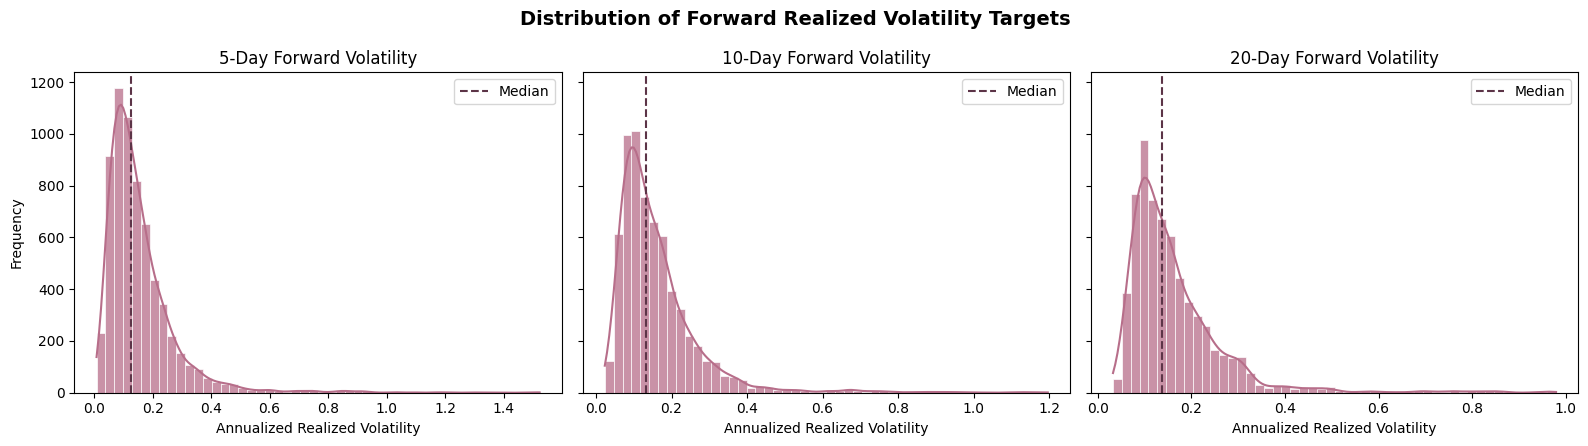

In [ ]:
# --------------------------------------------------
# 3.4 Forward Volatility Distribution Visualization
# --------------------------------------------------

# Initialize figure and axes
fig_forward_rv_dist, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharey=True
)

for ax, horizon in zip(axes, FORECAST_HORIZONS):

    target_col = f"Forward_RV_{horizon}D"

    sns.histplot(
        data=model_a_complete,
        x=target_col,
        bins=50,
        kde=True,
        ax=ax,
        color="#B76E8A",
        edgecolor="white",
        alpha=0.75
    )

    ax.axvline(
        model_a_complete[target_col].median(),
        color="#5C3447",
        linestyle="--",
        linewidth=1.5,
        label="Median"
    )

    ax.set_title(f"{horizon}-Day Forward Volatility")
    ax.set_xlabel("Annualized Realized Volatility")
    ax.set_ylabel("Frequency" if horizon == 5 else "")
    ax.legend()

fig_forward_rv_dist.suptitle(
    "Distribution of Forward Realized Volatility Targets",
    fontsize=14,
    fontweight="bold"
)

fig_forward_rv_dist.tight_layout()

plt.show()

**Key Observation:**

- **Average volatility:** Mean annualized realized volatility increases slightly from 0.1556 (5-day) to 0.1633 (20-day), while median volatility increases from 0.1249 to 0.1368.
- **Volatility dispersion:** The standard deviation decreases from 0.1225 at the 5-day horizon to 0.1066 at the 20-day horizon, indicating that longer forecasting windows produce relatively smoother volatility estimates.
- **Extreme observations:** Maximum annualized volatility decreases from 1.5229 (5-day) to 0.9790 (20-day), reflecting the greater sensitivity of shorter windows to concentrated market shocks.
- **Distribution asymmetry:** All three targets exhibit substantial positive skewness, ranging from 3.1157 to 3.4761.
- **Tail behavior:** High excess kurtosis values (14.9879–21.3091) indicate heavy-tailed distributions, particularly at shorter forecasting horizons.

### Section 3.5 - Summary of Target Engineering

The forward volatility target engineering process successfully established three supervised forecasting targets representing future S&P 500 realized volatility over 5, 10, and 20 trading days.

The completed activities include:

- **Target construction:** Calculated annualized forward realized volatility using subsequent daily S&P 500 log returns.
- **Numerical validation:** Independently verified target calculations across 15 observation-horizon combinations.
- **Temporal alignment:** Confirmed that targets reflect future returns without incorporating the forecast-date return.
- **Sample preparation:** Removed 20 observations with incomplete forecasting horizons, retaining 6,499 complete observations.
- **Distribution analysis:** Identified positively skewed, heavy-tailed volatility distributions, with greater dispersion and more extreme outcomes at shorter forecasting horizons.

The final target-engineered dataset contains **6,499 observations and 29 variables**, covering forecast origin dates from February 1, 2000, through December 2, 2025.

These targets will be used consistently across Ridge Regression, Support Vector Regression (SVR), and XGBoost to evaluate forecasting accuracy and the incremental predictive contribution of HMM-derived market regime probabilities.

## Section 4 - Supervised Modeling Dataset Preparation

This section prepares the supervised modeling dataset by defining the predictor specifications, forecasting targets, and chronological data partitions.

The preparation process includes:

- **Predictor selection:** Identifying historical market characteristics and filtered HMM regime probabilities used for forecasting.
- **Feature specifications:** Establishing market-only and regime-enhanced predictor sets.
- **Forecasting targets:** Defining the primary 5-day target and additional 10- and 20-day forecasting horizons.
- **Chronological partitioning:** Separating observations into training, validation, and testing periods.
- **Leakage prevention:** Applying a temporal purge to prevent overlapping forward-return windows from crossing partition boundaries.
- **Dataset verification:** Confirming the completeness, integrity, and temporal consistency of the resulting modeling partitions.

Both predictor specifications use identical observations, forecast horizons, and evaluation periods to support direct comparisons between Ridge Regression, Support Vector Regression (SVR), and XGBoost.

Feature standardization will be performed within the relevant model pipelines using training data only, preventing information leakage from validation or testing observations.

### Section 4.1 - Define Predictor Sets and Forecasting Targets

This subsection establishes two predictor specifications:

- **Market-only:** Eleven market indicators covering VIX, trailing realized volatility, skewness, and kurtosis.
- **Market + HMM:** The eleven market indicators supplemented by three filtered regime probabilities.

Both specifications are evaluated using Ridge Regression, SVR, and XGBoost to forecast realized volatility over 5, 10, and 20 trading days.

In [ ]:
# --------------------------------------------------
# 4.1 Define Predictor Sets and Forecasting Targets
# --------------------------------------------------

# Market-only predictors
base_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_5D",
    "Realized_Vol_10D",
    "Realized_Vol_20D",
    "Return_Skew_5D",
    "Return_Skew_10D",
    "Return_Skew_20D",
    "Return_Kurt_5D",
    "Return_Kurt_10D",
    "Return_Kurt_20D"
]

# Filtered HMM probabilities
regime_predictors = [
    "Filtered_P_Calm",
    "Filtered_P_Transition",
    "Filtered_P_Stressed"
]

# Regime-enhanced predictor set
enhanced_features = base_features + regime_predictors

# Define model feature specifications
feature_sets = {
    "Market-only": base_features,
    "Market + HMM": enhanced_features
}

# Forecasting targets (defined in Section 3)
HORIZONS = tuple(FORECAST_HORIZONS)

targets = [
    f"Forward_RV_{h}D"
    for h in HORIZONS
]

PRIMARY_HORIZON = 5
primary_target = f"Forward_RV_{PRIMARY_HORIZON}D"

# Define supervised algorithms
SUPERVISED_MODELS = [
    "Ridge",
    "SVR",
    "XGBoost"
]

# Verify required variable availability
required_columns = list(dict.fromkeys(
    enhanced_features + targets
))

missing_columns = [
    col for col in required_columns
    if col not in model_a_complete.columns
]

assert not missing_columns, (
    f"Required variables missing: {missing_columns}"
)

assert model_a_complete[required_columns].notna().all().all(), (
    "Missing values detected in predictors or targets."
)

assert len(base_features) == 11
assert len(enhanced_features) == 14

# Display modeling configuration
configuration_summary = pd.DataFrame({
    "Component": [
        "Market-only predictors",
        "Regime-enhanced predictors",
        "Additional HMM predictors",
        "Primary forecasting horizon",
        "Additional forecasting horizons",
        "Supervised algorithms",
        "Eligible observations"
    ],
    "Configuration": [
        len(base_features),
        len(enhanced_features),
        len(regime_predictors),
        f"{PRIMARY_HORIZON} trading days",
        "10 and 20 trading days",
        ", ".join(SUPERVISED_MODELS),
        len(model_a_complete)
    ]
})

print("Supervised Modeling Configuration")
print("-" * 55)

display(configuration_summary)

print("\nMarket-only Predictors:")
display(pd.DataFrame({"Feature": base_features}))

print("\nHMM Regime Predictors:")
display(pd.DataFrame({"Feature": regime_predictors}))

print("\nForecasting Targets:")
display(pd.DataFrame({"Target": targets}))

Supervised Modeling Configuration
-------------------------------------------------------


,Component,Configuration
0,Market-only predictors,11
1,Regime-enhanced predictors,14
2,Additional HMM predictors,3
3,Primary forecasting horizon,5 trading days
4,Additional forecasting horizons,10 and 20 trading days
5,Supervised algorithms,"Ridge, SVR, XGBoost"
6,Eligible observations,6499



Market-only Predictors:


,Feature
0,VIX_Level
1,VIX_Change
2,Realized_Vol_5D
3,Realized_Vol_10D
4,Realized_Vol_20D
5,Return_Skew_5D
6,Return_Skew_10D
7,Return_Skew_20D
8,Return_Kurt_5D
9,Return_Kurt_10D



HMM Regime Predictors:


,Feature
0,Filtered_P_Calm
1,Filtered_P_Transition
2,Filtered_P_Stressed



Forecasting Targets:


,Target
0,Forward_RV_5D
1,Forward_RV_10D
2,Forward_RV_20D


**Key Observations:**

The supervised forecasting framework was configured using two feature specifications:

- **Market-only:** Eleven predictors covering VIX, trailing realized volatility, return skewness, and kurtosis.
- **Market + HMM:** Fourteen predictors, including three additional filtered regime probabilities.
- **Forecasting targets:** Forward realized volatility over 5, 10, and 20 trading days.
- **Model families:** Ridge Regression, Support Vector Regression (SVR), and XGBoost.
- **Modeling sample:** 6,499 complete observations.

Both feature specifications will be evaluated across identical forecasting horizons and chronological data partitions to ensure consistent model comparisons.

### Section 4.2 - Chronological Train, Validation, and Test Splits

The modeling sample is divided chronologically into three periods:

- **Training (2000–2018):** Model estimation and parameter learning.
- **Validation (2019–2021):** Hyperparameter selection and model comparison.
- **Testing (2022–2025):** Final out-of-sample forecasting evaluation.

Chronological partitioning preserves the temporal structure of financial data and prevents random mixing of historical and future observations.

Overlapping forward-return windows will be addressed through boundary purging in Section 4.3.

In [ ]:
# --------------------------------------------------
# 4.2 Chronological Train, Validation, and Test Splits
# --------------------------------------------------

# Define chronological boundaries
TRAIN_END = pd.Timestamp("2018-12-31")
VAL_END = pd.Timestamp("2021-12-31")

# Assign observations to partitions
train_raw = model_a_complete.loc[
    model_a_complete["Date"] <= TRAIN_END
].copy()

val_raw = model_a_complete.loc[
    (model_a_complete["Date"] > TRAIN_END)
    & (model_a_complete["Date"] <= VAL_END)
].copy()

test_raw = model_a_complete.loc[
    model_a_complete["Date"] > VAL_END
].copy()

# Summarize partition dimensions and dates
split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Observations": len(df),
        "Start Date": df["Date"].min().date(),
        "End Date": df["Date"].max().date()
    }
    for name, df in [
        ("Training", train_raw),
        ("Validation", val_raw),
        ("Testing", test_raw)
    ]
])

print("Chronological Partition Summary")
print("-" * 55)

display(split_summary)

# Verify partition completeness
assert (
    len(train_raw) + len(val_raw) + len(test_raw)
    == len(model_a_complete)
), "Partition counts do not match the modeling sample."

# Verify chronological separation
assert train_raw["Date"].max() < val_raw["Date"].min()
assert val_raw["Date"].max() < test_raw["Date"].min()

print("\nChronological partitions created successfully.")

Chronological Partition Summary
-------------------------------------------------------


,Partition,Observations,Start Date,End Date
0,Training,4759,2000-02-01,2018-12-31
1,Validation,757,2019-01-02,2021-12-31
2,Testing,983,2022-01-03,2025-12-02



Chronological partitions created successfully.


**Key Observations:**

The modeling dataset was successfully divided into three chronological partitions:

- **Training:** 4,759 observations from February 1, 2000, through December 31, 2018.
- **Validation:** 757 observations from January 2, 2019, through December 31, 2021.
- **Testing:** 983 observations from January 3, 2022, through December 2, 2025.

All 6,499 observations were retained, and the partitions contain non-overlapping, chronologically ordered forecast dates.

The next subsection applies a temporal purge to prevent forward volatility targets from overlapping subsequent evaluation periods.

### Section 4.3 - Purge Overlapping Forecast Windows

Forward realized volatility targets use returns from the subsequent 5, 10, or 20 trading days, creating potential overlap across chronological partitions.

To prevent target leakage, the final 20 observations are excluded from both the training and validation partitions.

The testing partition remains unchanged, preserving the full out-of-sample evaluation period. This approach establishes consistent temporal separation across all forecasting horizons.

In [ ]:
# --------------------------------------------------
# 4.3 Purge Overlapping Forecast Windows
# --------------------------------------------------

# Maximum forecasting horizon
PURGE_WINDOW = max(FORECAST_HORIZONS)

# Remove final 20 observations at partition boundaries
train_df = train_raw.iloc[:-PURGE_WINDOW].copy()
val_df = val_raw.iloc[:-PURGE_WINDOW].copy()
test_df = test_raw.copy()

# Summarize purged partitions
purge_summary = pd.DataFrame([
    {
        "Partition": name,
        "Original": len(original),
        "Purged": len(original) - len(purged),
        "Retained": len(purged),
        "Start Date": purged["Date"].min().date(),
        "End Date": purged["Date"].max().date()
    }
    for name, original, purged in [
        ("Training", train_raw, train_df),
        ("Validation", val_raw, val_df),
        ("Testing", test_raw, test_df)
    ]
])

print("Purged Chronological Partition Summary")
print("-" * 55)

display(purge_summary)

# Verify expected purge counts
assert len(train_df) == len(train_raw) - PURGE_WINDOW
assert len(val_df) == len(val_raw) - PURGE_WINDOW
assert len(test_df) == len(test_raw)

# Verify chronological separation
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

# Verify no target window crosses the next partition boundary
full_dates = pd.DatetimeIndex(model_a_targets["Date"])

for earlier, later in [
    (train_df, val_raw),
    (val_df, test_raw)
]:
    last_origin = earlier["Date"].max()
    next_start = later["Date"].min()

    origin_position = full_dates.get_loc(last_origin)
    target_end = full_dates[origin_position + PURGE_WINDOW]

    assert target_end < next_start, (
        f"Forward target window crosses boundary at {next_start}"
    )

print("\nTemporal purge validated successfully.")

Purged Chronological Partition Summary
-------------------------------------------------------


,Partition,Original,Purged,Retained,Start Date,End Date
0,Training,4759,20,4739,2000-02-01,2018-11-29
1,Validation,757,20,737,2019-01-02,2021-12-02
2,Testing,983,0,983,2022-01-03,2025-12-02



Temporal purge validated successfully.


**Key Observations:**

The purge validation confirmed that forward target windows do not cross into subsequent partitions, reducing the risk of target leakage during model development and evaluation.

### Section 4.4 - Verify Modeling Partitions

This subsection validates the final training, validation, and testing datasets.

The assessment verifies predictor and target completeness, chronological separation, observation uniqueness, and consistent sample sizes across forecasting specifications.

These checks establish the final modeling partitions for Ridge Regression, SVR, and XGBoost.

In [ ]:
# --------------------------------------------------
# 4.4 Verify Modeling Partitions
# --------------------------------------------------

partitions = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

partition_results = []

# Validate each modeling partition
for name, df in partitions.items():

    required = enhanced_features + targets

    partition_results.append({
        "Partition": name,
        "Observations": len(df),
        "Missing Predictors": int(
            df[enhanced_features].isna().sum().sum()
        ),
        "Missing Targets": int(
            df[targets].isna().sum().sum()
        ),
        "Duplicate Dates": int(
            df["Date"].duplicated().sum()
        ),
        "Chronologically Sorted": df["Date"].is_monotonic_increasing,
        "Finite Numerical Values": bool(
            np.isfinite(df[required].to_numpy()).all()
        )
    })

# Display verification summary
partition_verification = pd.DataFrame(partition_results)

print("Modeling Partition Verification Summary")
print("-" * 55)

display(partition_verification)

# Validate completeness and integrity
assert (
    partition_verification["Missing Predictors"] == 0
).all()

assert (
    partition_verification["Missing Targets"] == 0
).all()

assert (
    partition_verification["Duplicate Dates"] == 0
).all()

assert partition_verification[
    "Chronologically Sorted"
].all()

assert partition_verification[
    "Finite Numerical Values"
].all()

# Verify chronological separation
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

# Verify total retained observations
assert sum(len(df) for df in partitions.values()) == 6459

print("\nModeling partitions verified successfully.")

Modeling Partition Verification Summary
-------------------------------------------------------


,Partition,Observations,Missing Predictors,Missing Targets,Duplicate Dates,Chronologically Sorted,Finite Numerical Values
0,Training,4739,0,0,0,True,True
1,Validation,737,0,0,0,True,True
2,Testing,983,0,0,0,True,True



Modeling partitions verified successfully.


**Key Observations:**

The verified partitions provide a consistent dataset for supervised model development and evaluation.


### Section 4.5 - Summary of Modeling Dataset Preparation

The supervised modeling dataset was successfully prepared and validated.

- **Feature specifications:** Defined 11 market-only predictors and 14 regime-enhanced predictors.
- **Forecasting targets:** Established forward realized volatility over 5, 10, and 20 trading days.
- **Chronological splitting:** Separated observations into training (2000–2018), validation (2019–2021), and testing (2022–2025).
- **Leakage prevention:** Applied a 20-trading-day purge at the training and validation boundaries.
- **Final sample:** Retained 6,459 observations across the three partitions, with no missing values or duplicate dates.

Feature scaling will be fitted within the relevant training pipelines to prevent validation and test information from influencing preprocessing.

The resulting partitions will be used consistently across Ridge Regression, Support Vector Regression (SVR), and XGBoost.

## Section 5 - Persistence Benchmark

This section establishes a naive persistence benchmark for forecasting S&P 500 realized volatility over 5, 10, and 20 trading days.

The benchmark assumes that future realized volatility equals the most recently observed trailing volatility over the corresponding horizon.

Performance is evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE), providing a reference for assessing the predictive value of the supervised learning models.

### Section 5.1 - Define the Persistence Benchmark

The persistence benchmark uses trailing realized volatility as a direct forecast of future volatility:

- **5-day forecast:** `Realized_Vol_5D` predicts `Forward_RV_5D`.
- **10-day forecast:** `Realized_Vol_10D` predicts `Forward_RV_10D`.
- **20-day forecast:** `Realized_Vol_20D` predicts `Forward_RV_20D`.

The benchmark requires no training or hyperparameter optimization and is evaluated on the same chronological partitions as the supervised models.

In [ ]:
# --------------------------------------------------
# 5.1 Define the Persistence Benchmark
# --------------------------------------------------

# Map forecasting targets to their persistence predictors
persistence_features = {
    5: "Realized_Vol_5D",
    10: "Realized_Vol_10D",
    20: "Realized_Vol_20D"
}

# Define evaluation partitions
evaluation_partitions = {
    "Validation": val_df,
    "Testing": test_df
}

# Verify persistence features are available
for horizon, feature in persistence_features.items():

    target = f"Forward_RV_{horizon}D"

    for name, df in evaluation_partitions.items():
        assert feature in df.columns
        assert target in df.columns
        assert df[[feature, target]].notna().all().all()

print("Persistence Benchmark Configuration")
print("-" * 55)

display(pd.DataFrame({
    "Horizon": list(persistence_features.keys()),
    "Persistence Predictor": list(persistence_features.values()),
    "Forecast Target": [
        f"Forward_RV_{h}D"
        for h in persistence_features
    ]
}))

print("\nPersistence benchmark configuration verified.")

Persistence Benchmark Configuration
-------------------------------------------------------


,Horizon,Persistence Predictor,Forecast Target
0,5,Realized_Vol_5D,Forward_RV_5D
1,10,Realized_Vol_10D,Forward_RV_10D
2,20,Realized_Vol_20D,Forward_RV_20D



Persistence benchmark configuration verified.


### Section 5.2 - Generate Benchmark Forecasts

Persistence forecasts are generated directly from the corresponding trailing realized volatility features.

Forecasts are produced for the validation and testing partitions across all three horizons. Predictions are retained for subsequent model comparisons and statistical evaluation.

In [ ]:
# --------------------------------------------------
# 5.2 Generate Benchmark Forecasts
# --------------------------------------------------

# Store benchmark predictions by partition and horizon
persistence_predictions = {}

for partition_name, df in evaluation_partitions.items():

    persistence_predictions[partition_name] = {}

    for horizon, feature in persistence_features.items():

        target = f"Forward_RV_{horizon}D"

        # Actual future volatility
        y_true = df[target].to_numpy()

        # Persistence forecast
        y_pred = df[feature].to_numpy()

        persistence_predictions[partition_name][horizon] = {
            "Date": df["Date"].to_numpy(),
            "Actual": y_true,
            "Predicted": y_pred
        }

# Preview five-day testing forecasts
preview = persistence_predictions["Testing"][5]

persistence_preview = pd.DataFrame({
    "Date": preview["Date"],
    "Actual": preview["Actual"],
    "Persistence Forecast": preview["Predicted"]
})

print("Persistence Forecast Preview - 5-Day Testing")
print("-" * 55)

display(persistence_preview.head(10))

Persistence Forecast Preview - 5-Day Testing
-------------------------------------------------------


,Date,Actual,Persistence Forecast
0,2022-01-03,0.1282,0.0610
1,2022-01-04,0.1644,0.0605
2,2022-01-05,0.0812,0.1515
3,2022-01-06,0.1381,0.1529
4,2022-01-07,0.1370,0.1528
5,2022-01-10,0.1880,0.1282
6,2022-01-11,0.1483,0.1644
7,2022-01-12,0.1147,0.0812
8,2022-01-13,0.1286,0.1381
9,2022-01-14,0.1406,0.1370


### Section 5.3 - Evaluate Benchmark Performance

Persistence forecasting accuracy is evaluated using:

- **RMSE:** Penalizes larger forecasting errors more heavily.
- **MAE:** Measures the average absolute forecasting error.

Both metrics are calculated for the validation and testing periods. Lower values indicate better forecasting performance.

In [ ]:
# --------------------------------------------------
# 5.3 Evaluate Benchmark Performance
# --------------------------------------------------

benchmark_results = []

for partition_name, horizon_data in persistence_predictions.items():

    for horizon, predictions in horizon_data.items():

        y_true = predictions["Actual"]
        y_pred = predictions["Predicted"]

        # Calculate forecasting errors
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)

        benchmark_results.append({
            "Model": "Persistence",
            "Partition": partition_name,
            "Horizon": horizon,
            "RMSE": rmse,
            "MAE": mae
        })

# Consolidate performance results
benchmark_results_df = pd.DataFrame(benchmark_results)

print("Persistence Benchmark Performance")
print("-" * 55)

display(
    benchmark_results_df.sort_values(
        ["Partition", "Horizon"]
    ).reset_index(drop=True)
)

Persistence Benchmark Performance
-------------------------------------------------------


,Model,Partition,Horizon,RMSE,MAE
0,Persistence,Testing,5,0.0974,0.0647
1,Persistence,Testing,10,0.0849,0.0543
2,Persistence,Testing,20,0.0761,0.0487
3,Persistence,Validation,5,0.1256,0.0794
4,Persistence,Validation,10,0.1312,0.0807
5,Persistence,Validation,20,0.1580,0.0914


### Section 5.4 - Summary of Persistence Benchmark

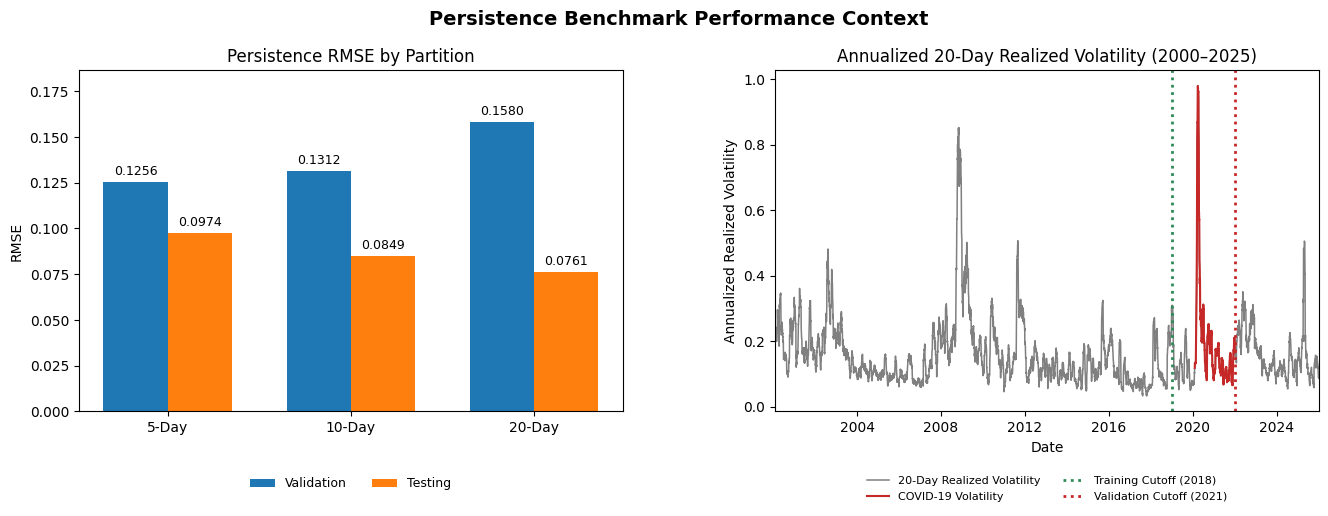

In [ ]:
# --------------------------------------------------
# 5.4 Persistence Benchmark Context Visualization
# --------------------------------------------------

# Prepare RMSE comparison
rmse_plot_df = (
    benchmark_results_df
    .pivot(index="Horizon", columns="Partition", values="RMSE")
    .sort_index()
)

# Full historical 20-day realized volatility
rv_20_full_df = model_a_df[
    ["Date", "Realized_Vol_20D"]
].copy()

# Define important dates
train_cutoff = pd.Timestamp("2018-12-31")
val_cutoff = pd.Timestamp("2021-12-31")

covid_start = pd.Timestamp("2020-02-01")
covid_end = pd.Timestamp("2021-12-31")

# Initialize figure
fig_persistence_context, axes = plt.subplots(
    1, 2,
    figsize=(16, 5.5)
)

# ----------------------------------------
# Panel A: Persistence RMSE Comparison
# ----------------------------------------

x = np.arange(len(rmse_plot_df.index))
width = 0.35

# Validation bars - original blue
bars_val = axes[0].bar(
    x - width / 2,
    rmse_plot_df["Validation"],
    width=width,
    color="#1f77b4",
    label="Validation"
)

# Testing bars - original orange
bars_test = axes[0].bar(
    x + width / 2,
    rmse_plot_df["Testing"],
    width=width,
    color="#ff7f0e",
    label="Testing"
)

# Add RMSE labels above bars
for bars in [bars_val, bars_test]:
    axes[0].bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{h}-Day" for h in rmse_plot_df.index])

axes[0].set_ylim(
    0,
    rmse_plot_df.to_numpy().max() * 1.18
)

axes[0].set_title("Persistence RMSE by Partition")
axes[0].set_ylabel("RMSE")

# Horizontal legend below graph
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
    fontsize=9
)

# ----------------------------------------
# Panel B: Historical 20-Day Realized Volatility
# ----------------------------------------

# Plot full realized volatility series in gray
axes[1].plot(
    rv_20_full_df["Date"],
    rv_20_full_df["Realized_Vol_20D"],
    color="#808080",
    linewidth=1.1,
    label="20-Day Realized Volatility",
    zorder=2
)

# Highlight COVID-19 realized volatility in red
covid_mask = (
    (rv_20_full_df["Date"] >= covid_start) &
    (rv_20_full_df["Date"] <= covid_end)
)

axes[1].plot(
    rv_20_full_df.loc[covid_mask, "Date"],
    rv_20_full_df.loc[covid_mask, "Realized_Vol_20D"],
    color="#C62828",
    linewidth=1.5,
    label="COVID-19 Volatility",
    zorder=3
)

# Training cutoff - green dotted line
axes[1].axvline(
    train_cutoff,
    color="#2E8B57",
    linestyle=":",
    linewidth=2,
    label="Training Cutoff (2018)"
)

# Validation cutoff - red dotted line
axes[1].axvline(
    val_cutoff,
    color="#C62828",
    linestyle=":",
    linewidth=2,
    label="Validation Cutoff (2021)"
)

axes[1].set_title("Annualized 20-Day Realized Volatility (2000–2025)")
axes[1].set_ylabel("Annualized Realized Volatility")
axes[1].set_xlabel("Date")

axes[1].set_xlim(
    rv_20_full_df["Date"].min(),
    rv_20_full_df["Date"].max()
)

# Horizontal legend below graph
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
    fontsize=8
)

# ----------------------------------------
# Final Figure Formatting
# ----------------------------------------

fig_persistence_context.suptitle(
    "Persistence Benchmark Performance Context",
    fontsize=14,
    fontweight="bold"
)

fig_persistence_context.subplots_adjust(
    bottom=0.25,
    top=0.87,
    wspace=0.28
)

plt.show()

**Key Observations:**

The persistence benchmark was evaluated across three forecasting horizons, with results contextualized against historical market volatility.

- **Testing performance:** RMSE decreased from 0.0974 (5-day) to 0.0761 (20-day), with lower forecasting errors at longer horizons.
- **Validation versus testing:** Validation RMSE exceeded testing RMSE across all horizons, with the largest difference at the 20-day horizon (0.1580 versus 0.0761).
- **Market conditions:** The historical volatility series highlights the sharp increase in volatility during COVID-19, which occurred within the validation period and may have contributed to its higher forecasting errors.
- **Forecasting limitations:** Persistence relies on trailing volatility and cannot anticipate abrupt changes in market conditions, potentially underestimating volatility spikes and overestimating subsequent declines.

Overall, the benchmark demonstrates the limitations of relying exclusively on historical volatility, particularly during periods of rapid market adjustment. These results establish a reference for evaluating whether Ridge Regression, SVR, and XGBoost provide more accurate and adaptive forecasts.

## Section 6 - Ridge Regression

This section implements Ridge Regression to forecast forward S&P 500 realized volatility over 5, 10, and 20 trading days.

Ridge Regression applies L2 regularization to linear regression, reducing coefficient instability when predictors are correlated.

Market-only and HMM-enhanced specifications are evaluated against the persistence benchmark to assess forecasting accuracy and the incremental contribution of regime information.

### Section 6.1 - Define Ridge Regression and Model Specifications

Ridge Regression is implemented using a pipeline combining feature standardization and L2-regularized regression.

- **Market-only:** Eleven historical market indicators.
- **Market + HMM:** Fourteen predictors, including three filtered regime probabilities.
- **Regularization:** The penalty parameter `alpha` controls coefficient shrinkage.

Models are trained separately for each forecasting horizon, with hyperparameters selected using validation RMSE.

In [ ]:
# --------------------------------------------------
# 6.1 Define Ridge Regression and Model Specifications
# --------------------------------------------------

# Candidate regularization strengths
RIDGE_ALPHA_GRID = [0.01, 0.1, 1, 10, 100, 1000]

# Construct a Ridge Regression pipeline
def build_ridge_model(alpha):

    return Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])

# Initialize storage for model development
ridge_tuning_records = []
ridge_models = {}
ridge_predictions = {}
ridge_results = []

# Display Ridge configuration
ridge_configuration = pd.DataFrame({
    "Component": [
        "Algorithm",
        "Preprocessing",
        "Regularization",
        "Candidate Alpha Values",
        "Feature Specifications",
        "Forecast Horizons",
        "Selection Metric"
    ],
    "Configuration": [
        "Ridge Regression",
        "StandardScaler",
        "L2 Penalty",
        str(RIDGE_ALPHA_GRID),
        ", ".join(feature_sets.keys()),
        str(HORIZONS),
        "Validation RMSE"
    ]
})

print("Ridge Regression Configuration")
print("-" * 55)

display(ridge_configuration)

Ridge Regression Configuration
-------------------------------------------------------


,Component,Configuration
0,Algorithm,Ridge Regression
1,Preprocessing,StandardScaler
2,Regularization,L2 Penalty
3,Candidate Alpha Values,"[0.01, 0.1, 1, 10, 100, 1000]"
4,Feature Specifications,"Market-only, Market + HMM"
5,Forecast Horizons,"(5, 10, 20)"
6,Selection Metric,Validation RMSE


**Key Observations:**

- **Feature specifications:** Market-only (11 predictors) and Market + HMM (14 predictors).
- **Regularization:** Six candidate alpha values ranging from 0.01 to 1,000.
- **Forecast horizons:** 5, 10, and 20 trading days.
- **Model selection:** Hyperparameters selected using validation RMSE.

The configuration provides a consistent framework for evaluating linear volatility forecasts with and without HMM regime information.

### Section 6.2 - Hyperparameter Tuning and Model Training

Ridge Regression models are trained across both predictor specifications and all three forecasting horizons.

The regularization parameter `alpha` is selected by minimizing validation RMSE. Feature standardization is fitted exclusively on the training partition through a scikit-learn pipeline.

The optimal configurations and fitted models are retained for subsequent evaluation.

In [ ]:
# --------------------------------------------------
# 6.2 Hyperparameter Tuning and Model Training
# --------------------------------------------------

# Reset model and tuning storage
ridge_tuning_records = []
ridge_models = {}

# Train models across horizons and feature specifications
for horizon in HORIZONS:

    target_col = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        # Prepare training and validation data
        X_train = train_df[features]
        y_train = train_df[target_col]

        X_val = val_df[features]
        y_val = val_df[target_col]

        best_rmse = np.inf
        best_alpha = None
        best_model = None

        # Evaluate candidate regularization strengths
        for alpha in RIDGE_ALPHA_GRID:

            model = build_ridge_model(alpha)
            model.fit(X_train, y_train)

            # Validation predictions
            val_pred = model.predict(X_val)

            # Calculate validation RMSE
            val_rmse = np.sqrt(
                mean_squared_error(y_val, val_pred)
            )

            # Record tuning results
            ridge_tuning_records.append({
                "Horizon": horizon,
                "Feature Set": feature_name,
                "Alpha": alpha,
                "Validation RMSE": val_rmse
            })

            # Retain best configuration
            if val_rmse < best_rmse:
                best_rmse = val_rmse
                best_alpha = alpha
                best_model = model

        # Store best fitted model
        ridge_models[(horizon, feature_name)] = {
            "Model": best_model,
            "Alpha": best_alpha,
            "Validation RMSE": best_rmse
        }

# Consolidate tuning results
ridge_tuning_df = pd.DataFrame(ridge_tuning_records)

# Summarize optimal configurations
ridge_best_summary = pd.DataFrame([
    {
        "Horizon": horizon,
        "Feature Set": feature_name,
        "Optimal Alpha": result["Alpha"],
        "Validation RMSE": result["Validation RMSE"]
    }
    for (horizon, feature_name), result in ridge_models.items()
])

print("Ridge Regression - Optimal Hyperparameters")
print("-" * 55)

display(
    ridge_best_summary.sort_values(
        ["Horizon", "Feature Set"]
    ).reset_index(drop=True)
)

print("\nRidge Regression models trained successfully.")

Ridge Regression - Optimal Hyperparameters
-------------------------------------------------------


,Horizon,Feature Set,Optimal Alpha,Validation RMSE
0,5,Market + HMM,0.0100,0.1134
1,5,Market-only,10.0000,0.1139
2,10,Market + HMM,0.0100,0.1113
3,10,Market-only,0.0100,0.1114
4,20,Market + HMM,0.0100,0.1249
5,20,Market-only,0.0100,0.1245



Ridge Regression models trained successfully.


**Key Observations:**

- **Optimal regularization:** Five of six models selected alpha = 0.01, while the 5-day market-only specification selected alpha = 10.
- **Validation performance:** The HMM-enhanced specification slightly outperformed market-only Ridge at the 5- and 10-day horizons.
- **20-day horizon:** Market-only Ridge achieved marginally lower validation RMSE (0.1245 versus 0.1249).
- **Sensitivity consideration:** The frequent selection of the smallest candidate alpha motivates further regularization sensitivity analysis.

### Section 6.3 - Validation and Testing Performance

This subsection evaluates the optimized Ridge Regression models using RMSE and MAE.

Performance is compared across forecasting horizons and predictor specifications, with the persistence benchmark serving as the reference.

Testing results are used to assess out-of-sample forecasting accuracy and the incremental contribution of HMM regime probabilities.

In [ ]:
# --------------------------------------------------
# 6.3 Validation and Testing Performance
# --------------------------------------------------

# Initialize result storage
ridge_predictions = {}
ridge_results = []

# Evaluate selected Ridge models
for (horizon, feature_name), result in ridge_models.items():

    model = result["Model"]
    features = feature_sets[feature_name]
    target_col = f"Forward_RV_{horizon}D"

    for partition_name, df in evaluation_partitions.items():

        # Prepare evaluation data
        X = df[features]
        y_true = df[target_col].to_numpy()

        # Generate predictions
        y_pred = model.predict(X)

        # Calculate forecasting metrics
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)

        # Store predictions for later diagnostics
        ridge_predictions[
            (horizon, feature_name, partition_name)
        ] = {
            "Date": df["Date"].to_numpy(),
            "Actual": y_true,
            "Predicted": y_pred
        }

        # Store performance results
        ridge_results.append({
            "Model": "Ridge",
            "Feature Set": feature_name,
            "Partition": partition_name,
            "Horizon": horizon,
            "Alpha": result["Alpha"],
            "RMSE": rmse,
            "MAE": mae
        })

# Consolidate results
ridge_results_df = pd.DataFrame(ridge_results)

print("Ridge Regression Performance")
print("-" * 55)

display(
    ridge_results_df.sort_values(
        ["Partition", "Horizon", "Feature Set"]
    ).reset_index(drop=True)
)

# Compare testing RMSE against persistence
ridge_test_comparison = ridge_results_df.loc[
    ridge_results_df["Partition"] == "Testing"
].merge(
    benchmark_results_df.loc[
        benchmark_results_df["Partition"] == "Testing",
        ["Horizon", "RMSE"]
    ].rename(columns={"RMSE": "Persistence RMSE"}),
    on="Horizon",
    validate="many_to_one"
)

# Percentage reduction in RMSE relative to persistence
ridge_test_comparison["RMSE Improvement (%)"] = (
    (
        ridge_test_comparison["Persistence RMSE"]
        - ridge_test_comparison["RMSE"]
    )
    / ridge_test_comparison["Persistence RMSE"]
    * 100
)

print("\nRidge vs. Persistence - Testing Performance")
print("-" * 55)

display(
    ridge_test_comparison[
        [
            "Horizon",
            "Feature Set",
            "RMSE",
            "Persistence RMSE",
            "RMSE Improvement (%)"
        ]
    ].sort_values(
        ["Horizon", "Feature Set"]
    ).reset_index(drop=True)
)

Ridge Regression Performance
-------------------------------------------------------


,Model,Feature Set,Partition,Horizon,Alpha,RMSE,MAE
0,Ridge,Market + HMM,Testing,5,0.0100,0.0740,0.0494
1,Ridge,Market-only,Testing,5,10.0000,0.0738,0.0492
2,Ridge,Market + HMM,Testing,10,0.0100,0.0673,0.0428
3,Ridge,Market-only,Testing,10,0.0100,0.0670,0.0427
4,Ridge,Market + HMM,Testing,20,0.0100,0.0611,0.0393
5,Ridge,Market-only,Testing,20,0.0100,0.0607,0.0392
6,Ridge,Market + HMM,Validation,5,0.0100,0.1134,0.0697
7,Ridge,Market-only,Validation,5,10.0000,0.1139,0.0699
8,Ridge,Market + HMM,Validation,10,0.0100,0.1113,0.0672
9,Ridge,Market-only,Validation,10,0.0100,0.1114,0.0672



Ridge vs. Persistence - Testing Performance
-------------------------------------------------------


,Horizon,Feature Set,RMSE,Persistence RMSE,RMSE Improvement (%)
0,5,Market + HMM,0.0740,0.0974,24.0510
1,5,Market-only,0.0738,0.0974,24.2298
2,10,Market + HMM,0.0673,0.0849,20.6664
3,10,Market-only,0.0670,0.0849,21.1087
4,20,Market + HMM,0.0611,0.0761,19.6935
5,20,Market-only,0.0607,0.0761,20.2223


**Key Observations:**

- **Ridge outperforms persistence:** Market-only Ridge reduced testing RMSE by 24.23%, 21.11%, and 20.22% across the 5-, 10-, and 20-day horizons.

- **Limited incremental value from HMM:** Although regime probabilities slightly improved validation performance at shorter horizons, they did not improve testing performance at any horizon.

- **Generalization:** Testing RMSE was lower than validation RMSE for all six Ridge specifications, consistent with the differences in market conditions observed between the two periods.

### Section 6.4 - Forecast Visualization and Diagnostics

This subsection examines the 5-day Ridge Regression forecasts over the testing period (2022–2025).

- **Forecast comparison:** Compare actual volatility against market-only and HMM-enhanced predictions.
- **Prediction errors:** Examine forecast residuals to identify periods of underestimation and overestimation.

The analysis provides a visual assessment of forecasting performance beyond aggregate RMSE and MAE.

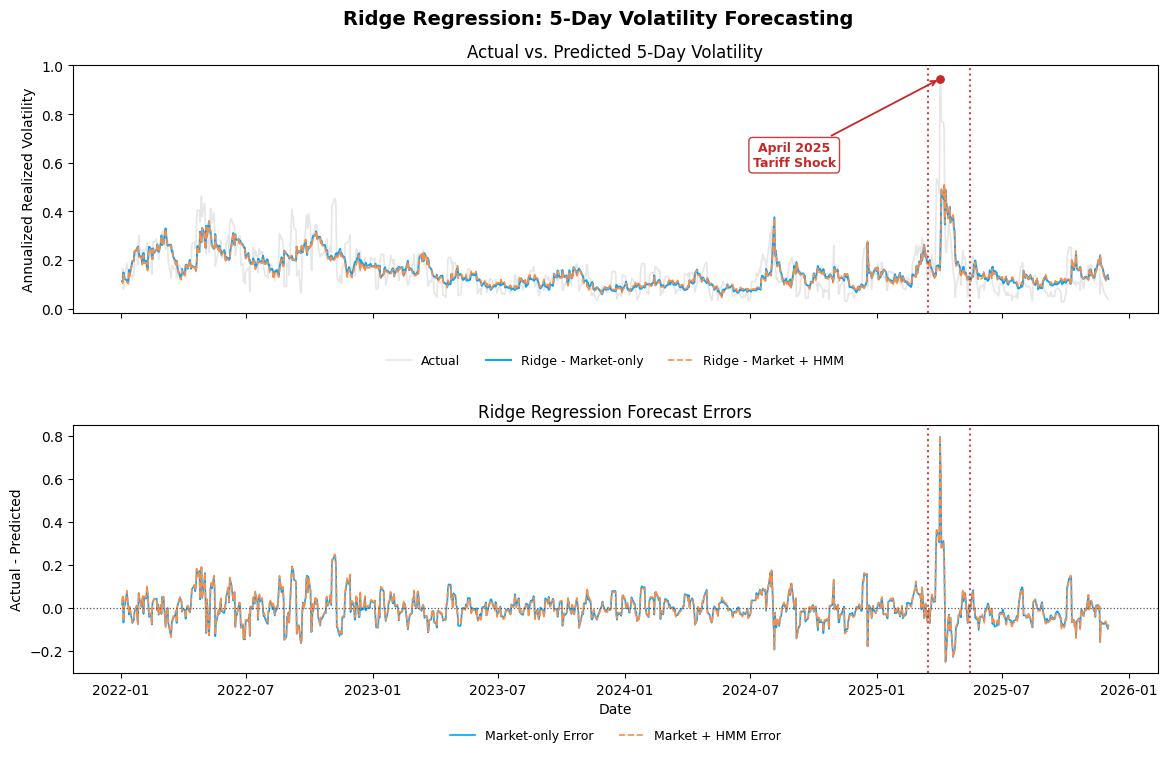

In [ ]:
# --------------------------------------------------
# 6.4 Ridge Regression Forecast Visualization
# --------------------------------------------------

# Retrieve five-day testing predictions
ridge_market = ridge_predictions[
    (5, "Market-only", "Testing")
]

ridge_hmm = ridge_predictions[
    (5, "Market + HMM", "Testing")
]

# Prepare plotting data
ridge_plot_df = pd.DataFrame({
    "Date": pd.to_datetime(ridge_market["Date"]),
    "Actual": ridge_market["Actual"],
    "Market-only": ridge_market["Predicted"],
    "Market + HMM": ridge_hmm["Predicted"]
})

# Calculate forecast errors (Actual - Predicted)
ridge_plot_df["Market Error"] = (
    ridge_plot_df["Actual"] - ridge_plot_df["Market-only"]
)

ridge_plot_df["HMM Error"] = (
    ridge_plot_df["Actual"] - ridge_plot_df["Market + HMM"]
)

# Define consistent colors
COLOR_ACTUAL = "#D3D3D3"
COLOR_RIDGE_MARKET = "#00A6FF"
COLOR_RIDGE_HMM = "#FF8C42"
COLOR_ANNOTATION = "#C62828"

# Initialize figure
fig_ridge_forecasts, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# ----------------------------------------
# Panel A: Actual vs. Predicted Volatility
# ----------------------------------------

axes[0].plot(
    ridge_plot_df["Date"],
    ridge_plot_df["Actual"],
    color=COLOR_ACTUAL,
    linewidth=1.2,
    alpha=0.55,
    label="Actual",
    zorder=1
)

axes[0].plot(
    ridge_plot_df["Date"],
    ridge_plot_df["Market-only"],
    color=COLOR_RIDGE_MARKET,
    linewidth=1.4,
    label="Ridge - Market-only",
    zorder=2
)

axes[0].plot(
    ridge_plot_df["Date"],
    ridge_plot_df["Market + HMM"],
    color=COLOR_RIDGE_HMM,
    linewidth=1.2,
    linestyle="--",
    label="Ridge - Market + HMM",
    zorder=2
)

axes[0].set_title("Actual vs. Predicted 5-Day Volatility")
axes[0].set_ylabel("Annualized Realized Volatility")

# ----------------------------------------
# Annotate April 2025 Tariff Shock
# ----------------------------------------

# Define April 2025 event window
spike_start = pd.Timestamp("2025-04-02")
spike_end = pd.Timestamp("2025-04-30")

# Identify peak actual volatility within April 2025
spike_df = ridge_plot_df.loc[
    ridge_plot_df["Date"].between(spike_start, spike_end)
]

if spike_df.empty:
    raise ValueError(
        "No April 2025 observations available for annotation."
    )

peak_idx = spike_df["Actual"].idxmax()

peak_date = ridge_plot_df.loc[peak_idx, "Date"]
peak_volatility = ridge_plot_df.loc[peak_idx, "Actual"]

# Position marker slightly below the peak
dot_y = peak_volatility - 0.01

axes[0].scatter(
    peak_date,
    dot_y,
    color=COLOR_ANNOTATION,
    s=28,
    zorder=5
)

# Annotation box positioned within the chart
axes[0].annotate(
    "April 2025\nTariff Shock",
    xy=(peak_date, dot_y),
    xytext=(-105, -55),
    textcoords="offset points",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_ANNOTATION,
        linewidth=1.3
    ),
    fontsize=9,
    color=COLOR_ANNOTATION,
    fontweight="bold",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor=COLOR_ANNOTATION,
        alpha=0.9
    ),
    zorder=6
)

# ----------------------------------------
# Panel B: Forecast Errors
# ----------------------------------------

axes[1].plot(
    ridge_plot_df["Date"],
    ridge_plot_df["Market Error"],
    color=COLOR_RIDGE_MARKET,
    linewidth=1.2,
    label="Market-only Error"
)

axes[1].plot(
    ridge_plot_df["Date"],
    ridge_plot_df["HMM Error"],
    color=COLOR_RIDGE_HMM,
    linewidth=1.2,
    linestyle="--",
    label="Market + HMM Error"
)

# Zero-error reference
axes[1].axhline(
    0,
    color="#555555",
    linewidth=0.9,
    linestyle=":"
)

axes[1].set_title("Ridge Regression Forecast Errors")
axes[1].set_ylabel("Actual - Predicted")
axes[1].set_xlabel("Date")

# ----------------------------------------
# Highlight March-May 2025 Volatility Episode
# ----------------------------------------

error_window_start = pd.Timestamp("2025-03-15")
error_window_end = pd.Timestamp("2025-05-15")

# Apply matching red dotted lines to both panels
for ax in axes:

    ax.axvline(
        error_window_start,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

    ax.axvline(
        error_window_end,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

# ----------------------------------------
# Legends and Final Formatting
# ----------------------------------------

# Horizontal legend below Panel A
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=9
)

# Horizontal legend below Panel B
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
    fontsize=9
)

# Main figure title
fig_ridge_forecasts.suptitle(
    "Ridge Regression: 5-Day Volatility Forecasting",
    fontsize=14,
    fontweight="bold"
)

# Adjust spacing
fig_ridge_forecasts.subplots_adjust(
    hspace=0.45,
    bottom=0.15,
    top=0.91
)

plt.show()

**Key Observations:**

The 5-day Ridge Regression forecasts were examined across the 2022–2025 testing period.

- **Forecast behavior:** Both Ridge specifications capture general volatility movements but exhibit limitations in anticipating abrupt market changes.
- **April 2025 tariff shock:** The sharp increase in realized volatility associated with U.S. tariff announcements highlights the difficulty of forecasting sudden market disruptions using historical indicators.
- **Forecast errors:** The March–May 2025 episode provides a focused window for examining forecast underestimation and subsequent adjustments.
- **HMM contribution:** Market-only and HMM-enhanced predictions exhibit similar forecasting patterns, consistent with their closely aligned testing RMSE values (0.0738 versus 0.0740).
- **Model limitations:** Ridge Regression's linear structure may limit its ability to capture extreme volatility movements and nonlinear market responses.

Overall, Ridge Regression improves upon the persistence benchmark but remains sensitive to unexpected market shocks. The findings motivate further evaluation of nonlinear forecasting approaches and detailed failure analysis.

### Section 6.5 - Summary of Ridge Regression

Ridge Regression was evaluated using two feature sets (Market-only and Market + HMM) across the 5-, 10-, and 20-day forecasting horizons.

- **Hyperparameter tuning:** The regularization parameter ($\alpha$) was selected using validation RMSE. Five of the six model configurations selected the lowest tested value ($\alpha = 0.01$), suggesting that additional sensitivity testing may be useful.
- **Forecasting performance:** Market-only Ridge achieved testing RMSE values of **0.0738, 0.0670, and 0.0607** for the 5-, 10-, and 20-day horizons, representing improvements of approximately **24.2%, 21.1%, and 20.2%** over the persistence benchmark.
- **HMM contribution:** Adding filtered regime probabilities did not improve testing performance. The Market + HMM specification produced slightly higher RMSE across all three horizons.
- **Forecast diagnostics:** The April 2025 tariff-related volatility spike illustrates the challenges associated with forecasting abrupt market disruptions using historical indicators.

**Overall, Market-only Ridge Regression provides a strong linear benchmark, while the limited contribution of HMM probabilities motivates further investigation through nonlinear models, feature ablation, and sensitivity analysis.**

## Section 7 - Support Vector Regression (SVR)

Support Vector Regression (SVR) is introduced as a nonlinear forecasting approach to predict forward realized volatility over 5, 10, and 20 day horizons. Unlike Ridge Regression, SVR uses a Radial Basis Function (RBF) kernel to capture potentially nonlinear relationships between market indicators and future volatility.

The model is evaluated using two feature sets: **Market-only**, consisting of 11 conventional market indicators, and **Market + HMM**, which incorporates three additional filtered regime probabilities generated by Model B.

Both specifications use the same chronological training, validation, and testing partitions established in Section 4, including the 20-trading-day purge to prevent overlapping targets across partitions. Predictors are standardized using training data only, and hyperparameters are selected based on validation RMSE.

SVR performance will be evaluated against the persistence benchmark and Ridge Regression to determine whether nonlinear modeling improves forecasting accuracy and whether incorporating HMM regime information provides additional predictive value.

### Section 7.1 - SVR Configuration and Hyperparameter Search Space

Support Vector Regression (SVR) with an RBF kernel is introduced to capture potentially nonlinear relationships between market indicators and forward realized volatility.

Two feature specifications are evaluated:

- **Market-only:** 11 conventional market predictors.
- **Market + HMM:** 11 market predictors supplemented by three filtered regime probabilities.

Models are developed separately for the 5-, 10-, and 20-day forecasting horizons.

Hyperparameters are selected by minimizing validation RMSE:

- **C:** Controls the penalty applied to deviations outside the epsilon-insensitive margin.
- **epsilon:** Defines the width of the error tolerance margin.
- **gamma:** Controls the influence of individual observations through the RBF kernel.

Predictors are standardized using training data only to prevent data leakage. The existing chronological partitions and 20-trading-day purge are retained.

In [ ]:

# --------------------------------------------------
# 7.1 SVR Configuration
# --------------------------------------------------

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from itertools import product

# Hyperparameter search space
SVR_PARAM_GRID = {
    "C": [0.1, 1, 10],
    "epsilon": [0.01, 0.05, 0.1],
    "gamma": ["scale", 0.01, 0.1]
}

# Build SVR pipeline
def build_svr_model(C, epsilon, gamma):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=C,
            epsilon=epsilon,
            gamma=gamma,
            cache_size=500
        ))
    ])

# Containers for model outputs
svr_tuning_records = []
svr_models = {}
svr_predictions = {}
svr_results = []

# Display configuration
print("SVR kernel: RBF")
print("Hyperparameter grid:", SVR_PARAM_GRID)
print("Candidate combinations per configuration:",
      len(list(product(*SVR_PARAM_GRID.values()))))

print("Forecast horizons:", HORIZONS)
print("Feature sets:", list(feature_sets.keys()))


SVR kernel: RBF
Hyperparameter grid: {'C': [0.1, 1, 10], 'epsilon': [0.01, 0.05, 0.1], 'gamma': ['scale', 0.01, 0.1]}
Candidate combinations per configuration: 27
Forecast horizons: (5, 10, 20)
Feature sets: ['Market-only', 'Market + HMM']


### Section 7.2 - SVR Hyperparameter Tuning

- Train SVR models across all three forecasting horizons and both feature sets.
- Evaluate 27 hyperparameter combinations per configuration.
- Select the optimal combination of C, epsilon, and gamma using validation RMSE.
- Retain the selected models for subsequent out-of-sample evaluation.

**Note:** SVR can be computationally demanding (my data is small so its manageable); this configuration involves 162 individual fits. Hence, execution might take a while.For reference, my run on Collab took around 7 minutes.

In [ ]:

# --------------------------------------------------
# 7.2 SVR Hyperparameter Tuning
# --------------------------------------------------

svr_tuning_records = []
svr_models = {}

for horizon in HORIZONS:

    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        X_train = train_df[features]
        y_train = train_df[target]

        X_val = val_df[features]
        y_val = val_df[target]

        best_rmse = float("inf")
        best_model = None
        best_params = None

        for C, epsilon, gamma in product(
            SVR_PARAM_GRID["C"],
            SVR_PARAM_GRID["epsilon"],
            SVR_PARAM_GRID["gamma"]
        ):

            model = build_svr_model(
                C=C,
                epsilon=epsilon,
                gamma=gamma
            )

            model.fit(X_train, y_train)

            val_pred = model.predict(X_val)
            val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

            svr_tuning_records.append({
                "Horizon": horizon,
                "Feature Set": feature_name,
                "C": C,
                "Epsilon": epsilon,
                "Gamma": gamma,
                "Validation RMSE": val_rmse
            })

            if val_rmse < best_rmse:
                best_rmse = val_rmse
                best_model = model
                best_params = {
                    "C": C,
                    "epsilon": epsilon,
                    "gamma": gamma
                }

        svr_models[(horizon, feature_name)] = {
            "Model": best_model,
            "Parameters": best_params,
            "Validation RMSE": best_rmse
        }

# Full tuning results
svr_tuning_df = pd.DataFrame(svr_tuning_records)

# Display selected configurations
svr_best_df = (
    svr_tuning_df
    .sort_values("Validation RMSE")
    .groupby(["Horizon", "Feature Set"], as_index=False)
    .first()
    .sort_values(["Horizon", "Feature Set"])
    .reset_index(drop=True)
)

display(svr_best_df.round(4))

,Horizon,Feature Set,C,Epsilon,Gamma,Validation RMSE
0,5,Market + HMM,1.0000,0.0100,0.0100,0.1163
1,5,Market-only,1.0000,0.0500,0.0100,0.1159
2,10,Market + HMM,1.0000,0.0100,0.0100,0.1117
3,10,Market-only,1.0000,0.0100,0.0100,0.1117
4,20,Market + HMM,0.1000,0.0500,0.0100,0.1239
5,20,Market-only,0.1000,0.0500,0.0100,0.1239


**Key Observations:**

- **Regularization (C):** The 5D and 10D models selected C = 1, while the 20D models preferred C = 0.1.

- **Epsilon:** Optimal values ranged between 0.01 and 0.05.

- **Gamma:** All six configurations selected gamma = 0.01, the lowest numerical value tested. This suggests that a wider gamma search may be useful during sensitivity analysis.

- **HMM contribution:** Regime-enhanced SVR did not improve validation RMSE at 5D. Performance was virtually identical at 10D and 20D.

- **Comparison with Ridge:** SVR performed slightly worse at 5D and 10D, but slightly better at 20D on validation.


### Section 7.3 - SVR Forecast Evaluation

This section will evaluate the selected SVR models on the validation and testing datasets, using the same metrics as Ridge Regression.

- Evaluate the selected SVR configurations on the validation and testing partitions.
- Calculate RMSE and MAE across the 5-, 10-, and 20-day horizons.
- Compare SVR performance against the persistence benchmark and Ridge Regression.
- Assess whether filtered HMM regime probabilities improve out-of-sample forecasting accuracy.


In [ ]:

# --------------------------------------------------
# 7.3 SVR Forecast Evaluation
# --------------------------------------------------

svr_predictions = {}
svr_results = []

for horizon in HORIZONS:
    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        fitted_model = svr_models[(horizon, feature_name)]["Model"]
        best_params = svr_models[(horizon, feature_name)]["Parameters"]

        for partition_name, partition_df in evaluation_partitions.items():

            X = partition_df[features]
            y = partition_df[target].to_numpy()
            predictions = fitted_model.predict(X)

            rmse = np.sqrt(mean_squared_error(y, predictions))
            mae = mean_absolute_error(y, predictions)

            svr_predictions[(horizon, feature_name, partition_name)] = {
                "Date": partition_df["Date"].to_numpy(),
                "Actual": y,
                "Predicted": predictions
            }

            svr_results.append({
                "Model": "SVR",
                "Feature Set": feature_name,
                "Partition": partition_name,
                "Horizon": horizon,
                "C": best_params["C"],
                "Epsilon": best_params["epsilon"],
                "Gamma": best_params["gamma"],
                "RMSE": rmse,
                "MAE": mae
            })

svr_results_df = pd.DataFrame(svr_results)

# Display validation and testing results
display(
    svr_results_df
    .sort_values(["Partition", "Horizon", "Feature Set"])
    .round(4)
)

# Compare testing RMSE against Ridge and persistence
svr_test_comparison = (
    svr_results_df[svr_results_df["Partition"] == "Testing"]
    [["Horizon", "Feature Set", "RMSE"]]
    .rename(columns={"RMSE": "SVR RMSE"})
    .merge(
        ridge_results_df[ridge_results_df["Partition"] == "Testing"]
        [["Horizon", "Feature Set", "RMSE"]]
        .rename(columns={"RMSE": "Ridge RMSE"}),
        on=["Horizon", "Feature Set"]
    )
    .merge(
        benchmark_results_df[benchmark_results_df["Partition"] == "Testing"]
        [["Horizon", "RMSE"]]
        .rename(columns={"RMSE": "Persistence RMSE"}),
        on="Horizon"
    )
)

svr_test_comparison["SVR Improvement (%)"] = (
    1 - svr_test_comparison["SVR RMSE"]
    / svr_test_comparison["Persistence RMSE"]
) * 100

display(
    svr_test_comparison
    .sort_values(["Horizon", "Feature Set"])
    .round(4)
)

,Model,Feature Set,Partition,Horizon,C,Epsilon,Gamma,RMSE,MAE
3,SVR,Market + HMM,Testing,5,1.0000,0.0100,0.0100,0.0741,0.0489
1,SVR,Market-only,Testing,5,1.0000,0.0500,0.0100,0.0744,0.0492
7,SVR,Market + HMM,Testing,10,1.0000,0.0100,0.0100,0.0699,0.0432
5,SVR,Market-only,Testing,10,1.0000,0.0100,0.0100,0.0694,0.0429
11,SVR,Market + HMM,Testing,20,0.1000,0.0500,0.0100,0.0626,0.0396
9,SVR,Market-only,Testing,20,0.1000,0.0500,0.0100,0.0626,0.0395
2,SVR,Market + HMM,Validation,5,1.0000,0.0100,0.0100,0.1163,0.0695
0,SVR,Market-only,Validation,5,1.0000,0.0500,0.0100,0.1159,0.0703
6,SVR,Market + HMM,Validation,10,1.0000,0.0100,0.0100,0.1117,0.0658
4,SVR,Market-only,Validation,10,1.0000,0.0100,0.0100,0.1117,0.0659


,Horizon,Feature Set,SVR RMSE,Ridge RMSE,Persistence RMSE,SVR Improvement (%)
1,5,Market + HMM,0.0741,0.0740,0.0974,23.9536
0,5,Market-only,0.0744,0.0738,0.0974,23.6176
3,10,Market + HMM,0.0699,0.0673,0.0849,17.6449
2,10,Market-only,0.0694,0.0670,0.0849,18.1919
5,20,Market + HMM,0.0626,0.0611,0.0761,17.7667
4,20,Market-only,0.0626,0.0607,0.0761,17.7524


**Key Observations**

- **Forecast accuracy:** SVR improves testing RMSE over persistence by approximately 17.6%–24.0%, depending on the horizon and feature set.

- **SVR vs. Ridge:** Ridge achieves lower testing RMSE across all six configurations, although the differences are relatively small.

- **HMM contribution:** Adding filtered regime probabilities slightly improves SVR's 5-day RMSE (0.0744 to 0.0741), but worsens 10-day performance and provides virtually no benefit at 20 days.

- **Forecast horizon:** Testing RMSE declines as the forecasting horizon increases, from approximately 0.074 at 5D to 0.063 at 20D.

- **Validation vs. testing:** Validation errors are consistently higher, suggesting that the validation period presented more challenging forecasting conditions.

**Overall, SVR demonstrates competitive nonlinear forecasting performance but does not outperform Ridge Regression on the held-out testing period.**

### Section 7.4 - SVR Forecast Visualization and Diagnostics

- **Forecast comparison:** Compare actual 5-day realized volatility with SVR predictions from both feature sets.
- **Forecast errors:** Examine prediction errors to identify periods of underestimation and overestimation.
- **Market disruption:** Highlight the March–May 2025 volatility episode associated with U.S. tariff announcements.
- **Model comparison:** Assess whether the nonlinear SVR specifications exhibit forecasting patterns different from Ridge Regression.

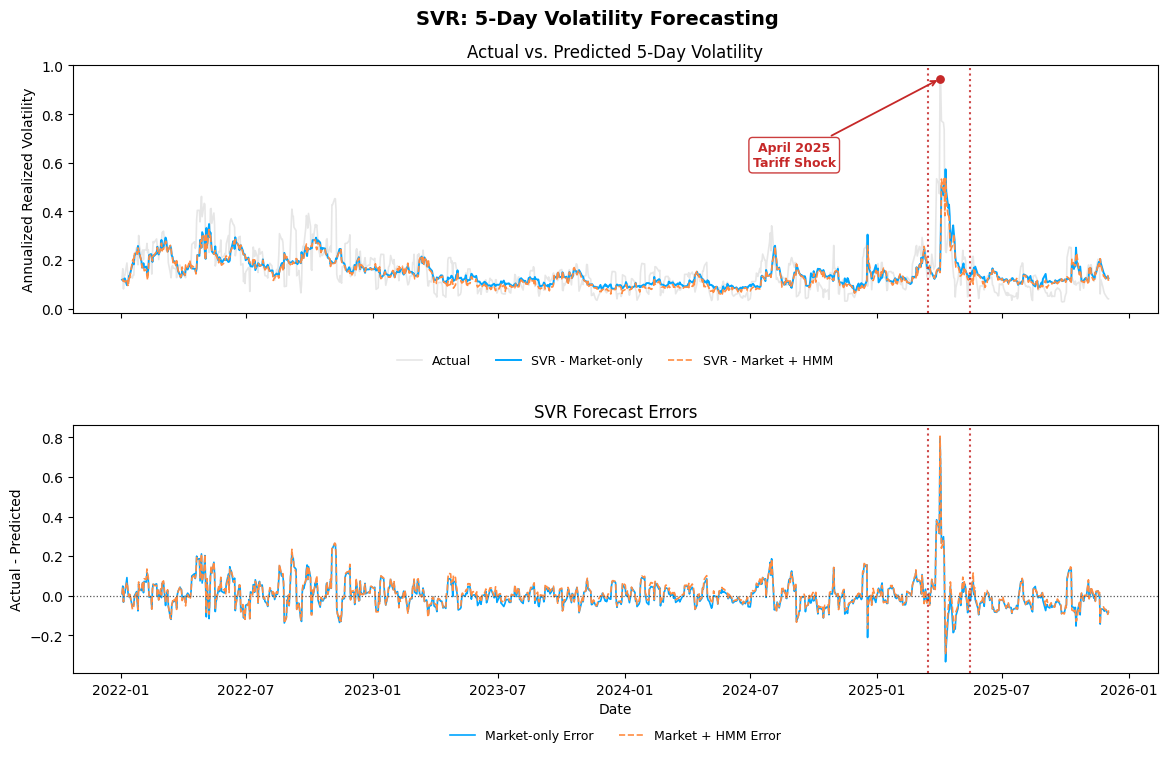

In [ ]:

# --------------------------------------------------
# 7.4 SVR Forecast Visualization and Diagnostics
# --------------------------------------------------

# Retrieve five-day testing predictions
svr_market = svr_predictions[
    (5, "Market-only", "Testing")
]

svr_hmm = svr_predictions[
    (5, "Market + HMM", "Testing")
]

# Prepare plotting data
svr_plot_df = pd.DataFrame({
    "Date": pd.to_datetime(svr_market["Date"]),
    "Actual": svr_market["Actual"],
    "Market-only": svr_market["Predicted"],
    "Market + HMM": svr_hmm["Predicted"]
})

# Calculate forecast errors (Actual - Predicted)
svr_plot_df["Market Error"] = (
    svr_plot_df["Actual"] - svr_plot_df["Market-only"]
)

svr_plot_df["HMM Error"] = (
    svr_plot_df["Actual"] - svr_plot_df["Market + HMM"]
)

# Define consistent colors
COLOR_ACTUAL = "#D3D3D3"
COLOR_SVR_MARKET = "#00A6FF"
COLOR_SVR_HMM = "#FF8C42"
COLOR_ANNOTATION = "#C62828"

# Initialize figure
fig_svr_forecasts, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# ----------------------------------------
# Panel A: Actual vs. Predicted Volatility
# ----------------------------------------

axes[0].plot(
    svr_plot_df["Date"],
    svr_plot_df["Actual"],
    color=COLOR_ACTUAL,
    linewidth=1.2,
    alpha=0.55,
    label="Actual",
    zorder=1
)

axes[0].plot(
    svr_plot_df["Date"],
    svr_plot_df["Market-only"],
    color=COLOR_SVR_MARKET,
    linewidth=1.4,
    label="SVR - Market-only",
    zorder=2
)

axes[0].plot(
    svr_plot_df["Date"],
    svr_plot_df["Market + HMM"],
    color=COLOR_SVR_HMM,
    linewidth=1.2,
    linestyle="--",
    label="SVR - Market + HMM",
    zorder=2
)

axes[0].set_title("Actual vs. Predicted 5-Day Volatility")
axes[0].set_ylabel("Annualized Realized Volatility")

# ----------------------------------------
# Annotate April 2025 Tariff Shock
# ----------------------------------------

spike_start = pd.Timestamp("2025-04-02")
spike_end = pd.Timestamp("2025-04-30")

spike_df = svr_plot_df.loc[
    svr_plot_df["Date"].between(spike_start, spike_end)
]

if spike_df.empty:
    raise ValueError(
        "No April 2025 observations available for annotation."
    )

peak_idx = spike_df["Actual"].idxmax()

peak_date = svr_plot_df.loc[peak_idx, "Date"]
peak_volatility = svr_plot_df.loc[peak_idx, "Actual"]

# Position marker slightly below the peak
dot_y = peak_volatility - 0.01

axes[0].scatter(
    peak_date,
    dot_y,
    color=COLOR_ANNOTATION,
    s=28,
    zorder=5
)

# Annotation positioned inside the chart
axes[0].annotate(
    "April 2025\nTariff Shock",
    xy=(peak_date, dot_y),
    xytext=(-105, -55),
    textcoords="offset points",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_ANNOTATION,
        linewidth=1.3
    ),
    fontsize=9,
    color=COLOR_ANNOTATION,
    fontweight="bold",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor=COLOR_ANNOTATION,
        alpha=0.9
    ),
    zorder=6
)

# ----------------------------------------
# Panel B: Forecast Errors
# ----------------------------------------

axes[1].plot(
    svr_plot_df["Date"],
    svr_plot_df["Market Error"],
    color=COLOR_SVR_MARKET,
    linewidth=1.2,
    label="Market-only Error"
)

axes[1].plot(
    svr_plot_df["Date"],
    svr_plot_df["HMM Error"],
    color=COLOR_SVR_HMM,
    linewidth=1.2,
    linestyle="--",
    label="Market + HMM Error"
)

# Zero-error reference
axes[1].axhline(
    0,
    color="#555555",
    linewidth=0.9,
    linestyle=":"
)

axes[1].set_title("SVR Forecast Errors")
axes[1].set_ylabel("Actual - Predicted")
axes[1].set_xlabel("Date")

# ----------------------------------------
# Highlight March-May 2025 Episode
# ----------------------------------------

error_window_start = pd.Timestamp("2025-03-15")
error_window_end = pd.Timestamp("2025-05-15")

for ax in axes:

    ax.axvline(
        error_window_start,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

    ax.axvline(
        error_window_end,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

# ----------------------------------------
# Legends and Final Formatting
# ----------------------------------------

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=9
)

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
    fontsize=9
)

fig_svr_forecasts.suptitle(
    "SVR: 5-Day Volatility Forecasting",
    fontsize=14,
    fontweight="bold"
)

fig_svr_forecasts.subplots_adjust(
    hspace=0.45,
    bottom=0.15,
    top=0.91
)

plt.show()


**Key Observations:**

- **Forecast behavior:** SVR and Ridge Regression capture similar volatility patterns throughout the 2022–2025 testing period.
- **April 2025 tariff shock:** Both models substantially underestimate the abrupt increase in realized volatility, producing pronounced forecast errors.
- **Model comparison:** Despite its nonlinear RBF kernel, SVR does not demonstrate a clear forecasting advantage over Ridge Regression.
- **HMM contribution:** Market-only and HMM-enhanced SVR predictions closely overlap, indicating limited incremental predictive value from regime probabilities.
- **Model limitations:** Both approaches struggle with unexpected volatility shocks, motivating further evaluation of nonlinear models and forecast failure cases.


### Section 7.5 - Summary of Support Vector Regression

- **Hyperparameter tuning:** The selected configurations favored C = 1 for the 5D and 10D horizons and C = 0.1 for 20D. All six configurations selected gamma = 0.01.
- **Forecasting performance:** Market-only SVR achieved testing RMSE values of 0.0744, 0.0694, and 0.0626 across the 5D, 10D, and 20D horizons.
- **Benchmark comparison:** SVR reduced testing RMSE by approximately 17.6%–24.0% compared with persistence.
- **Ridge comparison:** Ridge Regression achieved slightly lower testing RMSE across all six configurations.
- **HMM contribution:** Filtered regime probabilities marginally improved 5D SVR performance but provided no consistent benefit across forecasting horizons.
- **Forecast diagnostics:** Both SVR and Ridge substantially underestimated the April 2025 volatility spike, highlighting their limitations during abrupt market disruptions.

**Overall, SVR provides a competitive nonlinear forecasting benchmark but does not outperform Ridge Regression. These results motivate further investigation using XGBoost, feature ablation, and forecast failure analysis.**

## Section 8 - XGBoost Regression

XGBoost Regression is introduced to evaluate whether tree-based nonlinear modeling can improve forward realized volatility forecasting.

- **Model Approach:** Uses gradient-boosted decision trees to capture nonlinear relationships and interactions between market indicators.
- **Forecasting Setup:** Predicts volatility over 5-, 10-, and 20-day horizons using Market-only (11 predictors) and Market + HMM (14 predictors) feature sets.
- **Data Preparation:** Retains the existing chronological training, validation, and testing partitions, including the 20-day purge.
- **Model Optimization:** Tunes model complexity and learning parameters using validation RMSE.
- **Performance Evaluation:** Compares XGBoost against persistence, Ridge Regression, and SVR to assess forecasting accuracy and the incremental value of HMM regime probabilities.

### Section 8.1 - XGBoost Configuration and Hyperparameter Search Space

- Use gradient-boosted regression trees to capture nonlinear relationships and feature interactions.
- Evaluate both market-only and HMM-enhanced feature specifications across all three forecasting horizons.
- Tune the number of trees, maximum tree depth, learning rate, and subsampling ratio.
- Select hyperparameters using validation RMSE while retaining the testing partition for out-of-sample evaluation.

In [ ]:

# --------------------------------------------------
# 8.1 XGBoost Configuration
# --------------------------------------------------

from xgboost import XGBRegressor
from itertools import product

# Hyperparameter search space
XGB_PARAM_GRID = {
    "n_estimators": [100, 300],
    "max_depth": [2, 4],
    "learning_rate": [0.03, 0.10],
    "subsample": [0.8, 1.0]
}

# Build XGBoost model
def build_xgb_model(
    n_estimators,
    max_depth,
    learning_rate,
    subsample
):
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=1.0,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

# Initialize output containers
xgb_tuning_records = []
xgb_models = {}
xgb_predictions = {}
xgb_results = []

# Display configuration
n_candidates = len(list(product(*XGB_PARAM_GRID.values())))
n_total_fits = n_candidates * len(HORIZONS) * len(feature_sets)

print("XGBoost objective: Squared Error Regression")
print("Hyperparameter grid:", XGB_PARAM_GRID)
print("Candidate combinations per configuration:", n_candidates)
print("Total candidate fits:", n_total_fits)
print("Forecast horizons:", HORIZONS)
print("Feature sets:", list(feature_sets.keys()))


XGBoost objective: Squared Error Regression
Hyperparameter grid: {'n_estimators': [100, 300], 'max_depth': [2, 4], 'learning_rate': [0.03, 0.1], 'subsample': [0.8, 1.0]}
Candidate combinations per configuration: 16
Total candidate fits: 96
Forecast horizons: (5, 10, 20)
Feature sets: ['Market-only', 'Market + HMM']


### Section 8.2 - XGBoost Hyperparameter Tuning

- Train XGBoost models across all forecasting horizons and both feature sets.
- Evaluate 16 hyperparameter combinations per configuration.
- Select the optimal number of trees, maximum depth, learning rate, and subsampling ratio using validation RMSE.
- Retain the best-performing models for subsequent out-of-sample evaluation.

In [ ]:

# --------------------------------------------------
# 8.2 XGBoost Hyperparameter Tuning
# --------------------------------------------------

xgb_tuning_records = []
xgb_models = {}

for horizon in HORIZONS:

    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        X_train = train_df[features]
        y_train = train_df[target]

        X_val = val_df[features]
        y_val = val_df[target]

        best_rmse = float("inf")
        best_model = None
        best_params = None

        for n_estimators, max_depth, learning_rate, subsample in product(
            XGB_PARAM_GRID["n_estimators"],
            XGB_PARAM_GRID["max_depth"],
            XGB_PARAM_GRID["learning_rate"],
            XGB_PARAM_GRID["subsample"]
        ):

            model = build_xgb_model(
                n_estimators=n_estimators,
                max_depth=max_depth,
                learning_rate=learning_rate,
                subsample=subsample
            )

            model.fit(X_train, y_train)

            val_pred = model.predict(X_val)
            val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

            xgb_tuning_records.append({
                "Horizon": horizon,
                "Feature Set": feature_name,
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "subsample": subsample,
                "Validation RMSE": val_rmse
            })

            if val_rmse < best_rmse:
                best_rmse = val_rmse
                best_model = model
                best_params = {
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "learning_rate": learning_rate,
                    "subsample": subsample
                }

        xgb_models[(horizon, feature_name)] = {
            "Model": best_model,
            "Parameters": best_params,
            "Validation RMSE": best_rmse
        }

# Full tuning results
xgb_tuning_df = pd.DataFrame(xgb_tuning_records)

# Selected configurations
xgb_best_df = (
    xgb_tuning_df
    .sort_values("Validation RMSE")
    .groupby(["Horizon", "Feature Set"], as_index=False)
    .first()
    .sort_values(["Horizon", "Feature Set"])
    .reset_index(drop=True)
)

display(xgb_best_df.round(4))


,Horizon,Feature Set,n_estimators,max_depth,learning_rate,subsample,Validation RMSE
0,5,Market + HMM,300,2,0.0300,0.8000,0.1107
1,5,Market-only,300,2,0.0300,0.8000,0.1104
2,10,Market + HMM,300,2,0.0300,0.8000,0.1096
3,10,Market-only,100,2,0.1000,1.0000,0.1093
4,20,Market + HMM,100,2,0.0300,1.0000,0.1242
5,20,Market-only,100,2,0.0300,1.0000,0.1241


**Key Observations:**

- **Tree depth:** All configurations selected max_depth = 2, suggesting that relatively shallow trees performed best within our search space.

- **Learning rate:** Most configurations favored 0.03, indicating a preference for gradual boosting.

- **Number of trees:** The 5-day models selected 300 trees, while the 20-day models selected 100.

- **Validation performance:** RMSE ranged from 0.1093 to 0.1242, with the lowest error achieved by Market-only XGBoost at 10D.

- **HMM contribution:** Adding filtered regime probabilities slightly increased validation RMSE across all three horizons.

- **Comparison with previous models:** XGBoost achieved better validation RMSE than Ridge and SVR at 5D and 10D, but Ridge performed slightly better at 20D.

### Section 8.3 - XGBoost Forecast Evaluation

- Evaluate the selected XGBoost configurations on the validation and testing partitions.
- Calculate RMSE and MAE for each forecasting horizon and feature set.
- Compare testing performance against persistence, Ridge Regression, and SVR.
- Assess whether HMM probabilities provide additional predictive value.

In [ ]:

# --------------------------------------------------
# 8.3 XGBoost Forecast Evaluation
# --------------------------------------------------

xgb_predictions = {}
xgb_results = []

for horizon in HORIZONS:
    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        fitted_model = xgb_models[(horizon, feature_name)]["Model"]
        best_params = xgb_models[(horizon, feature_name)]["Parameters"]

        for partition_name, partition_df in evaluation_partitions.items():

            X = partition_df[features]
            y = partition_df[target].to_numpy()
            predictions = fitted_model.predict(X)

            rmse = np.sqrt(mean_squared_error(y, predictions))
            mae = mean_absolute_error(y, predictions)

            xgb_predictions[(horizon, feature_name, partition_name)] = {
                "Date": partition_df["Date"].to_numpy(),
                "Actual": y,
                "Predicted": predictions
            }

            xgb_results.append({
                "Model": "XGBoost",
                "Feature Set": feature_name,
                "Partition": partition_name,
                "Horizon": horizon,
                "RMSE": rmse,
                "MAE": mae
            })

xgb_results_df = pd.DataFrame(xgb_results)

# Display validation and testing metrics
display(
    xgb_results_df
    .sort_values(["Partition", "Horizon", "Feature Set"])
    .round(4)
)

# Compare all supervised models against persistence on testing data
comparison_df = (
    xgb_results_df[xgb_results_df["Partition"] == "Testing"]
    [["Horizon", "Feature Set", "RMSE"]]
    .rename(columns={"RMSE": "XGBoost RMSE"})
    .merge(
        ridge_results_df[ridge_results_df["Partition"] == "Testing"]
        [["Horizon", "Feature Set", "RMSE"]]
        .rename(columns={"RMSE": "Ridge RMSE"}),
        on=["Horizon", "Feature Set"]
    )
    .merge(
        svr_results_df[svr_results_df["Partition"] == "Testing"]
        [["Horizon", "Feature Set", "RMSE"]]
        .rename(columns={"RMSE": "SVR RMSE"}),
        on=["Horizon", "Feature Set"]
    )
    .merge(
        benchmark_results_df[benchmark_results_df["Partition"] == "Testing"]
        [["Horizon", "RMSE"]]
        .rename(columns={"RMSE": "Persistence RMSE"}),
        on="Horizon"
    )
)

comparison_df["XGBoost Improvement (%)"] = (
    1 - comparison_df["XGBoost RMSE"]
    / comparison_df["Persistence RMSE"]
) * 100

display(
    comparison_df
    .sort_values(["Horizon", "Feature Set"])
    .round(4)
)


,Model,Feature Set,Partition,Horizon,RMSE,MAE
3,XGBoost,Market + HMM,Testing,5,0.0761,0.0500
1,XGBoost,Market-only,Testing,5,0.0756,0.0497
7,XGBoost,Market + HMM,Testing,10,0.0704,0.0428
5,XGBoost,Market-only,Testing,10,0.0697,0.0428
11,XGBoost,Market + HMM,Testing,20,0.0645,0.0399
9,XGBoost,Market-only,Testing,20,0.0642,0.0398
2,XGBoost,Market + HMM,Validation,5,0.1107,0.0706
0,XGBoost,Market-only,Validation,5,0.1104,0.0708
6,XGBoost,Market + HMM,Validation,10,0.1096,0.0675
4,XGBoost,Market-only,Validation,10,0.1093,0.0667


,Horizon,Feature Set,XGBoost RMSE,Ridge RMSE,SVR RMSE,Persistence RMSE,XGBoost Improvement (%)
1,5,Market + HMM,0.0761,0.0740,0.0741,0.0974,21.8858
0,5,Market-only,0.0756,0.0738,0.0744,0.0974,22.3541
3,10,Market + HMM,0.0704,0.0673,0.0699,0.0849,17.0938
2,10,Market-only,0.0697,0.0670,0.0694,0.0849,17.8384
5,20,Market + HMM,0.0645,0.0611,0.0626,0.0761,15.2544
4,20,Market-only,0.0642,0.0607,0.0626,0.0761,15.6705


**Key Observations:**
- **Testing performance:** Market-only XGBoost achieved RMSE values of 0.0756, 0.0697, and 0.0642 across the 5D, 10D, and 20D horizons.
- **Benchmark comparison:** XGBoost improved RMSE over persistence by approximately 15.3%–22.4% across all six configurations.
- **Model comparison:** Ridge Regression consistently achieved the lowest testing RMSE, followed by SVR and XGBoost.
- **HMM contribution:** Adding filtered regime probabilities slightly increased testing RMSE at every forecasting horizon.
- **Generalization:** XGBoost's validation advantage at shorter horizons did not persist during testing, highlighting the importance of evaluating models across different market periods.

**Overall, XGBoost demonstrates competitive nonlinear forecasting performance but does not outperform Ridge Regression or provide evidence of incremental predictive value from HMM regime probabilities.**

### Section 8.4 - XGBoost Forecast Visualization and Diagnostics

- **Forecast comparison:** Compare actual 5-day realized volatility with XGBoost predictions from both feature sets.
- **Forecast errors:** Examine prediction errors to identify periods of underestimation and overestimation.
- **Market disruption:** Highlight the March–May 2025 volatility episode associated with U.S. tariff announcements.
- **Model comparison:** Assess whether XGBoost exhibits different forecasting behavior from Ridge Regression and SVR during periods of elevated volatility.

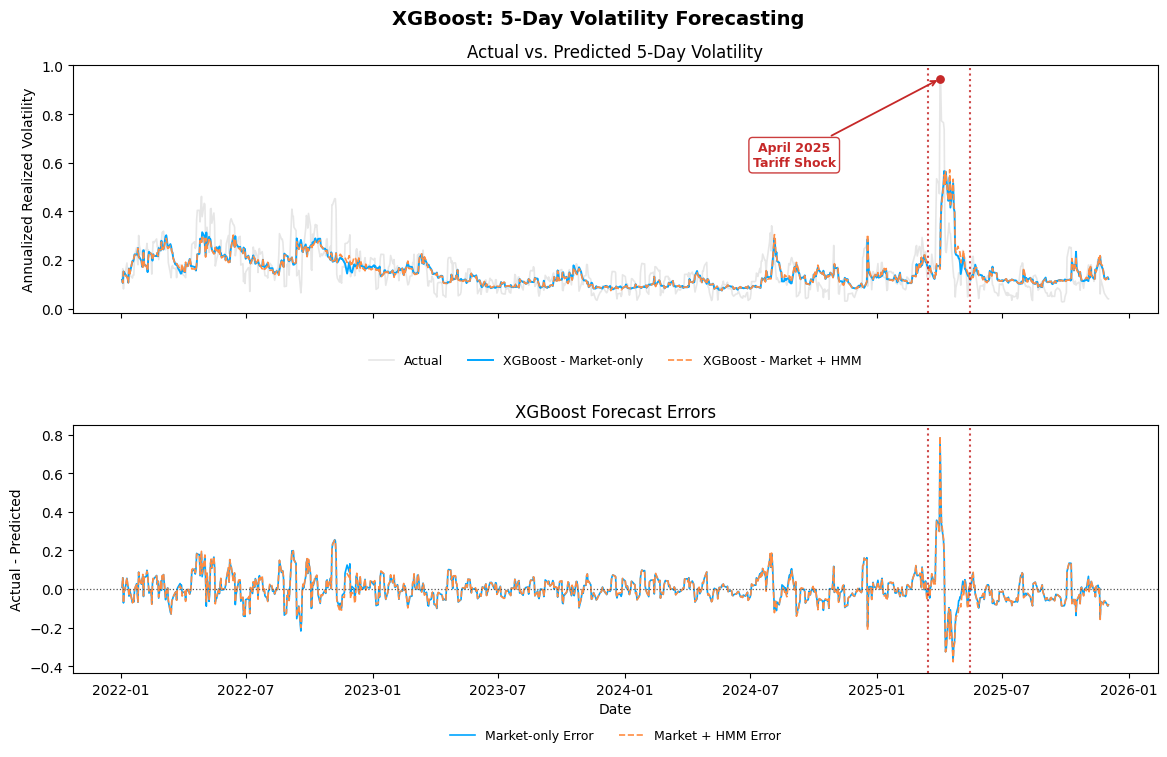

In [ ]:

# --------------------------------------------------
# 8.4 XGBoost Forecast Visualization and Diagnostics
# --------------------------------------------------

# Retrieve five-day testing predictions
xgb_market = xgb_predictions[
    (5, "Market-only", "Testing")
]

xgb_hmm = xgb_predictions[
    (5, "Market + HMM", "Testing")
]

# Prepare plotting data
xgb_plot_df = pd.DataFrame({
    "Date": pd.to_datetime(xgb_market["Date"]),
    "Actual": xgb_market["Actual"],
    "Market-only": xgb_market["Predicted"],
    "Market + HMM": xgb_hmm["Predicted"]
})

# Calculate forecast errors (Actual - Predicted)
xgb_plot_df["Market Error"] = (
    xgb_plot_df["Actual"] - xgb_plot_df["Market-only"]
)

xgb_plot_df["HMM Error"] = (
    xgb_plot_df["Actual"] - xgb_plot_df["Market + HMM"]
)

# Define colors consistent with previous figures
COLOR_ACTUAL = "#D3D3D3"
COLOR_XGB_MARKET = "#00A6FF"
COLOR_XGB_HMM = "#FF8C42"
COLOR_ANNOTATION = "#C62828"

# Initialize figure
fig_xgb_forecasts, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# ----------------------------------------
# Panel A: Actual vs. Predicted Volatility
# ----------------------------------------

axes[0].plot(
    xgb_plot_df["Date"],
    xgb_plot_df["Actual"],
    color=COLOR_ACTUAL,
    linewidth=1.2,
    alpha=0.55,
    label="Actual",
    zorder=1
)

axes[0].plot(
    xgb_plot_df["Date"],
    xgb_plot_df["Market-only"],
    color=COLOR_XGB_MARKET,
    linewidth=1.4,
    label="XGBoost - Market-only",
    zorder=2
)

axes[0].plot(
    xgb_plot_df["Date"],
    xgb_plot_df["Market + HMM"],
    color=COLOR_XGB_HMM,
    linewidth=1.2,
    linestyle="--",
    label="XGBoost - Market + HMM",
    zorder=2
)

axes[0].set_title("Actual vs. Predicted 5-Day Volatility")
axes[0].set_ylabel("Annualized Realized Volatility")

# ----------------------------------------
# Annotate April 2025 Tariff Shock
# ----------------------------------------

spike_start = pd.Timestamp("2025-04-02")
spike_end = pd.Timestamp("2025-04-30")

spike_df = xgb_plot_df.loc[
    xgb_plot_df["Date"].between(spike_start, spike_end)
]

if spike_df.empty:
    raise ValueError(
        "No April 2025 observations available for annotation."
    )

peak_idx = spike_df["Actual"].idxmax()

peak_date = xgb_plot_df.loc[peak_idx, "Date"]
peak_volatility = xgb_plot_df.loc[peak_idx, "Actual"]

# Position marker slightly below the peak
dot_y = peak_volatility - 0.01

axes[0].scatter(
    peak_date,
    dot_y,
    color=COLOR_ANNOTATION,
    s=28,
    zorder=5
)

# Annotation inside the chart
axes[0].annotate(
    "April 2025\nTariff Shock",
    xy=(peak_date, dot_y),
    xytext=(-105, -55),
    textcoords="offset points",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_ANNOTATION,
        linewidth=1.3
    ),
    fontsize=9,
    color=COLOR_ANNOTATION,
    fontweight="bold",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor=COLOR_ANNOTATION,
        alpha=0.9
    ),
    zorder=6
)

# ----------------------------------------
# Panel B: Forecast Errors
# ----------------------------------------

axes[1].plot(
    xgb_plot_df["Date"],
    xgb_plot_df["Market Error"],
    color=COLOR_XGB_MARKET,
    linewidth=1.2,
    label="Market-only Error"
)

axes[1].plot(
    xgb_plot_df["Date"],
    xgb_plot_df["HMM Error"],
    color=COLOR_XGB_HMM,
    linewidth=1.2,
    linestyle="--",
    label="Market + HMM Error"
)

# Zero-error reference
axes[1].axhline(
    0,
    color="#555555",
    linewidth=0.9,
    linestyle=":"
)

axes[1].set_title("XGBoost Forecast Errors")
axes[1].set_ylabel("Actual - Predicted")
axes[1].set_xlabel("Date")

# ----------------------------------------
# Highlight March-May 2025 Episode
# ----------------------------------------

error_window_start = pd.Timestamp("2025-03-15")
error_window_end = pd.Timestamp("2025-05-15")

for ax in axes:

    ax.axvline(
        error_window_start,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

    ax.axvline(
        error_window_end,
        color=COLOR_ANNOTATION,
        linestyle=":",
        linewidth=1.5,
        alpha=0.85
    )

# ----------------------------------------
# Legends and Final Formatting
# ----------------------------------------

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=9
)

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
    fontsize=9
)

fig_xgb_forecasts.suptitle(
    "XGBoost: 5-Day Volatility Forecasting",
    fontsize=14,
    fontweight="bold"
)

fig_xgb_forecasts.subplots_adjust(
    hspace=0.45,
    bottom=0.15,
    top=0.91
)

plt.show()


**Key Observations:**

- **Forecast behavior:** XGBoost follows general volatility movements but exhibits occasional sharp forecast adjustments.
- **April 2025 tariff shock:** The model substantially underestimates the initial volatility spike, followed by forecast errors in the opposite direction as market conditions change.
- **HMM contribution:** Both feature specifications produce closely aligned forecasts, indicating limited incremental predictive value from filtered regime probabilities.
- **Model comparison:** XGBoost does not demonstrate a forecasting advantage over Ridge Regression or SVR during the testing period.

**Overall, the visualization reinforces the limitations of nonlinear models in anticipating abrupt volatility shocks**


### Section 8.5 - Summary of XGBoost Regression

- **Hyperparameter tuning:** All configurations favored shallow trees (max_depth = 2), with most selecting a learning rate of 0.03.
- **Forecasting performance:** Market-only XGBoost achieved testing RMSE values of 0.0756, 0.0697, and 0.0642 across the 5D, 10D, and 20D horizons.
- **Benchmark comparison:** XGBoost improved testing RMSE by approximately 15.3%–22.4% compared with persistence.
- **Model comparison:** Despite stronger validation performance at shorter horizons, XGBoost underperformed Ridge Regression and SVR on testing RMSE.
- **HMM contribution:** Adding filtered regime probabilities slightly worsened testing performance across all forecasting horizons.
- **Forecast diagnostics:** XGBoost's response to the April 2025 tariff-related volatility episode was on par with the other comparative models. the model understated the volatility

**Overall, XGBoost demonstrates competitive nonlinear forecasting performance, but Ridge Regression remains the strongest model based on testing RMSE. The limited benefits from incorporating HMM probabilities motivate further evaluation through cross-model comparisons, feature ablation, and robustness testing.**

## Section 9 - Cross Model Comparison and Evaluation

Having evaluated each forecasting model individually, this section brings together their results to assess overall predictive performance and the contribution of HMM regime information.

The comparison focuses on four key areas:

- **Forecasting Accuracy:** Compare persistence, Ridge Regression, SVR, and XGBoost using testing RMSE and MAE across the 5-, 10-, and 20-day horizons.
- **HMM Contribution:** Determine whether incorporating filtered regime probabilities improves predictions relative to market-only features.
- **Model Performance:** Examine whether nonlinear approaches provide an advantage over linear regression.
- **Forecast Diagnostics:** Investigate differences in forecasting errors, particularly during the April 2025 tariff-related volatility shock.

The objective is to identify the most reliable forecasting approach and assess whether the market regimes identified by Model B provide additional predictive value for Model A.

### Section 9.1 - Overall Forecast Performance

This subsection compares all four approaches using the same held-out testing period. We'll begin with a consolidated results table and a figure showing RMSE across forecasting horizons.

- Consolidate testing RMSE and MAE for the persistence benchmark and all supervised models.
- Compare forecasting accuracy across the three horizons.
- Identify the best-performing model within each feature specification.
- Visualize differences in testing RMSE across models.

In [ ]:

# --------------------------------------------------
# 9.1 Overall Forecasting Performance
# --------------------------------------------------

# Combine evaluation results
all_results_df = pd.concat(
    [
        benchmark_results_df,
        ridge_results_df,
        svr_results_df,
        xgb_results_df
    ],
    ignore_index=True
)

# Restrict to testing observations
test_results_df = (
    all_results_df[
        all_results_df["Partition"] == "Testing"
    ]
    .copy()
)

# Label persistence separately because it has no feature set
test_results_df["Feature Set"] = (
    test_results_df["Feature Set"].fillna("Benchmark")
)

# Select relevant columns
test_results_df = (
    test_results_df[
        ["Model", "Feature Set", "Horizon", "RMSE", "MAE"]
    ]
    .sort_values(["Horizon", "Model", "Feature Set"])
    .reset_index(drop=True)
)

# ----------------------------------------
# Calculate RMSE Improvement Over Persistence
# ----------------------------------------

# Retrieve persistence RMSE for each forecasting horizon
persistence_rmse = (
    test_results_df[
        test_results_df["Model"] == "Persistence"
    ]
    .set_index("Horizon")["RMSE"]
)

# Percentage improvement relative to persistence
test_results_df["RMSE Improvement (%)"] = (
    1 - test_results_df["RMSE"] /
    test_results_df["Horizon"].map(persistence_rmse)
) * 100

# Display consolidated testing results
print("Consolidated Testing Performance:")
display(
    test_results_df
    .sort_values(["Horizon", "Model", "Feature Set"])
    .round(4)
)

# ----------------------------------------
# Identify Best-Performing Model per Horizon
# ----------------------------------------

best_models_df = (
    test_results_df
    .sort_values("RMSE")
    .groupby("Horizon", as_index=False)
    .first()
    .sort_values("Horizon")
)

print("\nBest-Performing Model by Horizon:")
display(best_models_df.round(4))



Consolidated Testing Performance:


,Model,Feature Set,Horizon,RMSE,MAE,RMSE Improvement (%)
0,Persistence,Benchmark,5,0.0974,0.0647,0.0000
1,Ridge,Market + HMM,5,0.0740,0.0494,24.0510
2,Ridge,Market-only,5,0.0738,0.0492,24.2298
3,SVR,Market + HMM,5,0.0741,0.0489,23.9536
4,SVR,Market-only,5,0.0744,0.0492,23.6176
5,XGBoost,Market + HMM,5,0.0761,0.0500,21.8858
6,XGBoost,Market-only,5,0.0756,0.0497,22.3541
7,Persistence,Benchmark,10,0.0849,0.0543,0.0000
8,Ridge,Market + HMM,10,0.0673,0.0428,20.6664
9,Ridge,Market-only,10,0.0670,0.0427,21.1087



Best-Performing Model by Horizon:


,Horizon,Model,Feature Set,RMSE,MAE,RMSE Improvement (%)
0,5,Ridge,Market-only,0.0738,0.0492,24.2298
1,10,Ridge,Market-only,0.0670,0.0427,21.1087
2,20,Ridge,Market-only,0.0607,0.0392,20.2223


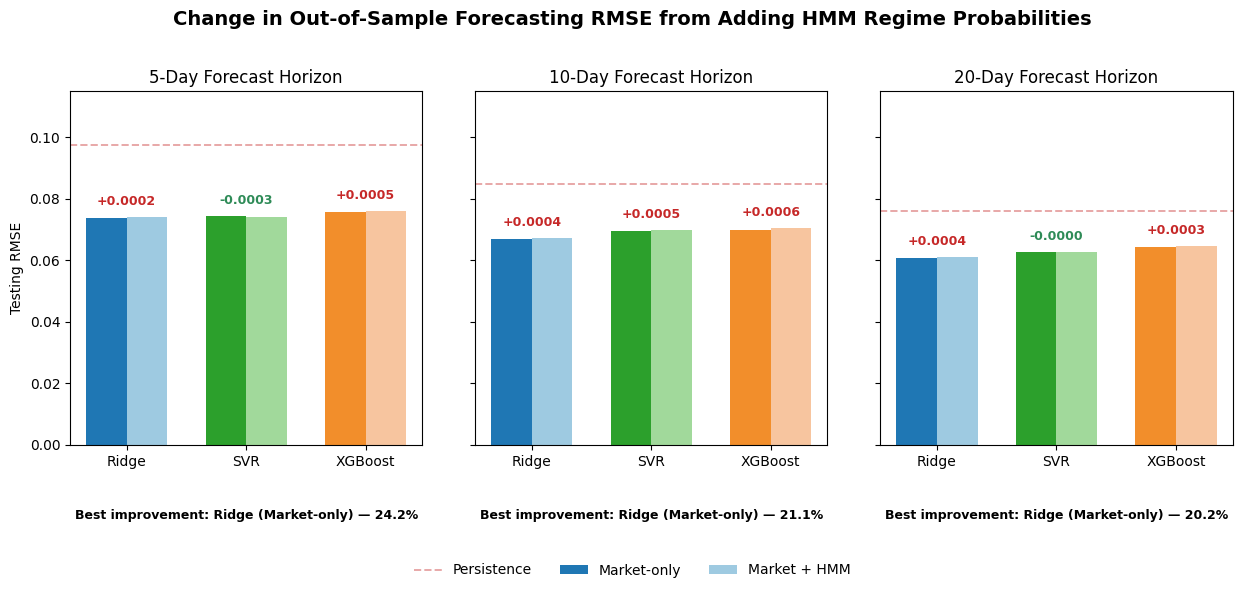

In [ ]:

# --------------------------------------------------
# 9.1 Testing RMSE Comparison Figure
# --------------------------------------------------

model_order = ["Ridge", "SVR", "XGBoost"]
horizons = [5, 10, 20]

# Color families by model
# Darker shade = Market-only
# Lighter shade = Market + HMM

MODEL_COLORS = {
    "Ridge": {
        "Market-only": "#1f77b4",
        "Market + HMM": "#9ecae1"
    },
    "SVR": {
        "Market-only": "#2ca02c",
        "Market + HMM": "#a1d99b"
    },
    "XGBoost": {
        "Market-only": "#f28e2b",
        "Market + HMM": "#f7c59f"
    }
}

COLOR_BENCHMARK = "#C62828"

# Initialize figure and retain variable for export
fig_model_comparison, axes = plt.subplots(
    1, 3,
    figsize=(15, 5.8),
    sharey=True
)

for ax, horizon in zip(axes, horizons):

    horizon_df = test_results_df[
        test_results_df["Horizon"] == horizon
    ]

    x = np.arange(len(model_order))
    width = 0.34

    # Persistence benchmark
    benchmark_rmse = horizon_df.loc[
        horizon_df["Model"] == "Persistence",
        "RMSE"
    ].iloc[0]

    # ----------------------------------------
    # Plot model comparisons
    # ----------------------------------------

    for i, model in enumerate(model_order):

        market_rmse = horizon_df.loc[
            (horizon_df["Model"] == model) &
            (horizon_df["Feature Set"] == "Market-only"),
            "RMSE"
        ].iloc[0]

        hmm_rmse = horizon_df.loc[
            (horizon_df["Model"] == model) &
            (horizon_df["Feature Set"] == "Market + HMM"),
            "RMSE"
        ].iloc[0]

        # Calculate incremental HMM impact
        delta_rmse = hmm_rmse - market_rmse

        # Market-only bar
        ax.bar(
            x[i] - width / 2,
            market_rmse,
            width,
            color=MODEL_COLORS[model]["Market-only"],
            label="Market-only" if i == 0 else ""
        )

        # Market + HMM bar
        ax.bar(
            x[i] + width / 2,
            hmm_rmse,
            width,
            color=MODEL_COLORS[model]["Market + HMM"],
            label="Market + HMM" if i == 0 else ""
        )

        # ----------------------------------------
        # HMM impact annotation
        # ----------------------------------------

        pair_max = max(market_rmse, hmm_rmse)

        impact_color = (
            "#2E8B57" if delta_rmse < 0
            else "#C62828" if delta_rmse > 0
            else "#555555"
        )

        ax.text(
            x[i],
            pair_max + 0.003,
            f"{delta_rmse:+.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color=impact_color
        )

    # ----------------------------------------
    # Persistence reference line
    # ----------------------------------------

    ax.axhline(
        benchmark_rmse,
        color=COLOR_BENCHMARK,
        linestyle="--",
        linewidth=1.4,
        alpha=0.40,
        label="Persistence" if horizon == horizons[0] else ""
    )

    # ----------------------------------------
    # Best-model improvement annotation
    # ----------------------------------------

    best_row = best_models_df[
        best_models_df["Horizon"] == horizon
    ].iloc[0]

    improvement = best_row["RMSE Improvement (%)"]
    best_model = best_row["Model"]
    best_feature_set = best_row["Feature Set"]

    ax.text(
        0.5,
        -0.18,
        (
            f"Best improvement: {best_model} "
            f"({best_feature_set}) — {improvement:.1f}%"
        ),
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

    # ----------------------------------------
    # Axis formatting
    # ----------------------------------------

    ax.set_xticks(x)
    ax.set_xticklabels(model_order)
    ax.set_title(f"{horizon}-Day Forecast Horizon")
    ax.set_ylim(0, 0.115)

axes[0].set_ylabel("Testing RMSE")

# ----------------------------------------
# Shared Legend
# ----------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig_model_comparison.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=3,
    frameon=False
)

# ----------------------------------------
# Final Figure Formatting
# ----------------------------------------

fig_model_comparison.suptitle(
    "Change in Out-of-Sample Forecasting RMSE from Adding HMM Regime Probabilities",
    fontsize=14,
    fontweight="bold"
)

fig_model_comparison.subplots_adjust(
    bottom=0.23,
    top=0.84,
    wspace=0.15
)

plt.show()


**Key Observations:**

- **Best-performing model:** Market-only Ridge achieved RMSE values of 0.0738 (5D), 0.0670 (10D), and 0.0607 (20D).

- **Linear vs. nonlinear models:** Ridge consistently outperformed SVR and XGBoost on testing RMSE, suggesting that additional model complexity did not improve overall forecasting accuracy.

- **Benchmark improvement:** Relative to persistence, Market-only Ridge reduced RMSE by **24.2% (5D), 21.1% (10D), and 20.2% (20D)**.

- **HMM contribution:** Adding filtered regime probabilities did not consistently improve results. Market-only specifications generally performed better.

- **Forecast horizons:** RMSE decreased with longer horizons across all models, although the different targets have different volatility distributions.

### Section 9.2 - Incremental Contribution of HMM Regime Probabilities

This subsection evaluates the additional predictive value of the market regimes identified by Model B.

- **Feature Comparison:** Compare Market-only and Market + HMM specifications for Ridge Regression, SVR, and XGBoost.
- **Incremental Impact:** Calculate the absolute and percentage change in testing RMSE after incorporating filtered regime probabilities.
- **Cross-Model Analysis:** Examine whether the contribution of HMM information varies across model families and forecasting horizons.
- **Interpretation:** Determine whether the inferred market regimes provide meaningful additional forecasting information beyond conventional market indicators.

A negative change in RMSE indicates improved forecasting accuracy, while a positive change indicates deterioration.

In [ ]:

# --------------------------------------------------
# 9.2 Incremental Contribution of HMM Probabilities
# --------------------------------------------------

# Keep supervised model results only
hmm_comparison_df = test_results_df[
    test_results_df["Model"].isin(["Ridge", "SVR", "XGBoost"])
].copy()

# Compare feature specifications
hmm_impact_df = (
    hmm_comparison_df
    .pivot(
        index=["Model", "Horizon"],
        columns="Feature Set",
        values="RMSE"
    )
    .reset_index()
)

# Absolute RMSE change
hmm_impact_df["RMSE Change"] = (
    hmm_impact_df["Market + HMM"]
    - hmm_impact_df["Market-only"]
)

# Percentage change relative to Market-only
hmm_impact_df["RMSE Change (%)"] = (
    hmm_impact_df["RMSE Change"]
    / hmm_impact_df["Market-only"]
) * 100

# Interpretation
hmm_impact_df["HMM Impact"] = np.select(
    [
        hmm_impact_df["RMSE Change"] < 0,
        hmm_impact_df["RMSE Change"] > 0
    ],
    [
        "Improved",
        "Worsened"
    ],
    default="Unchanged"
)

# Sort results
hmm_impact_df = (
    hmm_impact_df
    .sort_values(["Horizon", "Model"])
    .reset_index(drop=True)
)

display(hmm_impact_df.round(4))


Feature Set,Model,Horizon,Market + HMM,Market-only,RMSE Change,RMSE Change (%),HMM Impact
0,Ridge,5,0.0740,0.0738,0.0002,0.2359,Worsened
1,SVR,5,0.0741,0.0744,-0.0003,-0.4399,Improved
2,XGBoost,5,0.0761,0.0756,0.0005,0.6031,Worsened
3,Ridge,10,0.0673,0.0670,0.0004,0.5606,Worsened
4,SVR,10,0.0699,0.0694,0.0005,0.6686,Worsened
5,XGBoost,10,0.0704,0.0697,0.0006,0.9063,Worsened
6,Ridge,20,0.0611,0.0607,0.0004,0.6628,Worsened
7,SVR,20,0.0626,0.0626,-0.0000,-0.0175,Improved
8,XGBoost,20,0.0645,0.0642,0.0003,0.4935,Worsened


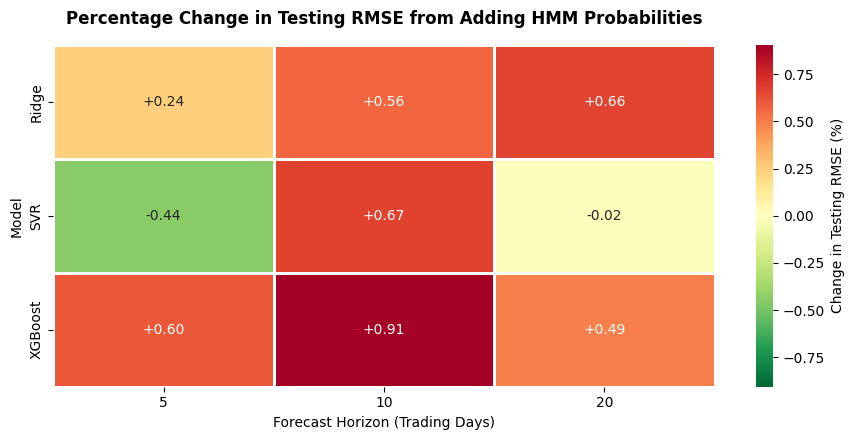

In [ ]:

# --------------------------------------------------
# 9.2 HMM Contribution Heatmap
# --------------------------------------------------

# Prepare heatmap data
hmm_heatmap_df = (
    hmm_impact_df
    .pivot(
        index="Model",
        columns="Horizon",
        values="RMSE Change (%)"
    )
    .reindex(
        index=["Ridge", "SVR", "XGBoost"],
        columns=[5, 10, 20]
    )
)

# Initialize figure for export
fig_hmm_contribution, ax = plt.subplots(
    figsize=(9, 4.5)
)

# Symmetric scale around zero
color_limit = max(
    abs(hmm_heatmap_df.min().min()),
    abs(hmm_heatmap_df.max().max())
)

sns.heatmap(
    hmm_heatmap_df,
    annot=True,
    fmt="+.2f",
    cmap="RdYlGn_r",
    center=0,
    vmin=-color_limit,
    vmax=color_limit,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Change in Testing RMSE (%)"},
    ax=ax
)

ax.set_title(
    "Percentage Change in Testing RMSE from Adding HMM Probabilities",
    fontsize=12,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Forecast Horizon (Trading Days)")
ax.set_ylabel("Model")

fig_hmm_contribution.tight_layout()

plt.show()


**Key Observations:**

- **Overall Contribution:** HMM probabilities increased testing RMSE in seven of the nine model–horizon combinations, indicating slightly weaker forecasting performance.

- **Ridge Regression:** RMSE increased by 0.24%, 0.56%, and 0.66% across the 5D, 10D, and 20D horizons, respectively.

- **SVR:** HMM information improved performance slightly at 5D (−0.44%) and 20D (−0.02%), but worsened performance at 10D (+0.67%).

- **XGBoost:** RMSE increased at every forecasting horizon, with the largest deterioration occurring at 10D (+0.91%).

- **Magnitude of Impact:** All absolute changes were below 1%, suggesting that the additional predictive value of HMM probabilities was limited.

**The results suggest that HMM regime probabilities provide little additional predictive value beyond conventional market indicators. However, these findings do not diminish Model B's usefulness for identifying and interpreting market regimes.**

### Section 9.3 - Comparative Forecast Diagnostics

This subsection examines how forecasting performance changes during periods of market disruption, focusing on the March–May 2025 tariff-related volatility episode.

1. **Event Comparison:** Compare forecasting errors during the tariff-shock window against the remaining testing period.
2. **Model Performance:** Evaluate Ridge Regression, SVR, and XGBoost using RMSE and MAE.
3. **HMM Contribution:** Assess whether adding filtered regime probabilities improves forecasting accuracy during market stress.
4. **Forecast Limitations:** Identify differences in model performance when volatility changes abruptly.

In [ ]:

# --------------------------------------------------
# 9.3 Comparative Forecast Diagnostics
# --------------------------------------------------

EVENT_START = pd.Timestamp("2025-03-15")
EVENT_END = pd.Timestamp("2025-05-15")

# Existing stored prediction dictionaries
model_predictions = {
    "Ridge": ridge_predictions,
    "SVR": svr_predictions,
    "XGBoost": xgb_predictions
}

event_records = []

for model_name, predictions_dict in model_predictions.items():

    for feature_name in feature_sets:

        result = predictions_dict[
            (5, feature_name, "Testing")
        ]

        df = pd.DataFrame({
            "Date": pd.to_datetime(result["Date"]),
            "Actual": result["Actual"],
            "Predicted": result["Predicted"]
        })

        df["Period"] = np.where(
            df["Date"].between(EVENT_START, EVENT_END),
            "Tariff-shock window",
            "Other testing dates"
        )

        for period, group in df.groupby("Period"):

            rmse = np.sqrt(
                mean_squared_error(
                    group["Actual"],
                    group["Predicted"]
                )
            )

            mae = mean_absolute_error(
                group["Actual"],
                group["Predicted"]
            )

            event_records.append({
                "Model": model_name,
                "Feature Set": feature_name,
                "Period": period,
                "Observations": len(group),
                "RMSE": rmse,
                "MAE": mae
            })

event_comparison_df = pd.DataFrame(event_records)

display(
    event_comparison_df
    .sort_values(["Model", "Feature Set", "Period"])
    .round(4)
)


,Model,Feature Set,Period,Observations,RMSE,MAE
2,Ridge,Market + HMM,Other testing dates,940,0.0600,0.0453
3,Ridge,Market + HMM,Tariff-shock window,43,0.2152,0.1385
0,Ridge,Market-only,Other testing dates,940,0.0599,0.0451
1,Ridge,Market-only,Tariff-shock window,43,0.2149,0.1387
6,SVR,Market + HMM,Other testing dates,940,0.0606,0.0450
7,SVR,Market + HMM,Tariff-shock window,43,0.2125,0.1324
4,SVR,Market-only,Other testing dates,940,0.0600,0.0449
5,SVR,Market-only,Tariff-shock window,43,0.2186,0.1430
10,XGBoost,Market + HMM,Other testing dates,940,0.0598,0.0446
11,XGBoost,Market + HMM,Tariff-shock window,43,0.2325,0.1661


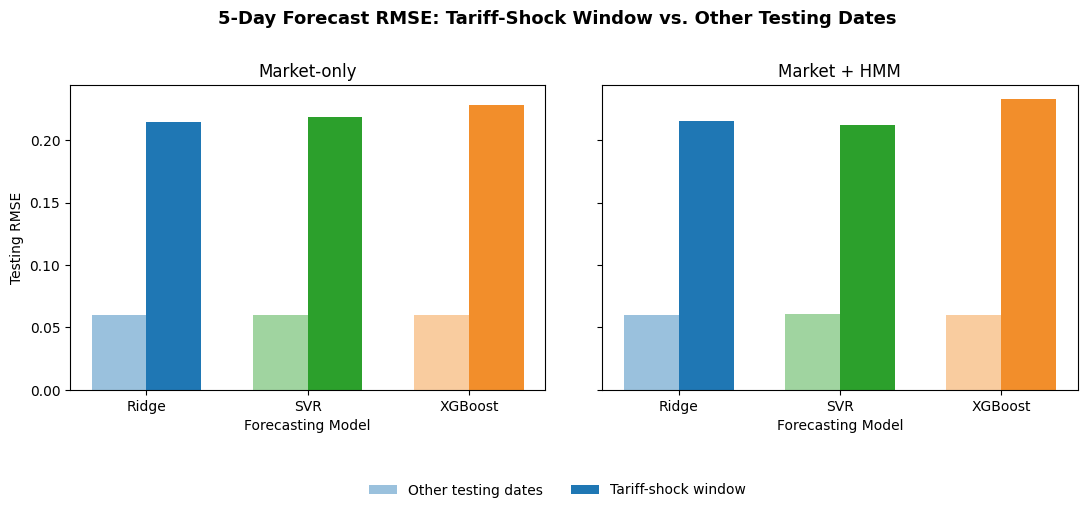

In [ ]:

# --------------------------------------------------
# 9.3 Event-Window RMSE Comparison Figure
# --------------------------------------------------

MODEL_COLORS = {
    "Ridge": "#1f77b4",
    "SVR": "#2ca02c",
    "XGBoost": "#f28e2b"
}

period_order = ["Other testing dates", "Tariff-shock window"]
feature_order = ["Market-only", "Market + HMM"]
model_order = ["Ridge", "SVR", "XGBoost"]

fig_event_comparison, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

for ax, feature_name in zip(axes, feature_order):

    subset = event_comparison_df[
        event_comparison_df["Feature Set"] == feature_name
    ]

    x = np.arange(len(model_order))
    width = 0.34

    for j, period in enumerate(period_order):

        rmse_values = [
            subset.loc[
                (subset["Model"] == model) &
                (subset["Period"] == period),
                "RMSE"
            ].iloc[0]
            for model in model_order
        ]

        positions = x + (j - 0.5) * width

        bars = ax.bar(
            positions,
            rmse_values,
            width,
            color=[
                MODEL_COLORS[model]
                for model in model_order
            ],
            alpha=0.45 if j == 0 else 1.0,
            label=period
        )

    ax.set_xticks(x)
    ax.set_xticklabels(model_order)
    ax.set_title(feature_name)
    ax.set_xlabel("Forecasting Model")

axes[0].set_ylabel("Testing RMSE")

handles, labels = axes[0].get_legend_handles_labels()

fig_event_comparison.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False
)

fig_event_comparison.suptitle(
    "5-Day Forecast RMSE: Tariff-Shock Window vs. Other Testing Dates",
    fontsize=13,
    fontweight="bold"
)

fig_event_comparison.subplots_adjust(
    bottom=0.22,
    top=0.83,
    wspace=0.12
)

plt.show()


**Key Observations:**

- **Overall Impact:** Forecasting errors increased substantially during the March–May 2025 tariff-shock window, which contained 43 observations compared with 940 observations outside the window.

- **Ridge Regression:** Market-only RMSE increased from 0.0599 outside the shock window to 0.2149 during the shock, approximately 3.6 times higher.

- **SVR:** The HMM-enhanced specification achieved the lowest shock-window RMSE (0.2125), outperforming Market-only SVR (0.2186).

- **XGBoost:** Market-only RMSE reached 0.2285 during the shock window, increasing to 0.2325 with HMM probabilities, indicating weaker performance relative to Ridge and SVR.

- **HMM Contribution:** While regime probabilities offered limited benefits overall, their inclusion improved SVR performance during the tariff-shock window, suggesting potential value under specific market conditions.


### Section 9.5 - Summary of Cross Model Evaluation

**Key Observations:**

The comparative evaluation reveals that simpler forecasting approaches generally performed better than more complex nonlinear models, while HMM regime probabilities provided limited incremental predictive value.


1. **Overall Model Performance:** Market-only Ridge Regression achieved the lowest testing RMSE across all three forecasting horizons: 0.0738 (5D), 0.0670 (10D), and 0.0607 (20D).

2. **Benchmark Improvement:** Ridge Regression reduced RMSE relative to persistence by 24.2%, 21.1%, and 20.2% across the 5D, 10D, and 20D horizons, respectively.

3. **Linear vs. Nonlinear Models:** SVR and XGBoost did not outperform Ridge Regression on overall testing RMSE, suggesting that additional nonlinear complexity did not translate into improved forecasting accuracy.

4. **HMM Contribution:** Adding filtered regime probabilities increased RMSE in seven of nine model–horizon combinations. All percentage changes remained below 1% in absolute terms, indicating limited incremental predictive value.

5. **Forecasting During Market Stress:** RMSE increased substantially across all models during the March–May 2025 tariff-shock window. Market-only Ridge Regression recorded an RMSE of 0.2149, compared with 0.0599 outside the window.

6. **Regime Information During Stress:** HMM-enhanced SVR achieved the lowest shock-window RMSE (0.2125), compared with 0.2186 for Market-only SVR. This suggests a potential conditional benefit from regime information, although the finding is limited to a single market episode.

**Overall Conclusion:** Market-only Ridge Regression emerged as the strongest forecasting specification based on testing RMSE. While HMM regime probabilities did not consistently improve overall accuracy, their potential contribution during market disruptions warrants further investigation through robustness and sensitivity testing.


## Section 10 - Robustness and Sensitivity Analysis

This section examines the stability and reliability of the forecasting results beyond the initial training, validation, and testing partitions.

The analysis focuses on four areas:

1. **Temporal Robustness:** Apply purged expanding-window cross-validation to assess forecasting consistency across different market periods.
2. **Hyperparameter Sensitivity:** Evaluate whether model performance depends heavily on selected parameter configurations.
3. **Feature Ablation:** Investigate the contribution of conventional market indicators and filtered HMM regime probabilities.
4. **Market Stress Robustness:** Examine forecasting performance during additional periods of elevated market volatility.

The objective is to determine whether Ridge Regression's superior testing performance and the limited contribution of HMM probabilities remain consistent under alternative evaluation conditions.

### Section 10.1 - Expanding Window Cross Validation

Expanding-window cross-validation is introduced to assess whether forecasting performance remains stable across different historical market conditions.

| Subsection | Title | Description |
|---|---|---|
| **10.1.1** | Cross-Validation Setup | Define four expanding-window folds with chronological separation and a 20-day purge. |
| **10.1.2** | Model Evaluation | Evaluate persistence, Ridge Regression, SVR, and XGBoost across all folds and forecasting horizons. |
| **10.1.3** | Comparative Performance Visualization | Visualize RMSE differences across models, horizons, and validation periods. |
| **10.1.4** | Temporal Stability Assessment | Examine consistency in model rankings and forecasting accuracy across market conditions. |
| **10.1.5** | Key Observations | Summarize temporal robustness and assess whether the original testing conclusions remain consistent. |

#### Section 10.1.1 - Cross Validation Setup

In [ ]:

# --------------------------------------------------
# 10.1.1 Expanding-Window Cross-Validation Setup
# --------------------------------------------------

CV_PURGE = 20

CV_PERIODS = [
    ("Fold I",   "2012-01-01", "2014-12-31"),
    ("Fold II",  "2015-01-01", "2017-12-31"),
    ("Fold III", "2018-01-01", "2019-12-31"),
    ("Fold IV",  "2020-01-01", "2021-12-31")
]

# Use the complete Model A dataset
cv_source_df = (
    model_a_complete
    .sort_values("Date")
    .reset_index(drop=True)
)

# Restrict cross-validation to dates before testing
cv_source_df = cv_source_df.loc[
    cv_source_df["Date"] < pd.Timestamp("2022-01-01")
].reset_index(drop=True)

cv_folds = {}
cv_fold_records = []

for fold_name, val_start, val_end in CV_PERIODS:

    val_start = pd.Timestamp(val_start)
    val_end = pd.Timestamp(val_end)

    # Identify validation observations
    val_mask = cv_source_df["Date"].between(
        val_start, val_end
    )

    val_positions = np.flatnonzero(val_mask.to_numpy())

    if len(val_positions) == 0:
        raise ValueError(
            f"No validation observations for {fold_name}"
        )

    # First validation observation
    val_start_idx = val_positions[0]

    # Purge the final 20 training observations
    train_end_idx = val_start_idx - CV_PURGE

    if train_end_idx <= 0:
        raise ValueError(
            f"Insufficient training history for {fold_name}"
        )

    train_fold = cv_source_df.iloc[
        :train_end_idx
    ].copy()

    val_fold = cv_source_df.iloc[
        val_positions
    ].copy()

    # Check chronological separation
    assert train_fold["Date"].max() < val_fold["Date"].min()

    # Check 20-observation purge
    assert val_start_idx - len(train_fold) == CV_PURGE

    # Store fold datasets
    cv_folds[fold_name] = {
        "Train": train_fold,
        "Validation": val_fold
    }

    # Record fold characteristics
    cv_fold_records.append({
        "Fold": fold_name,
        "Train Start": train_fold["Date"].min().date(),
        "Train End": train_fold["Date"].max().date(),
        "Train Observations": len(train_fold),
        "Validation Start": val_fold["Date"].min().date(),
        "Validation End": val_fold["Date"].max().date(),
        "Validation Observations": len(val_fold),
        "Purged Observations": CV_PURGE
    })

# Display fold summary
cv_folds_df = pd.DataFrame(cv_fold_records)

display(cv_folds_df)

,Fold,Train Start,Train End,Train Observations,Validation Start,Validation End,Validation Observations,Purged Observations
0,Fold I,2000-02-01,2011-12-01,2979,2012-01-03,2014-12-31,754,20
1,Fold II,2000-02-01,2014-12-02,3733,2015-01-02,2017-12-29,755,20
2,Fold III,2000-02-01,2017-11-30,4488,2018-01-02,2019-12-31,503,20
3,Fold IV,2000-02-01,2019-12-02,4991,2020-01-02,2021-12-31,505,20


#### Section 10.1.2 - Model Evaluation

In [ ]:

# --------------------------------------------------
# 10.1.2 Expanding-Window Model Evaluation
# --------------------------------------------------

cv_results = []
cv_predictions = {}

for fold_name, fold_data in cv_folds.items():

    train_fold = fold_data["Train"]
    val_fold = fold_data["Validation"]

    for horizon in HORIZONS:

        target = f"Forward_RV_{horizon}D"

        X_train = train_fold[base_features]
        y_train = train_fold[target]

        X_val = val_fold[base_features]
        y_val = val_fold[target].to_numpy()

        # Persistence benchmark
        models = {
            "Persistence": None,

            "Ridge": build_ridge_model(
                ridge_models[
                    (horizon, "Market-only")
                ]["Alpha"]
            ),

            "SVR": build_svr_model(
                **svr_models[
                    (horizon, "Market-only")
                ]["Parameters"]
            ),

            "XGBoost": build_xgb_model(
                **xgb_models[
                    (horizon, "Market-only")
                ]["Parameters"]
            )
        }

        for model_name, model in models.items():

            if model_name == "Persistence":

                predictions = val_fold[
                    persistence_features[horizon]
                ].to_numpy()

            else:

                model.fit(X_train, y_train)
                predictions = model.predict(X_val)

            rmse = np.sqrt(
                mean_squared_error(y_val, predictions)
            )

            mae = mean_absolute_error(
                y_val, predictions
            )

            cv_results.append({
                "Fold": fold_name,
                "Model": model_name,
                "Horizon": horizon,
                "Feature Set": "Market-only"
                    if model_name != "Persistence"
                    else "Benchmark",
                "RMSE": rmse,
                "MAE": mae
            })

            cv_predictions[
                (fold_name, horizon, model_name)
            ] = {
                "Date": val_fold["Date"].to_numpy(),
                "Actual": y_val.copy(),
                "Predicted": np.asarray(predictions).copy()
            }

# Full cross-validation results
cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df
    .sort_values(["Horizon", "Fold", "Model"])
    .round(4)
)

# ----------------------------------------
# Summary Across Folds
# ----------------------------------------

cv_summary_df = (
    cv_results_df
    .groupby(["Horizon", "Model"], as_index=False)
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean")
    )
    .sort_values(["Horizon", "Mean_RMSE"])
    .reset_index(drop=True)
)

print("Cross-Validation Summary:")
display(cv_summary_df.round(4))

# ----------------------------------------
# Best Model Within Each Fold
# ----------------------------------------

cv_best_models_df = (
    cv_results_df
    .sort_values("RMSE")
    .groupby(["Fold", "Horizon"], as_index=False)
    .first()
    .sort_values(["Horizon", "Fold"])
    .reset_index(drop=True)
)

print("Best-Performing Model by Fold:")
display(cv_best_models_df.round(4))

,Fold,Model,Horizon,Feature Set,RMSE,MAE
0,Fold I,Persistence,5,Benchmark,0.0644,0.0511
1,Fold I,Ridge,5,Market-only,0.0492,0.0396
2,Fold I,SVR,5,Market-only,0.0494,0.0402
3,Fold I,XGBoost,5,Market-only,0.0497,0.0407
12,Fold II,Persistence,5,Benchmark,0.0714,0.0497
13,Fold II,Ridge,5,Market-only,0.0536,0.0377
14,Fold II,SVR,5,Market-only,0.0557,0.0410
15,Fold II,XGBoost,5,Market-only,0.0564,0.0422
24,Fold III,Persistence,5,Benchmark,0.0876,0.0611
25,Fold III,Ridge,5,Market-only,0.0676,0.0464


Cross-Validation Summary:


,Horizon,Model,Mean_RMSE,Std_RMSE,Mean_MAE
0,5,Ridge,0.0758,0.0388,0.0518
1,5,XGBoost,0.0766,0.0360,0.0537
2,5,SVR,0.0775,0.0398,0.0535
3,5,Persistence,0.0919,0.0362,0.0635
4,10,Ridge,0.0718,0.0400,0.0484
5,10,SVR,0.0724,0.0408,0.0484
6,10,XGBoost,0.0729,0.0397,0.0503
7,10,Persistence,0.0871,0.0435,0.0595
8,20,XGBoost,0.0744,0.0500,0.0497
9,20,Ridge,0.0745,0.0488,0.0490


Best-Performing Model by Fold:


,Fold,Horizon,Model,Feature Set,RMSE,MAE
0,Fold I,5,Ridge,Market-only,0.0492,0.0396
1,Fold II,5,Ridge,Market-only,0.0536,0.0377
2,Fold III,5,Ridge,Market-only,0.0676,0.0464
3,Fold IV,5,XGBoost,Market-only,0.1288,0.0833
4,Fold I,10,SVR,Market-only,0.0413,0.0329
5,Fold II,10,Ridge,Market-only,0.0506,0.0348
6,Fold III,10,Ridge,Market-only,0.0636,0.0453
7,Fold IV,10,Ridge,Market-only,0.1304,0.0798
8,Fold I,20,XGBoost,Market-only,0.0377,0.0306
9,Fold II,20,Ridge,Market-only,0.0489,0.0344


**Key Observations:**

- **Model Consistency:** Ridge Regression achieved the lowest average RMSE at 5D and 10D, while XGBoost narrowly led at 20D (0.0744 versus Ridge's 0.0745).

- **Fold-Level Performance:** Ridge achieved the lowest RMSE in 8 of the 12 fold–horizon combinations. SVR and XGBoost each led in two.

- **Benchmark Comparison:** All three supervised approaches outperformed persistence on average across all horizons.

- **Market Conditions:** Fold IV (2020–2021) had substantially higher forecasting errors across all models, consistent with the challenging volatility conditions during the COVID-19 period.

- **Temporal Stability:** Model rankings vary across historical periods, but Ridge remains competitive throughout. The reported RMSE standard deviations also indicate considerable differences in forecasting difficulty between folds.

These findings support Ridge's overall competitiveness, while suggesting that its advantage is not universal across all market periods.

#### Section 10.1.3 - Comparative Performance Visualization

This subsection visualizes forecasting performance across the four expanding-window validation folds.

1. **Model Comparison:** Compare RMSE across persistence, Ridge Regression, SVR, and XGBoost.
2. **Temporal Variation:** Examine changes in forecasting accuracy across historical validation periods.
3. **Forecast Horizons:** Assess whether model rankings remain consistent across the 5-, 10-, and 20-day horizons.
4. **Market Conditions:** Identify periods associated with elevated forecasting errors.

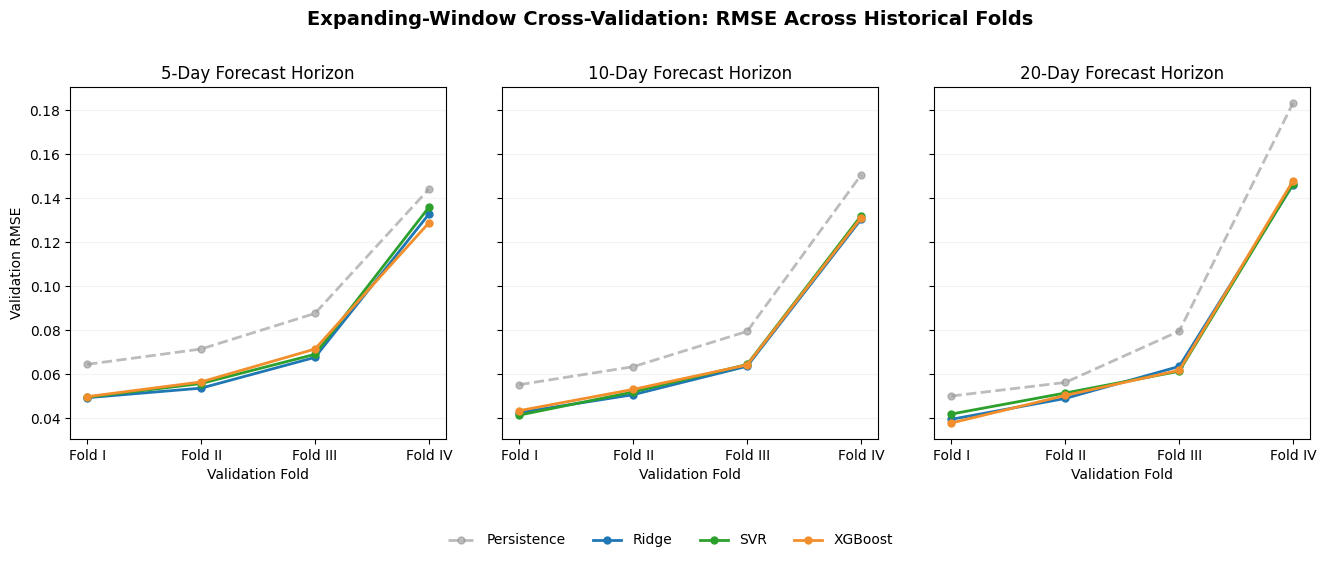

In [ ]:

# --------------------------------------------------
# 10.1.3 Cross-Validation Performance Visualization
# --------------------------------------------------

fold_order = ["Fold I", "Fold II", "Fold III", "Fold IV"]
horizons = [5, 10, 20]

MODEL_COLORS_CV = {
    "Persistence": "#999999",
    "Ridge": "#1f77b4",
    "SVR": "#2ca02c",
    "XGBoost": "#f28e2b"
}

fig_cv_performance, axes = plt.subplots(
    1, 3,
    figsize=(16, 5.5),
    sharey=True
)

for ax, horizon in zip(axes, horizons):

    subset = cv_results_df[
        cv_results_df["Horizon"] == horizon
    ]

    for model_name, color in MODEL_COLORS_CV.items():

        model_data = (
            subset[subset["Model"] == model_name]
            .set_index("Fold")
            .reindex(fold_order)
        )

        ax.plot(
            fold_order,
            model_data["RMSE"],
            marker="o",
            linewidth=2,
            markersize=5,
            color=color,
            linestyle="--" if model_name == "Persistence" else "-",
            alpha=0.65 if model_name == "Persistence" else 1.0,
            label=model_name
        )

    ax.set_title(f"{horizon}-Day Forecast Horizon")
    ax.set_xlabel("Validation Fold")
    ax.grid(axis="y", alpha=0.15)

axes[0].set_ylabel("Validation RMSE")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig_cv_performance.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=False
)

fig_cv_performance.suptitle(
    "Expanding-Window Cross-Validation: RMSE Across Historical Folds",
    fontsize=14,
    fontweight="bold"
)

fig_cv_performance.subplots_adjust(
    bottom=0.20,
    top=0.84,
    wspace=0.15
)

plt.show()


**Key Observations:**

- all supervised models outperform persistence across the four folds, forecasting errors increase substantially in Fold IV (2020–2021), and model rankings vary slightly across historical periods.

#### Section 10.1.4 - Temporal Stability Assessment

This subsection examines the consistency of forecasting performance across historical validation periods.

1. **Model Rankings:** Determine how frequently each model achieves the lowest RMSE across folds and forecasting horizons.
2. **Benchmark Improvement:** Measure the percentage reduction in RMSE relative to persistence for each fold.
3. **Performance Stability:** Evaluate variation in RMSE across historical periods.
4. **Model Reliability:** Assess whether Ridge Regression's forecasting advantage remains consistent across different market conditions.

In [ ]:

# --------------------------------------------------
# 10.1.4 Temporal Stability Assessment
# --------------------------------------------------

# Prepare cross-validation results
cv_stability_df = cv_results_df.copy()

# ----------------------------------------
# 1. Calculate Model Rankings
# ----------------------------------------

cv_stability_df["RMSE Rank"] = (
    cv_stability_df
    .groupby(["Fold", "Horizon"])["RMSE"]
    .rank(method="min", ascending=True)
    .astype(int)
)

# ----------------------------------------
# 2. Calculate Improvement Over Persistence
# ----------------------------------------

cv_benchmark_df = (
    cv_stability_df[
        cv_stability_df["Model"] == "Persistence"
    ][["Fold", "Horizon", "RMSE"]]
    .rename(columns={"RMSE": "Persistence RMSE"})
)

cv_stability_df = cv_stability_df.merge(
    cv_benchmark_df,
    on=["Fold", "Horizon"],
    how="left",
    validate="many_to_one"
)

cv_stability_df["RMSE Improvement (%)"] = (
    1 - cv_stability_df["RMSE"]
    / cv_stability_df["Persistence RMSE"]
) * 100

# ----------------------------------------
# 3. Summarize Temporal Stability
# ----------------------------------------

cv_stability_summary = (
    cv_stability_df
    .groupby("Model")
    .agg(
        Mean_Rank=("RMSE Rank", "mean"),
        First_Place_Count=("RMSE Rank", lambda x: (x == 1).sum()),
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_Improvement_Pct=("RMSE Improvement (%)", "mean"),
        Min_Improvement_Pct=("RMSE Improvement (%)", "min"),
        Max_Improvement_Pct=("RMSE Improvement (%)", "max")
    )
    .reset_index()
    .sort_values("Mean_Rank")
)

print("Temporal Stability Summary:")
display(cv_stability_summary.round(4))

# ----------------------------------------
# 4. Model Rankings by Horizon
# ----------------------------------------

cv_ranking_summary = (
    cv_stability_df
    .groupby(["Horizon", "Model"])
    .agg(
        Mean_Rank=("RMSE Rank", "mean"),
        First_Place_Count=("RMSE Rank", lambda x: (x == 1).sum()),
        Mean_Improvement_Pct=("RMSE Improvement (%)", "mean")
    )
    .reset_index()
    .sort_values(["Horizon", "Mean_Rank"])
)

print("\nModel Rankings by Forecast Horizon:")
display(cv_ranking_summary.round(4))


Temporal Stability Summary:


,Model,Mean_Rank,First_Place_Count,Mean_RMSE,Std_RMSE,Mean_Improvement_Pct,Min_Improvement_Pct,Max_Improvement_Pct
1,Ridge,1.4167,8,0.0740,0.0387,19.1985,7.9108,24.9543
2,SVR,2.2500,2,0.0750,0.0390,17.9032,5.7441,25.1033
3,XGBoost,2.3333,2,0.0746,0.0383,18.3063,10.5209,24.5203
0,Persistence,4.0000,0,0.0904,0.0439,0.0000,0.0000,0.0000



Model Rankings by Forecast Horizon:


,Horizon,Model,Mean_Rank,First_Place_Count,Mean_Improvement_Pct
1,5,Ridge,1.2500,3,19.8231
2,5,SVR,2.2500,0,18.0639
3,5,XGBoost,2.5000,1,18.2529
0,5,Persistence,4.0000,0,0.0000
5,10,Ridge,1.2500,3,19.1259
6,10,SVR,2.2500,1,18.6415
7,10,XGBoost,2.5000,0,17.4762
4,10,Persistence,4.0000,0,0.0000
9,20,Ridge,1.7500,2,18.6464
11,20,XGBoost,2.0000,1,19.1899


#### Section 10.1.5 - Key Observations

The expanding-window evaluation provides additional evidence regarding the temporal stability of the forecasting models.

1. **Overall Stability:** Ridge Regression achieved the strongest average ranking (1.42), placing first in 8 of the 12 fold–horizon combinations.

2. **Benchmark Improvement:** Ridge delivered an average RMSE improvement of 19.20% relative to persistence, followed by XGBoost (18.31%) and SVR (17.90%).

3. **Forecast Horizons:** Ridge performed most consistently at 5D and 10D, ranking first in three of four folds at each horizon. At 20D, model rankings were more evenly distributed.

4. **Market Conditions:** Forecasting errors increased substantially during Fold IV (2020–2021), demonstrating the challenges posed by periods of elevated market volatility.

5. **Model Reliability:** Although SVR and XGBoost occasionally outperformed Ridge, the linear model maintained the strongest overall ranking and consistently exceeded the persistence benchmark.

**Overall, the temporal robustness analysis supports Ridge Regression as the most reliable forecasting approach among the evaluated configurations. However, differences in performance across folds suggest that model effectiveness remains sensitive to historical market conditions.**

### Section 10.2 - Hyperparameter Sensitivity Analysis

This section examines whether forecasting performance remains stable under alternative hyperparameter settings.

| Subsection | Title | Description |
|---|---|---|
| **10.2.1** | Ridge Regression Sensitivity | Examine how different regularization strengths (alpha) affect validation RMSE. |
| **10.2.2** | SVR Sensitivity | Evaluate the influence of C, epsilon, and gamma on forecasting performance. |
| **10.2.3** | XGBoost Sensitivity | Assess the impact of tree depth, number of estimators, learning rate, and subsampling. |
| **10.2.4** | Comparative Sensitivity Visualization | Visualize how validation RMSE changes across hyperparameter configurations. |
| **10.2.5** | Key Observations | Summarize parameter sensitivity and assess the stability of model performance. |

#### Section 10.2.1 - Ridge Regression Sensitivity

In [ ]:

# --------------------------------------------------
# 10.2.1 Ridge Regularization Sensitivity
# --------------------------------------------------

# Expanded regularization search space
RIDGE_EXTENDED_GRID = [
    0.00001, 0.0001, 0.001,
    0.01, 0.1, 1, 10, 100, 1000
]

ridge_sensitivity_records = []

for horizon in HORIZONS:

    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        X_train = train_df[features]
        y_train = train_df[target]

        X_val = val_df[features]
        y_val = val_df[target]

        for alpha in RIDGE_EXTENDED_GRID:

            model = build_ridge_model(alpha)
            model.fit(X_train, y_train)

            predictions = model.predict(X_val)

            rmse = np.sqrt(
                mean_squared_error(y_val, predictions)
            )

            ridge_sensitivity_records.append({
                "Horizon": horizon,
                "Feature Set": feature_name,
                "Alpha": alpha,
                "Validation RMSE": rmse
            })

# Full sensitivity results
ridge_sensitivity_df = pd.DataFrame(
    ridge_sensitivity_records
)

# ----------------------------------------
# Identify Best Alpha per Configuration
# ----------------------------------------

ridge_sensitivity_best = (
    ridge_sensitivity_df
    .sort_values("Validation RMSE")
    .groupby(
        ["Horizon", "Feature Set"],
        as_index=False
    )
    .first()
    .sort_values(["Horizon", "Feature Set"])
    .reset_index(drop=True)
)

# ----------------------------------------
# Retrieve Original Ridge Results
# ----------------------------------------

original_ridge_rmse = (
    ridge_tuning_df
    .sort_values("Validation RMSE")
    .groupby(
        ["Horizon", "Feature Set"],
        as_index=False
    )
    .first()
    [
        ["Horizon", "Feature Set", "Validation RMSE"]
    ]
    .rename(columns={
        "Validation RMSE": "Original RMSE"
    })
)

# Merge original RMSE into sensitivity results
ridge_sensitivity_best = ridge_sensitivity_best.merge(
    original_ridge_rmse,
    on=["Horizon", "Feature Set"],
    how="left",
    validate="one_to_one"
)

# ----------------------------------------
# Calculate RMSE Change
# ----------------------------------------

ridge_sensitivity_best["RMSE Change"] = (
    ridge_sensitivity_best["Validation RMSE"]
    - ridge_sensitivity_best["Original RMSE"]
)

# Rename updated RMSE column
ridge_sensitivity_best = ridge_sensitivity_best.rename(
    columns={
        "Validation RMSE": "Updated RMSE"
    }
)

# ----------------------------------------
# Display Comparison
# ----------------------------------------

display(
    ridge_sensitivity_best[
        [
            "Horizon",
            "Feature Set",
            "Alpha",
            "Original RMSE",
            "Updated RMSE",
            "RMSE Change"
        ]
    ].round(6)
)

,Horizon,Feature Set,Alpha,Original RMSE,Updated RMSE,RMSE Change
0,5,Market + HMM,0.0000,0.1134,0.1134,-0.0000
1,5,Market-only,10.0000,0.1139,0.1139,0.0000
2,10,Market + HMM,0.0000,0.1113,0.1113,-0.0000
3,10,Market-only,0.0000,0.1114,0.1114,-0.0000
4,20,Market + HMM,0.0000,0.1249,0.1249,-0.0000
5,20,Market-only,0.0000,0.1245,0.1245,-0.0000


**Key Observations:**

- **Regularization Strength:** Five of six configurations selected an alpha below the original minimum of 0.01.
- **Market-only 5D:** The 5-day Market-only model retained alpha = 10, suggesting that moderate regularization remains beneficial for this specification.
- **Validation Performance:** RMSE values remained nearly unchanged from the original Ridge results, indicating limited sensitivity to smaller alpha values.
- **Overall Stability:** Ridge Regression's performance appears relatively stable across the expanded regularization range.

**Conclusion:** Extending the alpha search did not produce meaningful improvements in forecasting accuracy.

#### Section 10.2.2 - SVR Sensitivity

In [ ]:
# --------------------------------------------------
# Compare Original vs. Sensitivity Results
# --------------------------------------------------

svr_sensitivity_best = (
    svr_sensitivity_df
    .sort_values("Validation RMSE")
    .groupby(["Horizon", "Feature Set"], as_index=False)
    .first()
    .sort_values(["Horizon", "Feature Set"])
)

# Retrieve original SVR validation RMSE
original_svr_rmse = (
    svr_best_df[
        ["Horizon", "Feature Set", "Validation RMSE"]
    ]
    .rename(columns={
        "Validation RMSE": "Original RMSE"
    })
)

# Merge original results
svr_sensitivity_best = svr_sensitivity_best.merge(
    original_svr_rmse,
    on=["Horizon", "Feature Set"],
    how="left",
    validate="one_to_one"
)

# Calculate change relative to original results
svr_sensitivity_best["RMSE Change"] = (
    svr_sensitivity_best["Validation RMSE"]
    - svr_sensitivity_best["Original RMSE"]
)

# Display comparison
display(
    svr_sensitivity_best[
        [
            "Horizon",
            "Feature Set",
            "C",
            "Epsilon",
            "Gamma",
            "Original RMSE",
            "Validation RMSE",
            "RMSE Change"
        ]
    ].round(6)
)

,Horizon,Feature Set,C,Epsilon,Gamma,Original RMSE,Validation RMSE,RMSE Change
0,5,Market + HMM,1.0000,0.0100,0.0010,0.1163,0.1138,-0.0026
1,5,Market-only,1.0000,0.0500,0.0030,0.1159,0.1129,-0.0030
2,10,Market + HMM,1.0000,0.0100,0.0010,0.1117,0.1116,-0.0001
3,10,Market-only,1.0000,0.0100,0.0030,0.1117,0.1113,-0.0004
4,20,Market + HMM,0.1000,0.0500,0.0100,0.1239,0.1239,0.0000
5,20,Market-only,0.1000,0.0500,0.0100,0.1239,0.1239,0.0000


**Key Observations:**
- **Gamma Sensitivity:** Four of six configurations selected gamma values below the original optimum of 0.01, indicating that weaker kernel influence can improve forecasting accuracy.

- **5-Day Improvement:** The largest improvements occurred at 5D, with RMSE decreasing by 0.0026 for Market + HMM and 0.0030 for Market-only SVR.

- **10-Day Performance:** Smaller improvements were observed at 10D, with RMSE reductions of 0.0001 and 0.0004 for Market + HMM and Market-only, respectively.

- **20-Day Stability:** Both 20D configurations retained gamma = 0.01, with no improvement in validation RMSE.

- **HMM Contribution:** Market-only SVR continued to achieve slightly lower validation RMSE than the HMM-enhanced specification across all three horizons.

**Conclusion:** SVR is sensitive to gamma selection, particularly at shorter forecasting horizons. Expanding the search improved validation accuracy without changing the overall finding that HMM probabilities provide limited additional predictive value.


#### Section 10.2.3 - XGBoost Sensitivity

In [ ]:

# --------------------------------------------------
# 10.2.3 XGBoost Hyperparameter Sensitivity
# --------------------------------------------------

XGB_DEPTH_EXTENDED = [1, 2, 3, 4, 6]
XGB_LR_EXTENDED = [0.01, 0.03, 0.05, 0.10]

xgb_sensitivity_records = []

for horizon in HORIZONS:

    target = f"Forward_RV_{horizon}D"

    for feature_name, features in feature_sets.items():

        original_params = xgb_models[
            (horizon, feature_name)
        ]["Parameters"]

        for max_depth, learning_rate in product(
            XGB_DEPTH_EXTENDED,
            XGB_LR_EXTENDED
        ):

            model = build_xgb_model(
                n_estimators=original_params["n_estimators"],
                max_depth=max_depth,
                learning_rate=learning_rate,
                subsample=original_params["subsample"]
            )

            model.fit(
                train_df[features],
                train_df[target]
            )

            predictions = model.predict(val_df[features])

            rmse = np.sqrt(
                mean_squared_error(
                    val_df[target],
                    predictions
                )
            )

            xgb_sensitivity_records.append({
                "Horizon": horizon,
                "Feature Set": feature_name,
                "n_estimators": original_params["n_estimators"],
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "subsample": original_params["subsample"],
                "Validation RMSE": rmse
            })

# Full sensitivity results
xgb_sensitivity_df = pd.DataFrame(
    xgb_sensitivity_records
)

# Identify best configuration
xgb_sensitivity_best = (
    xgb_sensitivity_df
    .sort_values("Validation RMSE")
    .groupby(
        ["Horizon", "Feature Set"],
        as_index=False
    )
    .first()
    .sort_values(["Horizon", "Feature Set"])
)

# Retrieve original validation RMSE
original_xgb_rmse = (
    xgb_best_df[
        ["Horizon", "Feature Set", "Validation RMSE"]
    ]
    .rename(columns={
        "Validation RMSE": "Original RMSE"
    })
)

# Merge original results
xgb_sensitivity_best = xgb_sensitivity_best.merge(
    original_xgb_rmse,
    on=["Horizon", "Feature Set"],
    how="left",
    validate="one_to_one"
)

# Calculate improvement
xgb_sensitivity_best["RMSE Change"] = (
    xgb_sensitivity_best["Validation RMSE"]
    - xgb_sensitivity_best["Original RMSE"]
)

display(
    xgb_sensitivity_best[
        [
            "Horizon",
            "Feature Set",
            "n_estimators",
            "max_depth",
            "learning_rate",
            "subsample",
            "Original RMSE",
            "Validation RMSE",
            "RMSE Change"
        ]
    ].round(6)
)

,Horizon,Feature Set,n_estimators,max_depth,learning_rate,subsample,Original RMSE,Validation RMSE,RMSE Change
0,5,Market + HMM,300,1,0.1000,0.8000,0.1107,0.1086,-0.0021
1,5,Market-only,300,1,0.1000,0.8000,0.1104,0.1082,-0.0023
2,10,Market + HMM,300,1,0.1000,0.8000,0.1096,0.1075,-0.0021
3,10,Market-only,100,2,0.1000,1.0000,0.1093,0.1093,0.0000
4,20,Market + HMM,100,1,0.0500,1.0000,0.1242,0.1240,-0.0002
5,20,Market-only,100,1,0.0500,1.0000,0.1241,0.1240,-0.0001


**Key Observations:**

- **Tree Complexity:** Five of six configurations selected `max_depth = 1`, suggesting that simpler decision trees generally performed better.

- **5-Day Improvement:** Validation RMSE decreased by 0.0021 for Market + HMM and 0.0023 for Market-only XGBoost.

- **10-Day Performance:** Market + HMM improved by 0.0021, while Market-only retained its original configuration with no change in RMSE.

- **20-Day Stability:** Both specifications selected shallower trees and a learning rate of 0.05, producing only marginal RMSE improvements (0.0001–0.0002).

- **HMM Contribution:** Market-only XGBoost continued to achieve equal or lower validation RMSE across all forecasting horizons.

**Conclusion:** XGBoost performance is sensitive to tree complexity, with shallower trees generally improving validation accuracy. However, the expanded search did not establish a consistent benefit from HMM regime probabilities.

#### Section 10.2.4 - Comparative Sensitivity Visualization

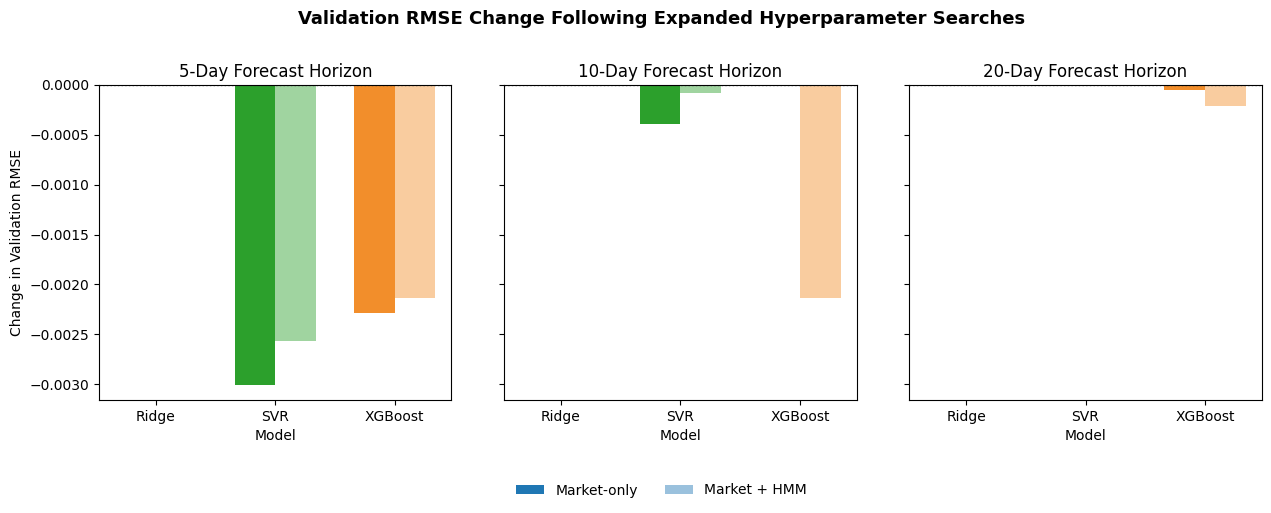

In [ ]:

# --------------------------------------------------
# 10.2.4 Comparative Hyperparameter Sensitivity
# --------------------------------------------------

# Consolidate sensitivity results
sensitivity_comparison_df = pd.concat(
    [
        ridge_sensitivity_best.assign(Model="Ridge"),
        svr_sensitivity_best.assign(Model="SVR"),
        xgb_sensitivity_best.assign(Model="XGBoost")
    ],
    ignore_index=True
)

# Standardize RMSE change column
sensitivity_comparison_df = sensitivity_comparison_df[
    ["Model", "Horizon", "Feature Set", "RMSE Change"]
].copy()

# Model color families
MODEL_COLORS = {
    "Ridge": "#1f77b4",
    "SVR": "#2ca02c",
    "XGBoost": "#f28e2b"
}

# Create comparison figure
fig_parameter_sensitivity, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, horizon in zip(axes, HORIZONS):

    subset = sensitivity_comparison_df[
        sensitivity_comparison_df["Horizon"] == horizon
    ]

    x = np.arange(3)
    width = 0.34

    for j, feature_name in enumerate(
        ["Market-only", "Market + HMM"]
    ):

        values = [
            subset.loc[
                (subset["Model"] == model) &
                (subset["Feature Set"] == feature_name),
                "RMSE Change"
            ].iloc[0]
            for model in ["Ridge", "SVR", "XGBoost"]
        ]

        ax.bar(
            x + (j - 0.5) * width,
            values,
            width,
            color=[
                MODEL_COLORS[model]
                for model in ["Ridge", "SVR", "XGBoost"]
            ],
            alpha=1.0 if j == 0 else 0.45,
            label=feature_name
        )

    ax.axhline(
        0,
        color="#555555",
        linestyle=":",
        linewidth=1
    )

    ax.set_xticks(x)
    ax.set_xticklabels(["Ridge", "SVR", "XGBoost"])
    ax.set_title(f"{horizon}-Day Forecast Horizon")
    ax.set_xlabel("Model")

axes[0].set_ylabel("Change in Validation RMSE")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig_parameter_sensitivity.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False
)

fig_parameter_sensitivity.suptitle(
    "Validation RMSE Change Following Expanded Hyperparameter Searches",
    fontsize=13,
    fontweight="bold"
)

fig_parameter_sensitivity.subplots_adjust(
    bottom=0.20,
    top=0.83,
    wspace=0.15
)

plt.show()

#### Section 10.2.5 - Key Observations

1. **Overall Sensitivity:** Expanded hyperparameter searches improved or maintained validation RMSE across all model configurations.

2. **Ridge Regression:** Extending the regularization range produced negligible improvements, indicating relatively stable forecasting performance across alpha values.

3. **SVR:** The largest improvements occurred at the 5D horizon, with RMSE reductions of approximately 0.0030 for Market-only and 0.0026 for Market + HMM.

4. **XGBoost:** Shallower decision trees improved forecasting accuracy, particularly at 5D and 10D, with RMSE reductions reaching approximately 0.0023.

5. **Forecast Horizon:** Hyperparameter sensitivity was generally greater at shorter horizons, while the 20D configurations exhibited limited changes.

6. **HMM Contribution:** Despite improvements from expanded tuning, incorporating HMM probabilities did not consistently improve validation performance.

**Overall, Ridge Regression demonstrated greater stability under alternative hyperparameter settings, while SVR and XGBoost benefited from additional tuning. These findings reinforce the importance of appropriate parameter selection when comparing model performance.**

### Section 10.3 - Feature Ablation Analysis

Feature ablation is conducted to assess the contribution of different predictor groups to forward realized volatility forecasting.

1. **Predictor Groups:** Examine VIX indicators, realized volatility, return skewness, return kurtosis, and HMM regime probabilities.
2. **Ablation Method:** Remove one predictor group at a time and retrain Ridge Regression, SVR, and XGBoost.
3. **Evaluation:** Compare validation RMSE against the corresponding full-feature model.
4. **Interpretation:** Identify which predictor groups are most important and whether HMM probabilities provide additional forecasting value.

Previously selected hyperparameters are held fixed to isolate the effects of removing predictors.

In [ ]:

# --------------------------------------------------
# 10.3 Feature Ablation Analysis
# --------------------------------------------------

# Define predictor groups
feature_groups = {
    "VIX": [
        "VIX_Level", "VIX_Change"
    ],
    "Realized Volatility": [
        "Realized_Vol_5D",
        "Realized_Vol_10D",
        "Realized_Vol_20D"
    ],
    "Skewness": [
        "Return_Skew_5D",
        "Return_Skew_10D",
        "Return_Skew_20D"
    ],
    "Kurtosis": [
        "Return_Kurt_5D",
        "Return_Kurt_10D",
        "Return_Kurt_20D"
    ],
    "HMM Probabilities": regime_predictors
}

# Use all 14 predictors as the reference specification
full_features = feature_sets["Market + HMM"]

ablation_records = []

for horizon in HORIZONS:

    target = f"Forward_RV_{horizon}D"

    for model_name in ["Ridge", "SVR", "XGBoost"]:

        # Retain previously selected hyperparameters
        if model_name == "Ridge":
            alpha = ridge_models[
                (horizon, "Market + HMM")
            ]["Alpha"]

            build_model = lambda: build_ridge_model(alpha)

        elif model_name == "SVR":
            params = svr_models[
                (horizon, "Market + HMM")
            ]["Parameters"]

            build_model = lambda: build_svr_model(**params)

        else:
            params = xgb_models[
                (horizon, "Market + HMM")
            ]["Parameters"]

            build_model = lambda: build_xgb_model(**params)

        # Full-feature reference model
        full_model = build_model()

        full_model.fit(
            train_df[full_features],
            train_df[target]
        )

        full_predictions = full_model.predict(
            val_df[full_features]
        )

        baseline_rmse = np.sqrt(
            mean_squared_error(
                val_df[target],
                full_predictions
            )
        )

        # Remove one predictor group at a time
        for group_name, excluded_features in feature_groups.items():

            selected_features = [
                feature for feature in full_features
                if feature not in excluded_features
            ]

            model = build_model()

            model.fit(
                train_df[selected_features],
                train_df[target]
            )

            predictions = model.predict(
                val_df[selected_features]
            )

            ablated_rmse = np.sqrt(
                mean_squared_error(
                    val_df[target],
                    predictions
                )
            )

            ablation_records.append({
                "Model": model_name,
                "Horizon": horizon,
                "Excluded Group": group_name,
                "Full RMSE": baseline_rmse,
                "Ablated RMSE": ablated_rmse,
                "RMSE Change": ablated_rmse - baseline_rmse
            })

# Consolidated results
ablation_results_df = pd.DataFrame(ablation_records)

# Calculate percentage change
ablation_results_df["RMSE Change (%)"] = (
    ablation_results_df["RMSE Change"]
    / ablation_results_df["Full RMSE"]
) * 100

# Display results
display(
    ablation_results_df
    .sort_values(["Horizon", "Model", "Excluded Group"])
    .round(6)
)

# Summarize average impact by predictor group
ablation_summary_df = (
    ablation_results_df
    .groupby("Excluded Group", as_index=False)
    .agg(
        Mean_RMSE_Change_Pct=("RMSE Change (%)", "mean"),
        Min_RMSE_Change_Pct=("RMSE Change (%)", "min"),
        Max_RMSE_Change_Pct=("RMSE Change (%)", "max")
    )
    .sort_values(
        "Mean_RMSE_Change_Pct",
        ascending=False
    )
)

print("Average Predictor Group Impact:")
display(ablation_summary_df.round(4))


,Model,Horizon,Excluded Group,Full RMSE,Ablated RMSE,RMSE Change,RMSE Change (%)
4,Ridge,5,HMM Probabilities,0.1134,0.1139,0.0005,0.4306
3,Ridge,5,Kurtosis,0.1134,0.1134,0.0000,0.0400
1,Ridge,5,Realized Volatility,0.1134,0.1187,0.0054,4.7212
2,Ridge,5,Skewness,0.1134,0.1132,-0.0002,-0.1460
0,Ridge,5,VIX,0.1134,0.1220,0.0086,7.5960
9,SVR,5,HMM Probabilities,0.1163,0.1162,-0.0002,-0.1304
8,SVR,5,Kurtosis,0.1163,0.1153,-0.0010,-0.8666
6,SVR,5,Realized Volatility,0.1163,0.1176,0.0012,1.0708
7,SVR,5,Skewness,0.1163,0.1149,-0.0015,-1.2556
5,SVR,5,VIX,0.1163,0.1226,0.0062,5.3708


Average Predictor Group Impact:


,Excluded Group,Mean_RMSE_Change_Pct,Min_RMSE_Change_Pct,Max_RMSE_Change_Pct
4,VIX,5.1196,1.8684,7.7036
2,Realized Volatility,2.9308,0.0360,5.7253
0,HMM Probabilities,-0.0313,-0.2998,0.4306
1,Kurtosis,-0.1334,-0.9795,0.7428
3,Skewness,-0.1960,-1.2556,0.9360


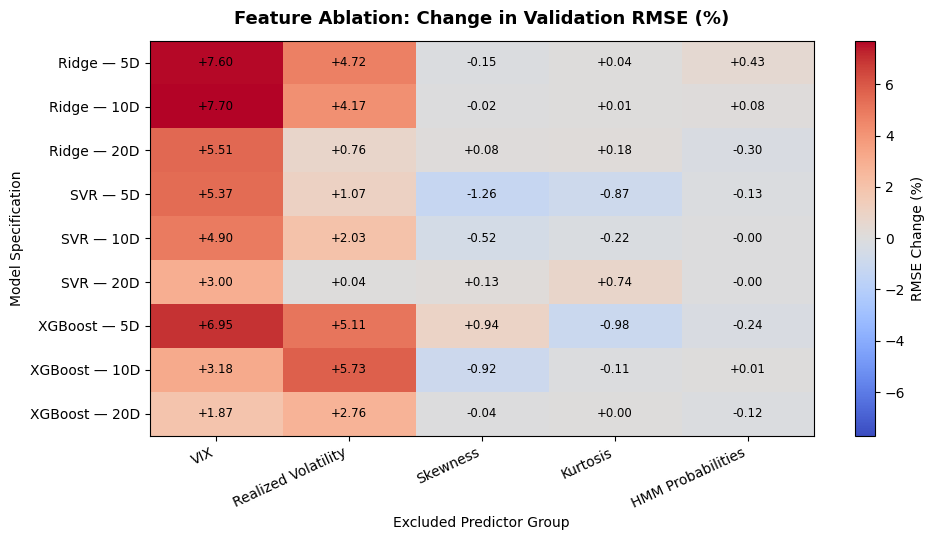

In [ ]:
# --------------------------------------------------
# 10.3 Feature Ablation Heatmap
# --------------------------------------------------

from matplotlib.colors import TwoSlopeNorm

# Create row labels
ablation_heatmap_df = ablation_results_df.copy()

ablation_heatmap_df["Specification"] = (
    ablation_heatmap_df["Model"]
    + " — "
    + ablation_heatmap_df["Horizon"].astype(str)
    + "D"
)

# Pivot for heatmap
heatmap_df = (
    ablation_heatmap_df
    .pivot(
        index="Specification",
        columns="Excluded Group",
        values="RMSE Change (%)"
    )
    .reindex(
        index=[
            "Ridge — 5D", "Ridge — 10D", "Ridge — 20D",
            "SVR — 5D", "SVR — 10D", "SVR — 20D",
            "XGBoost — 5D", "XGBoost — 10D", "XGBoost — 20D"
        ],
        columns=[
            "VIX",
            "Realized Volatility",
            "Skewness",
            "Kurtosis",
            "HMM Probabilities"
        ]
    )
)

# Symmetric color scale around zero
limit = max(
    abs(heatmap_df.min().min()),
    abs(heatmap_df.max().max())
)

norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

# Create figure
fig_feature_ablation, ax = plt.subplots(figsize=(10, 5.5))

im = ax.imshow(
    heatmap_df.values,
    cmap="coolwarm",
    norm=norm,
    aspect="auto"
)

# Axis ticks and labels
ax.set_xticks(np.arange(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns, rotation=25, ha="right")

ax.set_yticks(np.arange(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

ax.set_xlabel("Excluded Predictor Group")
ax.set_ylabel("Model Specification")

ax.set_title(
    "Feature Ablation: Change in Validation RMSE (%)",
    fontsize=13,
    fontweight="bold",
    pad=12
)

# Annotate cells
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        value = heatmap_df.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=8.5,
            color="black"
        )

# Colorbar
cbar = fig_feature_ablation.colorbar(im, ax=ax)
cbar.set_label("RMSE Change (%)")

fig_feature_ablation.tight_layout()
plt.show()

**Key Observations:**

- **VIX Indicators:** Removing VIX level and change produced the largest deterioration in validation RMSE (+5.12% on average), indicating their importance for volatility forecasting.

- **Realized Volatility:** Excluding trailing realized volatility increased RMSE by 2.93% on average, confirming its contribution to forecasting accuracy.

- **HMM Probabilities:** Removing filtered regime probabilities slightly improved RMSE (−0.03%), suggesting limited incremental predictive value beyond conventional market indicators.

- **Return Statistics:** Removing skewness and kurtosis produced small average improvements of 0.20% and 0.13%, respectively, suggesting that these features contributed little additional information under the evaluated configurations.

- **Predictor Importance:** VIX indicators and trailing realized volatility emerged as the most influential predictor groups across the evaluated models and forecasting horizons.

**Overall, feature ablation reinforces the finding that conventional volatility indicators drive forecasting performance, while HMM regime probabilities offer limited incremental predictive value.**

**Figure Note:** Cells report the percentage change in validation RMSE after removing each predictor group. Positive values indicate that excluding the group worsened forecasting accuracy, while negative values indicate that performance improved after removal.

### Section 10.4 - Market Stress Robustness

This analysis evaluates forecasting performance during two periods of elevated market volatility:

1. **COVID-19 Shock (2020):** Examine forecasting errors during the pandemic-related market disruption using Fold IV predictions.
2. **Tariff Shock (2025):** Evaluate forecasting errors during the March–May 2025 volatility episode using held-out testing predictions.
3. **Model Comparison:** Compare Ridge Regression, SVR, and XGBoost using 5-day forecasting RMSE and MAE.
4. **Robustness Assessment:** Determine whether model rankings and forecasting accuracy change during market stress.

Each event is compared with other observations from its corresponding evaluation period. The analysis uses Market-only specifications to maintain consistency with the temporal robustness assessment.

In [ ]:

# --------------------------------------------------
# 10.4 Market Stress Robustness
# --------------------------------------------------

STRESS_PERIODS = {
    "COVID-19 (2020)": {
        "Start": "2020-02-20",
        "End": "2020-06-30",
        "Source": "Fold IV"
    },
    "Tariff Shock (2025)": {
        "Start": "2025-03-15",
        "End": "2025-05-15",
        "Source": "Testing"
    }
}

stress_predictions = {
    "Ridge": ridge_predictions,
    "SVR": svr_predictions,
    "XGBoost": xgb_predictions
}

stress_records = []

for event_name, event_info in STRESS_PERIODS.items():

    start = pd.Timestamp(event_info["Start"])
    end = pd.Timestamp(event_info["End"])
    source = event_info["Source"]

    for model_name, predictions_dict in stress_predictions.items():

        # Retrieve previously generated predictions
        if source == "Fold IV":
            result = cv_predictions[
                ("Fold IV", 5, model_name)
            ]
        else:
            result = predictions_dict[
                (5, "Market-only", "Testing")
            ]

        df = pd.DataFrame({
            "Date": pd.to_datetime(result["Date"]),
            "Actual": result["Actual"],
            "Predicted": result["Predicted"]
        })

        df["Period"] = np.where(
            df["Date"].between(start, end),
            "Stress Window",
            "Other Dates"
        )

        for period_name, group in df.groupby("Period"):

            rmse = np.sqrt(
                mean_squared_error(
                    group["Actual"],
                    group["Predicted"]
                )
            )

            mae = mean_absolute_error(
                group["Actual"],
                group["Predicted"]
            )

            stress_records.append({
                "Event": event_name,
                "Model": model_name,
                "Period": period_name,
                "Observations": len(group),
                "RMSE": rmse,
                "MAE": mae
            })

stress_results_df = pd.DataFrame(stress_records)

# Compare stress-window and other-period performance
stress_comparison_df = (
    stress_results_df
    .pivot(
        index=["Event", "Model"],
        columns="Period",
        values="RMSE"
    )
    .reset_index()
)

stress_comparison_df["RMSE Increase (%)"] = (
    stress_comparison_df["Stress Window"]
    / stress_comparison_df["Other Dates"] - 1
) * 100

print("Market Stress Performance:")
display(stress_results_df.round(4))

print("\nStress vs. Other Dates:")
display(stress_comparison_df.round(4))

Market Stress Performance:


,Event,Model,Period,Observations,RMSE,MAE
0,COVID-19 (2020),Ridge,Other Dates,413,0.0756,0.0633
1,COVID-19 (2020),Ridge,Stress Window,92,0.2667,0.1737
2,COVID-19 (2020),SVR,Other Dates,413,0.0734,0.0617
3,COVID-19 (2020),SVR,Stress Window,92,0.2778,0.1869
4,COVID-19 (2020),XGBoost,Other Dates,413,0.0746,0.0631
5,COVID-19 (2020),XGBoost,Stress Window,92,0.2572,0.1739
6,Tariff Shock (2025),Ridge,Other Dates,940,0.0599,0.0451
7,Tariff Shock (2025),Ridge,Stress Window,43,0.2149,0.1387
8,Tariff Shock (2025),SVR,Other Dates,940,0.0600,0.0449
9,Tariff Shock (2025),SVR,Stress Window,43,0.2186,0.1430



Stress vs. Other Dates:


Period,Event,Model,Other Dates,Stress Window,RMSE Increase (%)
0,COVID-19 (2020),Ridge,0.0756,0.2667,252.8406
1,COVID-19 (2020),SVR,0.0734,0.2778,278.2388
2,COVID-19 (2020),XGBoost,0.0746,0.2572,244.9206
3,Tariff Shock (2025),Ridge,0.0599,0.2149,258.9766
4,Tariff Shock (2025),SVR,0.0600,0.2186,264.2978
5,Tariff Shock (2025),XGBoost,0.0599,0.2285,281.1633


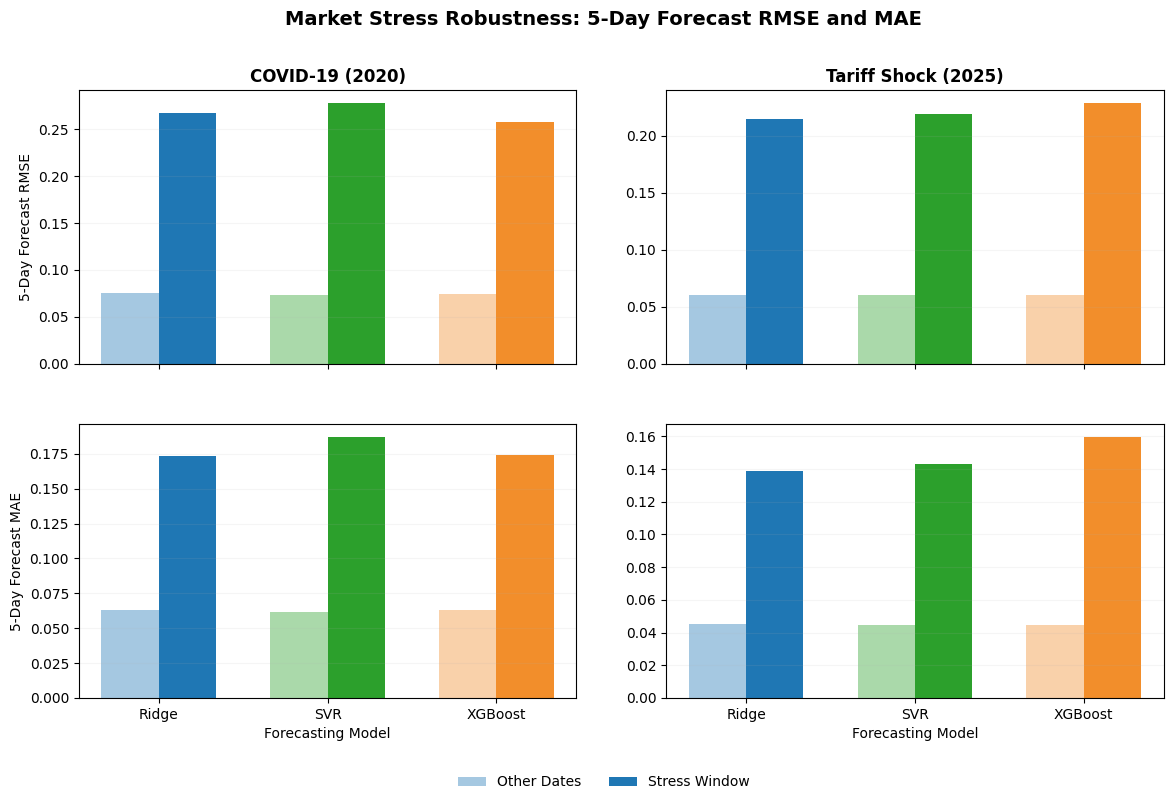

In [ ]:
# --------------------------------------------------
# 10.4 Market Stress Robustness Visualization
# RMSE + MAE
# --------------------------------------------------

MODEL_COLORS = {
    "Ridge": "#1f77b4",
    "SVR": "#2ca02c",
    "XGBoost": "#f28e2b"
}

model_order = ["Ridge", "SVR", "XGBoost"]
event_order = ["COVID-19 (2020)", "Tariff Shock (2025)"]
metric_order = ["RMSE", "MAE"]

# Figure variable for export
fig_stress_robustness, axes = plt.subplots(
    2, 2,
    figsize=(14, 8),
    sharex=True
)

for col, event_name in enumerate(event_order):

    subset = stress_results_df[
        stress_results_df["Event"] == event_name
    ]

    for row, metric in enumerate(metric_order):

        ax = axes[row, col]
        x = np.arange(len(model_order))
        width = 0.34

        for i, model in enumerate(model_order):

            model_data = subset[
                subset["Model"] == model
            ]

            other_value = model_data.loc[
                model_data["Period"] == "Other Dates",
                metric
            ].iloc[0]

            stress_value = model_data.loc[
                model_data["Period"] == "Stress Window",
                metric
            ].iloc[0]

            # Other dates
            ax.bar(
                x[i] - width / 2,
                other_value,
                width,
                color=MODEL_COLORS[model],
                alpha=0.4,
                label="Other Dates" if (row == 0 and i == 0) else ""
            )

            # Stress window
            ax.bar(
                x[i] + width / 2,
                stress_value,
                width,
                color=MODEL_COLORS[model],
                alpha=1.0,
                label="Stress Window" if (row == 0 and i == 0) else ""
            )

        ax.set_xticks(x)
        ax.set_xticklabels(model_order)
        ax.grid(axis="y", alpha=0.12)

        if row == 0:
            ax.set_title(event_name, fontsize=12, fontweight="bold")

        if col == 0:
            ax.set_ylabel(f"5-Day Forecast {metric}")

        if row == 1:
            ax.set_xlabel("Forecasting Model")

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig_stress_robustness.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=2,
    frameon=False
)

fig_stress_robustness.suptitle(
    "Market Stress Robustness: 5-Day Forecast RMSE and MAE",
    fontsize=14,
    fontweight="bold"
)

fig_stress_robustness.subplots_adjust(
    bottom=0.12,
    top=0.88,
    wspace=0.18,
    hspace=0.22
)

plt.show()

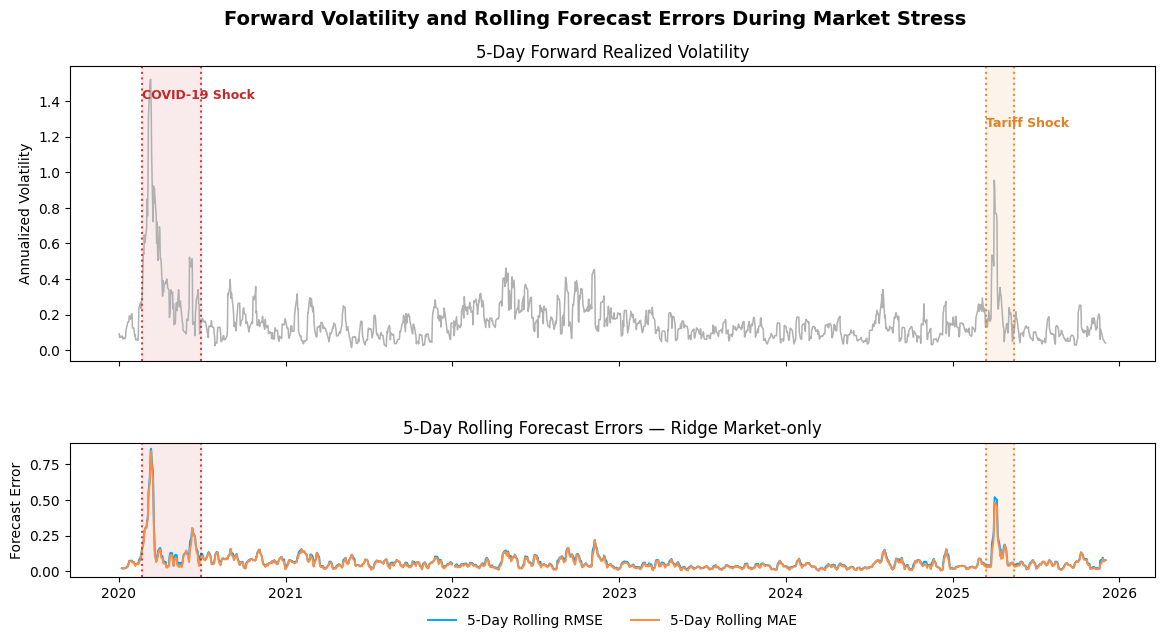

In [ ]:

# --------------------------------------------------
# 10.4 Forward Volatility and Rolling Forecast Errors
# Highlight COVID-19 and Tariff Shock
# --------------------------------------------------

ROLLING_WINDOW = 5

# Define stress periods
COVID_START = pd.Timestamp("2020-02-20")
COVID_END = pd.Timestamp("2020-06-30")

TARIFF_START = pd.Timestamp("2025-03-15")
TARIFF_END = pd.Timestamp("2025-05-15")

# ----------------------------------------
# Retrieve Ridge Market-only predictions
# ----------------------------------------

covid_result = cv_predictions[
    ("Fold IV", 5, "Ridge")
]

tariff_result = ridge_predictions[
    (5, "Market-only", "Testing")
]

# Combine prediction datasets
diagnostic_df = pd.concat(
    [
        pd.DataFrame({
            "Date": pd.to_datetime(covid_result["Date"]),
            "Actual": covid_result["Actual"],
            "Predicted": covid_result["Predicted"],
            "Source": "Fold IV"
        }),
        pd.DataFrame({
            "Date": pd.to_datetime(tariff_result["Date"]),
            "Actual": tariff_result["Actual"],
            "Predicted": tariff_result["Predicted"],
            "Source": "Testing"
        })
    ],
    ignore_index=True
).sort_values("Date").reset_index(drop=True)

# ----------------------------------------
# Calculate forecast errors
# ----------------------------------------

diagnostic_df["Error"] = (
    diagnostic_df["Actual"] - diagnostic_df["Predicted"]
)

diagnostic_df["Abs_Error"] = diagnostic_df["Error"].abs()
diagnostic_df["Squared_Error"] = diagnostic_df["Error"] ** 2

# Calculate rolling metrics separately for each
# prediction source to avoid crossing the data gap
diagnostic_df["Rolling_MAE_5D"] = (
    diagnostic_df.groupby("Source")["Abs_Error"]
    .transform(
        lambda x: x.rolling(
            window=ROLLING_WINDOW,
            min_periods=ROLLING_WINDOW
        ).mean()
    )
)

diagnostic_df["Rolling_RMSE_5D"] = np.sqrt(
    diagnostic_df.groupby("Source")["Squared_Error"]
    .transform(
        lambda x: x.rolling(
            window=ROLLING_WINDOW,
            min_periods=ROLLING_WINDOW
        ).mean()
    )
)

# ----------------------------------------
# Define plotting colors
# ----------------------------------------

COLOR_VOLATILITY = "#B0B0B0"
COLOR_RMSE = "#00A6FF"
COLOR_MAE = "#FF8C42"

COLOR_COVID = "#C62828"
COLOR_TARIFF = "#E67E22"

# ----------------------------------------
# Initialize figure
# ----------------------------------------

fig_forecast_error_diagnostics, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1]}
)

# ----------------------------------------
# Panel A: Forward Realized Volatility
# ----------------------------------------

for source, group in diagnostic_df.groupby("Source"):

    axes[0].plot(
        group["Date"],
        group["Actual"],
        color=COLOR_VOLATILITY,
        linewidth=1.1,
        label="Actual 5-Day Forward RV"
        if source == "Fold IV" else None
    )

axes[0].set_title("5-Day Forward Realized Volatility")
axes[0].set_ylabel("Annualized Volatility")

# ----------------------------------------
# Panel B: Rolling RMSE and MAE
# ----------------------------------------

for source, group in diagnostic_df.groupby("Source"):

    axes[1].plot(
        group["Date"],
        group["Rolling_RMSE_5D"],
        color=COLOR_RMSE,
        linewidth=1.4,
        label="5-Day Rolling RMSE"
        if source == "Fold IV" else None
    )

    axes[1].plot(
        group["Date"],
        group["Rolling_MAE_5D"],
        color=COLOR_MAE,
        linewidth=1.4,
        label="5-Day Rolling MAE"
        if source == "Fold IV" else None
    )

axes[1].set_title(
    "5-Day Rolling Forecast Errors — Ridge Market-only"
)
axes[1].set_ylabel("Forecast Error")

# Remove x-axis caption but retain dates
axes[1].set_xlabel("")

# ----------------------------------------
# Highlight Stress Periods
# ----------------------------------------

stress_periods = [
    (COVID_START, COVID_END, COLOR_COVID),
    (TARIFF_START, TARIFF_END, COLOR_TARIFF)
]

for ax in axes:

    for start, end, color in stress_periods:

        # Light background shading
        ax.axvspan(
            start,
            end,
            color=color,
            alpha=0.09,
            zorder=0
        )

        # Dotted left boundary
        ax.axvline(
            start,
            color=color,
            linestyle=":",
            linewidth=1.5,
            alpha=0.85
        )

        # Dotted right boundary
        ax.axvline(
            end,
            color=color,
            linestyle=":",
            linewidth=1.5,
            alpha=0.85
        )

    # Remove all grid lines
    ax.grid(False)

# ----------------------------------------
# Stress Event Labels
# ----------------------------------------

axes[0].text(
    COVID_START,
    axes[0].get_ylim()[1] * 0.92,
    "COVID-19 Shock",
    color=COLOR_COVID,
    fontsize=9,
    fontweight="bold",
    ha="left",
    va="top"
)

axes[0].text(
    TARIFF_START,
    axes[0].get_ylim()[1] * 0.82,
    "Tariff Shock",
    color=COLOR_TARIFF,
    fontsize=9,
    fontweight="bold",
    ha="left",
    va="top"
)

# ----------------------------------------
# Legend and Final Formatting
# ----------------------------------------

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False
)

fig_forecast_error_diagnostics.suptitle(
    "Forward Volatility and Rolling Forecast Errors During Market Stress",
    fontsize=14,
    fontweight="bold"
)

fig_forecast_error_diagnostics.subplots_adjust(
    hspace=0.38,
    bottom=0.17,
    top=0.90
)

plt.show()


### Section 10.5 - Ranked Model Forecast Diagnostics

The three supervised forecasting models are ranked by their overall 5-day testing RMSE and examined during the COVID-19 and 2025 tariff-related volatility shocks.

Each model is evaluated using the Market-only specification, with:

1. **Forward Volatility:** Actual 5-day forward realized volatility.
2. **Rolling Forecast Errors:** 5-day rolling RMSE and MAE.
3. **Market Stress:** Highlighted COVID-19 and tariff-shock periods.

The analysis examines whether forecasting-error patterns differ across models ranked by their overall testing accuracy.

5-Day Forecasting Model Ranking:


,Rank,Model,Feature Set,RMSE
0,1,Ridge,Market-only,0.0738
1,2,SVR,Market-only,0.0744
2,3,XGBoost,Market-only,0.0756


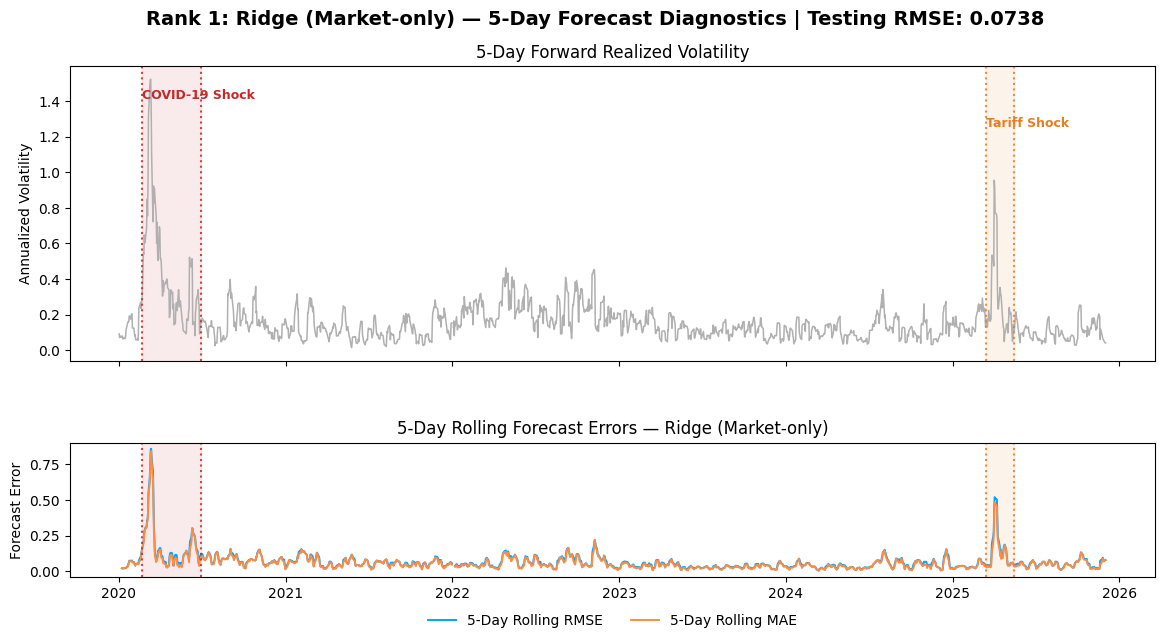

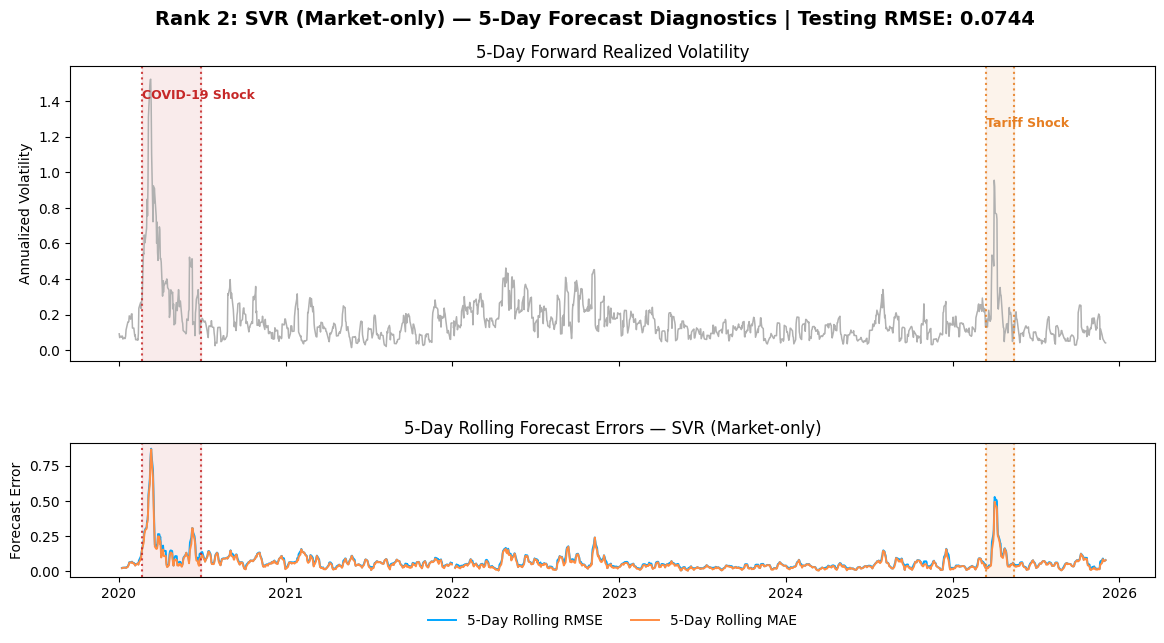

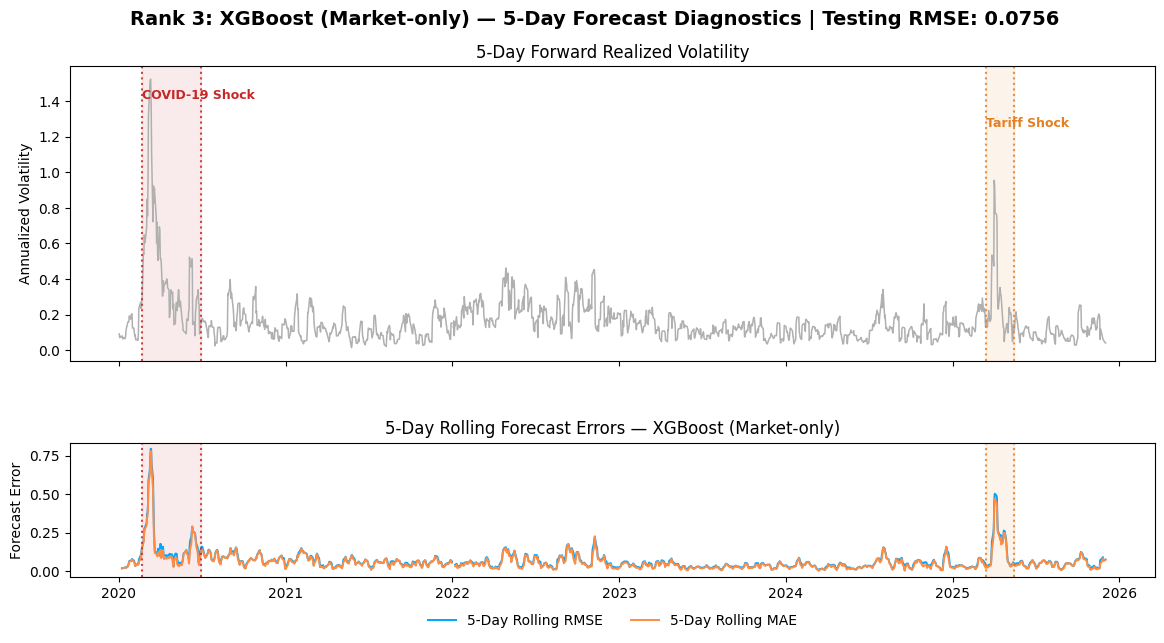

In [ ]:

# --------------------------------------------------
# 10.4 Ranked Model Forecast Diagnostics
# 5-Day Forward Volatility + 5-Day Rolling RMSE/MAE
# --------------------------------------------------

ROLLING_WINDOW = 5
FEATURE_SET = "Market-only"

# ----------------------------------------
# Rank models by 5-day testing RMSE
# ----------------------------------------

ranked_models_df = (
    test_results_df.loc[
        (test_results_df["Horizon"] == 5) &
        (test_results_df["Feature Set"] == FEATURE_SET) &
        (test_results_df["Model"].isin(["Ridge", "SVR", "XGBoost"])),
        ["Model", "Feature Set", "RMSE"]
    ]
    .sort_values("RMSE")
    .reset_index(drop=True)
)

ranked_models_df.insert(
    0, "Rank", np.arange(1, len(ranked_models_df) + 1)
)

print("5-Day Forecasting Model Ranking:")
display(ranked_models_df.round(4))

# ----------------------------------------
# Define colors and stress windows
# ----------------------------------------

COLOR_VOLATILITY = "#B0B0B0"
COLOR_RMSE = "#00A6FF"
COLOR_MAE = "#FF8C42"

COLOR_COVID = "#C62828"
COLOR_TARIFF = "#E67E22"

stress_periods = [
    (
        pd.Timestamp("2020-02-20"),
        pd.Timestamp("2020-06-30"),
        COLOR_COVID,
        "COVID-19 Shock"
    ),
    (
        pd.Timestamp("2025-03-15"),
        pd.Timestamp("2025-05-15"),
        COLOR_TARIFF,
        "Tariff Shock"
    )
]

prediction_sources = {
    "Ridge": ridge_predictions,
    "SVR": svr_predictions,
    "XGBoost": xgb_predictions
}

# Store figures for later export
fig_ranked_forecast_diagnostics = {}

# ----------------------------------------
# Generate one figure per ranked model
# ----------------------------------------

for _, row in ranked_models_df.iterrows():

    rank = int(row["Rank"])
    model_name = row["Model"]
    feature_name = row["Feature Set"]
    testing_rmse = row["RMSE"]

    # Retrieve historical cross-validation predictions
    historical_result = cv_predictions[
        ("Fold IV", 5, model_name)
    ]

    # Retrieve held-out testing predictions
    testing_result = prediction_sources[model_name][
        (5, feature_name, "Testing")
    ]

    # Combine both evaluation periods
    diagnostic_df = pd.concat(
        [
            pd.DataFrame({
                "Date": pd.to_datetime(historical_result["Date"]),
                "Actual": historical_result["Actual"],
                "Predicted": historical_result["Predicted"],
                "Source": "Fold IV"
            }),
            pd.DataFrame({
                "Date": pd.to_datetime(testing_result["Date"]),
                "Actual": testing_result["Actual"],
                "Predicted": testing_result["Predicted"],
                "Source": "Testing"
            })
        ],
        ignore_index=True
    ).sort_values("Date").reset_index(drop=True)

    # ----------------------------------------
    # Calculate forecast errors
    # ----------------------------------------

    diagnostic_df["Error"] = (
        diagnostic_df["Actual"] - diagnostic_df["Predicted"]
    )

    diagnostic_df["Abs_Error"] = (
        diagnostic_df["Error"].abs()
    )

    diagnostic_df["Squared_Error"] = (
        diagnostic_df["Error"] ** 2
    )

    # Calculate rolling metrics separately by source
    diagnostic_df["Rolling_MAE_5D"] = (
        diagnostic_df.groupby("Source")["Abs_Error"]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=ROLLING_WINDOW
            ).mean()
        )
    )

    diagnostic_df["Rolling_RMSE_5D"] = np.sqrt(
        diagnostic_df.groupby("Source")["Squared_Error"]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=ROLLING_WINDOW
            ).mean()
        )
    )

    # ----------------------------------------
    # Initialize figure
    # ----------------------------------------

    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 7),
        sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1]}
    )

    # ----------------------------------------
    # Panel A: 5-Day Forward Realized Volatility
    # ----------------------------------------

    for source, group in diagnostic_df.groupby("Source"):

        axes[0].plot(
            group["Date"],
            group["Actual"],
            color=COLOR_VOLATILITY,
            linewidth=1.1
        )

    axes[0].set_title(
        "5-Day Forward Realized Volatility"
    )

    axes[0].set_ylabel(
        "Annualized Volatility"
    )

    # ----------------------------------------
    # Panel B: 5-Day Rolling RMSE and MAE
    # ----------------------------------------

    for source, group in diagnostic_df.groupby("Source"):

        axes[1].plot(
            group["Date"],
            group["Rolling_RMSE_5D"],
            color=COLOR_RMSE,
            linewidth=1.4,
            label="5-Day Rolling RMSE"
            if source == "Fold IV" else None
        )

        axes[1].plot(
            group["Date"],
            group["Rolling_MAE_5D"],
            color=COLOR_MAE,
            linewidth=1.4,
            label="5-Day Rolling MAE"
            if source == "Fold IV" else None
        )

    axes[1].set_title(
        f"5-Day Rolling Forecast Errors — "
        f"{model_name} ({feature_name})"
    )

    axes[1].set_ylabel("Forecast Error")

    # Remove x-axis caption, retain dates
    axes[1].set_xlabel("")

    # ----------------------------------------
    # Highlight market stress periods
    # ----------------------------------------

    for ax in axes:

        for start, end, color, label in stress_periods:

            # Light background shading
            ax.axvspan(
                start,
                end,
                color=color,
                alpha=0.09,
                zorder=0
            )

            # Dotted start boundary
            ax.axvline(
                start,
                color=color,
                linestyle=":",
                linewidth=1.5,
                alpha=0.85
            )

            # Dotted end boundary
            ax.axvline(
                end,
                color=color,
                linestyle=":",
                linewidth=1.5,
                alpha=0.85
            )

        # Remove grid lines
        ax.grid(False)

    # ----------------------------------------
    # Stress-period labels
    # ----------------------------------------

    upper_limit = axes[0].get_ylim()[1]

    axes[0].text(
        pd.Timestamp("2020-02-20"),
        upper_limit * 0.92,
        "COVID-19 Shock",
        color=COLOR_COVID,
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="top"
    )

    axes[0].text(
        pd.Timestamp("2025-03-15"),
        upper_limit * 0.82,
        "Tariff Shock",
        color=COLOR_TARIFF,
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="top"
    )

    # ----------------------------------------
    # Legend and main title
    # ----------------------------------------

    axes[1].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        frameon=False
    )

    fig.suptitle(
        f"Rank {rank}: {model_name} ({feature_name}) — "
        f"5-Day Forecast Diagnostics | "
        f"Testing RMSE: {testing_rmse:.4f}",
        fontsize=14,
        fontweight="bold"
    )

    fig.subplots_adjust(
        hspace=0.38,
        bottom=0.17,
        top=0.90
    )

    # Save figure reference for export
    fig_ranked_forecast_diagnostics[model_name] = fig

    plt.show()

# ----------------------------------------
# Individual figure variables for export
# ----------------------------------------

fig_ranked_ridge = fig_ranked_forecast_diagnostics["Ridge"]
fig_ranked_svr = fig_ranked_forecast_diagnostics["SVR"]
fig_ranked_xgboost = fig_ranked_forecast_diagnostics["XGBoost"]


In [ ]:

# --------------------------------------------------
# 10.5 Ranked Model Comparison Table
# 5-Day Testing RMSE and MAE
# --------------------------------------------------

# Select the six model specifications
all_models_ranking_df = (
    test_results_df.loc[
        (test_results_df["Horizon"] == 5) &
        (test_results_df["Model"].isin(["Ridge", "SVR", "XGBoost"])) &
        (test_results_df["Feature Set"].isin(
            ["Market-only", "Market + HMM"]
        )),
        ["Model", "Feature Set", "RMSE", "MAE"]
    ]
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

# Assign rankings based on RMSE
all_models_ranking_df.insert(
    0,
    "Rank",
    np.arange(1, len(all_models_ranking_df) + 1)
)

# Display formatted table
print("Ranking of 5-Day Forecasting Models (Testing Period):")

display(
    all_models_ranking_df.style
    .format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}"
    })
    .background_gradient(
        subset=["RMSE", "MAE"],
        cmap="RdYlGn_r"
    )
    .hide(axis="index")
)

# Cute aint it! <3

Ranking of 5-Day Forecasting Models (Testing Period):


Rank,Model,Feature Set,RMSE,MAE
1,Ridge,Market-only,0.0738,0.0492
2,Ridge,Market + HMM,0.0740,0.0494
3,SVR,Market + HMM,0.0741,0.0489
4,SVR,Market-only,0.0744,0.0492
5,XGBoost,Market-only,0.0756,0.0497
6,XGBoost,Market + HMM,0.0761,0.0500


### Section 10.6 - Summary of Robustness and Sensitivity

The robustness analyses assessed the stability of forecasting performance across different time periods, hyperparameter configurations, feature combinations, and market conditions.

**Key Observations:**

1. **Temporal Cross-Validation:** Ridge Regression demonstrated the strongest overall stability, ranking first in 8 of 12 fold–horizon comparisons and achieving an average RMSE improvement of 19.20% over the persistence benchmark. Performance nevertheless deteriorated during the COVID-19 period.

2. **Hyperparameter Sensitivity:** Ridge Regression remained relatively insensitive to changes in its regularization parameter. SVR and XGBoost showed greater sensitivity to parameter selection, with some configurations improving validation RMSE. XGBoost generally favored shallower trees.

3. **Feature Ablation:** VIX indicators and trailing realized volatility were the most influential predictor groups. Removing these features increased validation RMSE by an average of 5.12% and 2.93%, respectively. Removing HMM probabilities, skewness, or kurtosis produced comparatively small changes in forecasting performance.

4. **Market Stress Robustness:** Forecasting RMSE increased by approximately 245%–281% during the COVID-19 and tariff-shock periods relative to their respective non-stress observations. XGBoost performed best during the COVID-19 window, while Ridge Regression achieved the lowest RMSE during the 2025 tariff-shock window.

5. **Model Ranking:** Ridge Regression (Market-only) achieved the lowest 5-day testing RMSE (0.0738), followed by Ridge (Market + HMM, 0.0740) and SVR (Market + HMM, 0.0741). The addition of HMM regime probabilities did not consistently improve forecasting accuracy.

**Overall Assessment**

The results identify **Ridge Regression using Market-only features as the most reliable overall forecasting specification**. Its performance across the held-out testing period, temporal cross-validation, and hyperparameter sensitivity analysis supports the use of a relatively simple linear model for short-term volatility forecasting.

Although nonlinear models demonstrated competitive performance in selected market conditions, neither SVR nor XGBoost consistently outperformed Ridge Regression. Similarly, HMM regime probabilities provided limited incremental predictive value beyond conventional market indicators.

The findings should be interpreted with two methodological qualifications: historical cross-validation reused previously selected hyperparameters rather than employing fully nested tuning, and the HMM parameters were originally estimated using the full sample. Consequently, the HMM-enhanced testing results should not be treated as fully out-of-sample evidence of regime information's predictive contribution.

## Section 11 - Final Conclusions

This project evaluated the ability of supervised machine learning models to forecast the S&P 500's forward 5-, 10-, and 20-day realized volatility using historical market indicators and market-regime information derived from a Gaussian Hidden Markov Model (HMM).

Three supervised approaches—Ridge Regression, Support Vector Regression (SVR), and XGBoost—were compared against a naive volatility persistence benchmark. Each model was evaluated using two feature specifications: Market-only and Market + HMM.


**A) Key Findings**

1. **Forecasting Performance:** All three supervised models outperformed the persistence benchmark across the evaluated horizons. Ridge Regression (Market-only) achieved the lowest testing RMSE at all three horizons: 0.0738 (5D), 0.0670 (10D), and 0.0607 (20D).

2. **Value of Market Regimes:** Incorporating HMM-derived regime probabilities did not consistently improve forecasting accuracy. Conventional market indicators were generally sufficient to capture the predictive information used by the supervised models.

3. **Predictor Importance:** Feature ablation identified VIX indicators and trailing realized volatility as the most influential predictors. Removing either group substantially increased validation errors, while excluding HMM probabilities, skewness, or kurtosis generally had limited impact.

4. **Temporal Robustness:** Expanding-window cross-validation demonstrated that Ridge Regression performed consistently across different historical periods, although forecasting accuracy weakened during periods of pronounced market instability.

5. **Market Stress:** All models experienced substantially higher forecasting errors during the COVID-19 and 2025 tariff-related volatility shocks. No single model dominated across both stress episodes.


**B) Research Contribution**

The project integrates unsupervised market-regime identification with supervised volatility forecasting to evaluate whether inferred market states provide additional predictive information.

Rather than treating market-regime classification as an end in itself, the analysis tests its practical contribution to forecasting accuracy. The findings suggest that HMM-derived probabilities offer limited incremental value when VIX indicators, historical realized volatility, and return-distribution statistics are already included.

The results also demonstrate that more complex forecasting models do not necessarily outperform simpler approaches, particularly when evaluated across multiple forecasting horizons and historical periods.


**C) Limitations**

1. **HMM Estimation:** The HMM was originally estimated using the full historical dataset. Although filtered regime probabilities use information available up to each observation conditional on fitted parameters, the estimated HMM parameters incorporate future observations. Consequently, the HMM-enhanced testing results cannot be interpreted as fully out-of-sample evidence.

2. **Market Coverage:** The analysis focuses on the S&P 500 and VIX. Findings may not generalize to other equity markets or asset classes.

3. **Overlapping Targets:** Forward realized-volatility targets overlap across consecutive observations, creating dependence between forecast errors and limiting the interpretation of individual event-window comparisons.

4. **Hyperparameter Selection:** Historical cross-validation reused hyperparameters selected during the original validation exercise rather than performing nested optimization within each fold.

5. **Extreme Events:** The models primarily rely on historical market characteristics and may not anticipate abrupt changes arising from unexpected economic or geopolitical developments.


**D) Future Research Directions**

1. **Leakage-Free Regime Estimation:** Re-estimate the HMM within each training window and generate regime probabilities sequentially to assess their genuinely out-of-sample predictive contribution.

2. **Additional Market Indicators:** Explore whether macroeconomic, liquidity, or options-market indicators improve performance during periods of elevated volatility.

3. **Adaptive Forecasting:** Investigate rolling or expanding model re-estimation to accommodate structural changes in financial markets.

4. **Alternative Forecasting Horizons:** Examine whether regime information becomes more useful over longer forecasting horizons or under different volatility-target definitions.


**E) Final Assessment**

**Ridge Regression using Market-only features emerged as the strongest overall forecasting approach**, combining competitive predictive accuracy with relatively stable performance across historical periods.

While the integration of HMM-derived market regimes provided a useful framework for examining changing market conditions, the results did not establish a consistent forecasting advantage from adding regime probabilities.

The broader conclusion is that conventional market indicators remain highly informative for forecasting realized volatility, while abrupt market disruptions continue to present significant challenges for all evaluated approaches.

-------------------------------------------------------------------------------

## Misc — Exporting Visualizations and Model Outputs

This section consolidates the visualizations, forecasting datasets, and evaluation results generated throughout the Model A analysis.

The outputs are organized into three components:

1. **Save Visualizations:** Collect and export analytical figures as high-resolution PNG files for the project report and supporting documentation.
2. **Export Model Outputs:** Save the final supervised forecasting dataset and evaluation results, including model comparisons, cross-validation, and robustness analyses.
3. **Optional Output Download:** Package the exported figures, datasets, and results for archival, reporting, and submission.

All exports are performed here to keep the analytical sections focused on model development, evaluation, and interpretation.


### 1. Save Visualizations


The figures produced throughout the analysis are collected into a centralized dictionary before export. This ensures consistent file naming, resolution, and output organization.

In [ ]:

# --------------------------------------------------
# Misc — Identify Available Figures
# --------------------------------------------------

available_figures = {
    name: obj
    for name, obj in globals().items()
    if name.startswith("fig_") and isinstance(obj, Figure)
}

print(f"Total available figures: {len(available_figures)}")

for name in sorted(available_figures):
    print(name)


Total available figures: 17
fig_all_models_ranking
fig_cv_performance
fig_event_comparison
fig_feature_ablation
fig_forecast_error_diagnostics
fig_forward_rv_dist
fig_hmm_contribution
fig_model_comparison
fig_parameter_sensitivity
fig_persistence_context
fig_ranked_ridge
fig_ranked_svr
fig_ranked_xgboost
fig_ridge_forecasts
fig_stress_robustness
fig_svr_forecasts
fig_xgb_forecasts


In [ ]:

# --------------------------------------------------
# Misc — Select Figures for Export
# --------------------------------------------------

figure_names = {

    # Supervised forecasting results
    "ridge_forecasts": "fig_ridge_forecasts",
    "svr_forecasts": "fig_svr_forecasts",
    "xgboost_forecasts": "fig_xgb_forecasts",

    # Model comparisons and HMM contribution
    "model_comparison": "fig_model_comparison",
    "hmm_contribution": "fig_hmm_contribution",
    "event_comparison": "fig_event_comparison",

    # Temporal robustness and sensitivity
    "cv_performance": "fig_cv_performance",
    "parameter_sensitivity": "fig_parameter_sensitivity",
    "feature_ablation": "fig_feature_ablation",

    # Market stress robustness
    "market_stress_robustness": "fig_stress_robustness",
    "forecast_error_diagnostics": "fig_forecast_error_diagnostics",

    # Ranked model diagnostics
    "ranked_ridge": "fig_ranked_ridge",
    "ranked_svr": "fig_ranked_svr",
    "ranked_xgboost": "fig_ranked_xgboost"
}

# Collect available selected figures
figures = {
    name: available_figures[variable_name]
    for name, variable_name in figure_names.items()
    if variable_name in available_figures
}

missing_figures = [
    variable_name
    for variable_name in figure_names.values()
    if variable_name not in available_figures
]

print(f"Figures selected for export: {len(figures)}")

for name in figures:
    print(name)

if missing_figures:
    print("\nUnavailable figures:")
    for name in missing_figures:
        print(f" - {name}")


Figures selected for export: 14
ridge_forecasts
svr_forecasts
xgboost_forecasts
model_comparison
hmm_contribution
event_comparison
cv_performance
parameter_sensitivity
feature_ablation
market_stress_robustness
forecast_error_diagnostics
ranked_ridge
ranked_svr
ranked_xgboost


In [ ]:

# --------------------------------------------------
# Misc — Export Model A Figures as PNG
# --------------------------------------------------

# Define output directory within the GitHub repository
figure_dir = Path(
    "/content/Milestone-II/figures/model_a_supervised"
)

# Create directory if it doesn't exist
figure_dir.mkdir(parents=True, exist_ok=True)

# Export selected figures
exported_figures = []

for name, fig in figures.items():

    file_path = figure_dir / f"{name}.png"

    fig.savefig(
        file_path,
        format="png",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    exported_figures.append(file_path)

# Verify exports
assert len(exported_figures) == len(figures)
assert all(path.exists() for path in exported_figures)
assert all(path.stat().st_size > 0 for path in exported_figures)

print(f"Successfully exported {len(exported_figures)} PNG figures.")
print(f"Output directory: {figure_dir}")

print("\nExported files:")
for path in exported_figures:
    print(f" - {path.name}")


Successfully exported 14 PNG figures.
Output directory: /content/Milestone-II/figures/model_a_supervised

Exported files:
 - ridge_forecasts.png
 - svr_forecasts.png
 - xgboost_forecasts.png
 - model_comparison.png
 - hmm_contribution.png
 - event_comparison.png
 - cv_performance.png
 - parameter_sensitivity.png
 - feature_ablation.png
 - market_stress_robustness.png
 - forecast_error_diagnostics.png
 - ranked_ridge.png
 - ranked_svr.png
 - ranked_xgboost.png


### 2. Save Dataset - Model A Outputs

This subsection exports the completed Model A forecasting dataset and evaluation results.

The outputs include:

1. **Modeling Dataset:** The complete feature dataset containing market indicators, filtered HMM probabilities, and forward realized-volatility targets.
2. **Model Evaluation:** Benchmark results and supervised model performance across the forecasting horizons.
3. **Robustness Results:** Cross-validation, hyperparameter sensitivity, feature ablation, market stress analysis, and model rankings.

The modeling dataset is saved in Parquet format, while evaluation tables are saved as CSV files. Export integrity is verified after saving.

In [ ]:

# # --------------------------------------------------
# # Misc — Save Model A Evaluation and Robustness Tables
# # --------------------------------------------------

# from pathlib import Path
# import pandas as pd

# # ----------------------------------------
# # 1. Define Output Directory
# # ----------------------------------------

# repo_dir = Path("/content/Milestone-II")

# tables_dir = repo_dir / "tables" / "model_a_supervised"

# # Create directory if it does not exist
# tables_dir.mkdir(parents=True, exist_ok=True)

# print(f"Tables output directory: {tables_dir}")

# # ----------------------------------------
# # 2. Select Evaluation and Robustness Tables
# # ----------------------------------------

# table_names = {

#     # Model evaluation
#     "benchmark_results": "benchmark_results_df",
#     "ridge_results": "ridge_results_df",
#     "svr_results": "svr_results_df",
#     "xgboost_results": "xgb_results_df",
#     "testing_results": "test_results_df",
#     "best_models": "best_models_df",
#     "hmm_impact": "hmm_impact_df",

#     # Event analysis
#     "event_comparison": "event_comparison_df",

#     # Temporal cross-validation
#     "cv_results": "cv_results_df",
#     "cv_summary": "cv_summary_df",
#     "cv_best_models": "cv_best_models_df",
#     "cv_stability": "cv_stability_df",
#     "cv_stability_summary": "cv_stability_summary",
#     "cv_ranking_summary": "cv_ranking_summary",

#     # Hyperparameter sensitivity
#     "ridge_sensitivity": "ridge_sensitivity_df",
#     "ridge_sensitivity_best": "ridge_sensitivity_best",
#     "svr_sensitivity_best": "svr_sensitivity_best",
#     "xgboost_sensitivity_best": "xgb_sensitivity_best",

#     # Feature ablation
#     "feature_ablation": "ablation_results_df",
#     "feature_ablation_summary": "ablation_summary_df",

#     # Market stress robustness
#     "stress_results": "stress_results_df",
#     "stress_comparison": "stress_comparison_df",

#     # Final model ranking
#     "all_models_ranking": "all_models_ranking_df"
# }

# # ----------------------------------------
# # 3. Collect Available DataFrames
# # ----------------------------------------

# tables = {
#     name: globals()[variable_name]
#     for name, variable_name in table_names.items()
#     if isinstance(globals().get(variable_name), pd.DataFrame)
# }

# missing_tables = [
#     variable_name
#     for variable_name in table_names.values()
#     if not isinstance(globals().get(variable_name), pd.DataFrame)
# ]

# print(f"\nAvailable tables: {len(tables)}")
# print(f"Unavailable tables: {len(missing_tables)}")

# # ----------------------------------------
# # 4. Export Tables as CSV
# # ----------------------------------------

# exported_tables = []

# for name, df in tables.items():

#     file_path = tables_dir / f"{name}.csv"

#     # Save CSV
#     df.to_csv(
#         file_path,
#         index=False,
#         float_format="%.8f"
#     )

#     # Read back to verify
#     verified_df = pd.read_csv(file_path)

#     assert verified_df.shape == df.shape, (
#         f"Shape mismatch in {name}"
#     )

#     # Verify file exists and is not empty
#     assert file_path.exists(), (
#         f"File not found: {file_path}"
#     )

#     assert file_path.stat().st_size > 0, (
#         f"Empty file: {file_path}"
#     )

#     exported_tables.append(file_path)

# # ----------------------------------------
# # 5. Verify All Exports
# # ----------------------------------------

# assert len(exported_tables) == len(tables), (
#     "Not all available tables were exported."
# )

# print(
#     f"\nSuccessfully exported "
#     f"{len(exported_tables)} tables."
# )

# print(f"Output directory: {tables_dir}")

# # ----------------------------------------
# # 6. Display Exported Files
# # ----------------------------------------

# print("\nExported tables:")

# for path in exported_tables:
#     print(f" - {path.name}")

# # ----------------------------------------
# # 7. Report Unavailable Tables
# # ----------------------------------------

# if missing_tables:

#     print("\nUnavailable tables (not exported):")

#     for name in missing_tables:
#         print(f" - {name}")

# else:
#     print("\nAll selected tables were exported successfully.")


Tables output directory: /content/Milestone-II/tables/model_a_supervised

Available tables: 23
Unavailable tables: 0

Successfully exported 23 tables.
Output directory: /content/Milestone-II/tables/model_a_supervised

Exported tables:
 - benchmark_results.csv
 - ridge_results.csv
 - svr_results.csv
 - xgboost_results.csv
 - testing_results.csv
 - best_models.csv
 - hmm_impact.csv
 - event_comparison.csv
 - cv_results.csv
 - cv_summary.csv
 - cv_best_models.csv
 - cv_stability.csv
 - cv_stability_summary.csv
 - cv_ranking_summary.csv
 - ridge_sensitivity.csv
 - ridge_sensitivity_best.csv
 - svr_sensitivity_best.csv
 - xgboost_sensitivity_best.csv
 - feature_ablation.csv
 - feature_ablation_summary.csv
 - stress_results.csv
 - stress_comparison.csv
 - all_models_ranking.csv

All selected tables were exported successfully.


In [ ]:

# # --------------------------------------------------
# # Misc — Save Model A Evaluation Tables
# # --------------------------------------------------

# # Define tables output directory
# tables_dir = repo_dir / "tables/model_a_supervised"
# tables_dir.mkdir(parents=True, exist_ok=True)

# # Select evaluation and robustness tables
# table_names = {

#     # Model evaluation
#     "benchmark_results": "benchmark_results_df",
#     "ridge_results": "ridge_results_df",
#     "svr_results": "svr_results_df",
#     "xgboost_results": "xgb_results_df",
#     "testing_results": "test_results_df",
#     "best_models": "best_models_df",
#     "hmm_impact": "hmm_impact_df",

#     # Event analysis
#     "event_comparison": "event_comparison_df",

#     # Temporal cross-validation
#     "cv_results": "cv_results_df",
#     "cv_summary": "cv_summary_df",
#     "cv_best_models": "cv_best_models_df",
#     "cv_stability": "cv_stability_df",
#     "cv_stability_summary": "cv_stability_summary",
#     "cv_ranking_summary": "cv_ranking_summary",

#     # Hyperparameter sensitivity
#     "ridge_sensitivity": "ridge_sensitivity_df",
#     "ridge_sensitivity_best": "ridge_sensitivity_best",
#     "svr_sensitivity_best": "svr_sensitivity_best",
#     "xgboost_sensitivity_best": "xgb_sensitivity_best",

#     # Feature ablation
#     "feature_ablation": "ablation_results_df",
#     "feature_ablation_summary": "ablation_summary_df",

#     # Market stress robustness
#     "stress_results": "stress_results_df",
#     "stress_comparison": "stress_comparison_df",

#     # Final model ranking
#     "all_models_ranking": "all_models_ranking_df"
# }

# # Collect available DataFrames
# tables = {
#     name: globals()[variable_name]
#     for name, variable_name in table_names.items()
#     if isinstance(globals().get(variable_name), pd.DataFrame)
# }

# # Export tables
# exported_tables = []

# for name, df in tables.items():

#     file_path = tables_dir / f"{name}.csv"

#     df.to_csv(
#         file_path,
#         index=False,
#         float_format="%.8f"
#     )

#     # Read back to verify dimensions
#     verified_df = pd.read_csv(file_path)

#     assert verified_df.shape == df.shape

#     exported_tables.append(file_path)

# # Verify exports
# assert len(exported_tables) == len(tables)
# assert all(path.exists() for path in exported_tables)
# assert all(path.stat().st_size > 0 for path in exported_tables)

# print(f"Successfully exported {len(exported_tables)} tables.")
# print(f"Output directory: {tables_dir}")

# for path in exported_tables:
#     print(f" - {path.name}")

# # Identify unavailable table variables
# missing_tables = [
#     variable_name
#     for variable_name in table_names.values()
#     if not isinstance(globals().get(variable_name), pd.DataFrame)
# ]

# if missing_tables:
#     print("\nUnavailable tables:")
#     for name in missing_tables:
#         print(f" - {name}")


Successfully exported 23 tables.
Output directory: /content/Milestone-II/tables/model_a_supervised
 - benchmark_results.csv
 - ridge_results.csv
 - svr_results.csv
 - xgboost_results.csv
 - testing_results.csv
 - best_models.csv
 - hmm_impact.csv
 - event_comparison.csv
 - cv_results.csv
 - cv_summary.csv
 - cv_best_models.csv
 - cv_stability.csv
 - cv_stability_summary.csv
 - cv_ranking_summary.csv
 - ridge_sensitivity.csv
 - ridge_sensitivity_best.csv
 - svr_sensitivity_best.csv
 - xgboost_sensitivity_best.csv
 - feature_ablation.csv
 - feature_ablation_summary.csv
 - stress_results.csv
 - stress_comparison.csv
 - all_models_ranking.csv


### 3. Optional Output Download


This subsection provides an optional download of the complete Model A outputs for archival, reporting, and submission.

The ZIP archive includes all exported visualizations, the supervised forecasting dataset, evaluation results, and an optional copy of the notebook.

The original files remain in the Milestone-II repository. Downloading is optional and does not modify the saved outputs.


In [ ]:

# # --------------------------------------------------
# # Misc — Optional Output Download
# # --------------------------------------------------

# from pathlib import Path
# from zipfile import ZipFile, ZIP_DEFLATED
# from google.colab import files

# # Repository paths
# repo_dir = Path("/content/Milestone-II")

# figure_dir = repo_dir / "figures/model_a_supervised"
# output_dir = repo_dir / "data/model_a_outputs"
# tables_dir = repo_dir / "tables/model_a_supervised"

# # Optional notebook path (update filename if needed)
# notebook_path = repo_dir / "02_model_a_volatility_forecasting.ipynb"

# # ZIP archive location
# zip_path = repo_dir / "model_a_outputs.zip"

# # Verify directories
# for directory in [figure_dir, output_dir, tables_dir]:
#     assert directory.is_dir(), f"Directory not found: {directory}"

# # Collect all output files
# output_files = sorted([
#     path
#     for directory in [figure_dir, output_dir, tables_dir]
#     for path in directory.rglob("*")
#     if path.is_file()
# ])

# assert output_files, "No Model A outputs found."

# # Create archive
# with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as zip_file:

#     for path in output_files:
#         zip_file.write(
#             path,
#             arcname=path.relative_to(repo_dir)
#         )

#     if notebook_path.is_file():
#         zip_file.write(
#             notebook_path,
#             arcname=f"notebook/{notebook_path.name}"
#         )

# # Verify archive
# with ZipFile(zip_path, "r") as zip_file:
#     assert zip_file.testzip() is None
#     archived_files = zip_file.namelist()

# print("Model A output archive created successfully.")
# print(f"Total files: {len(archived_files)}")
# print(f"Size: {zip_path.stat().st_size / (1024**2):.2f} MB")

# # Download archive
# files.download(str(zip_path))
